# 3'UTR isoform shifts in VCP vs CTRL: defective nuclear 3'UTR lengthening is a convergent, VCP-dependent feature of ALS motor neurons

This notebook compares 3'UTR isoform shifts in VCP-mutant vs control cells. It starts from the motor neuron (MN) differentiation time course, mainly at D35. It then checks the same effect in independent datasets: VCP knock-in (KI) cells with or without the VCP inhibitor ML240, knockdowns of SFPQ / TDP-43 / FUS, ENCODE knockdowns in K562 and HepG2 cells, and astrocytes. Finally, it looks at which pathways the shortened genes belong to.

**Inputs** (each a `table_of_pairs.csv` with PUD/RUD per condition and adjusted Fisher p-values per comparison, unless stated otherwise)
- MN differentiation (`ALS_Comp/MN_diff`): CTRL vs VCP, nuclear/cytoplasmic, D0 → D35.
- VCP-KI ± ML240 (`ALS_Comp/VCP-KI-Ml240`), plus its `shifts/` gene lists.
- SFPQ / TDP-43 / FUS KD, nuclear/cytoplasmic (`ALS_Comp/SFPQ_TDP_FUS_KD`), plus its `shifts/` gene lists.
- ENCODE KD of TARDBP, FUS and SFPQ in K562 and HepG2 (`ALS_Comp/ENCODE-KD_*`).
- Astrocytes, CTRL vs VCP (`ALS_Comp/Astrocytes`).
- Gene expression of VCP-KI ± ML240 cells (`ALS_Comp/VCP-KI-Ml240/results/genes_preprocessing/df_genes_filtered_normalized.csv`), analysed with `omicstools`.

**Significance criteria for 3'UTR shifts** (used throughout): adjusted p < 0.01, |ΔPUD| ≥ 0.15 and |ΔRUD| > 1.

The pathway-enrichment cells use STRING v12.5 (`utrals.string_api`) and read its archived responses (`../cache/STRING_v12.5/`, `../cache/STRING_v12.5_responses/`); the Enrichr gene-set library is read from `../cache/Enrichr/`. Network access is only needed for a request that is not archived yet. All figures are saved under `../Figures/Figure_3UTR_CTRL_vs_VCP`, and every saved file is listed with its legend in `../Figures/README.md`.

---

## Contents

Each section lists the files it saves, relative to `../Figures/Figure_3UTR_CTRL_vs_VCP/`.

- [Setup and data loading](#setup)
- [3'UTR shortening vs lengthening in VCP vs CTRL motor neurons, per day](#vcp-vs-ctrl-counts)
    - `MN_3UTR_shifts_VCP_vs_CTRL/barplot_shortening_vs_lengthening_VCP_vs_CTRL_<day>.pdf` (D0, D3, D7, D14, D22, D35)
- [Overlap between 3'UTRs lengthened during maturation and shortened in VCP](#maturation-vs-vcp-overlap)
    - `MN_maturation_lengthening_vs_VCP_shortening/venn_nuclear_lengthening_D22_to_D35_vs_shortening_VCP_D35.pdf`
- [3'UTR shifts in VCP knock-in vs wild-type cells](#vcp-ki-vs-wt)
    - `VCP-KI_3UTR_shifts/barplot_shortening_vs_lengthening_VCP-KI_vs_WT.pdf`
- [3'UTR shifts after ML240 treatment of VCP knock-in cells](#vcp-ki-ml240)
    - `VCP-KI_3UTR_shifts/barplot_shortening_vs_lengthening_ML240_vs_untreated_VCP-KI.pdf`
- [3'UTR shifts upon TDP-43 / FUS / SFPQ knockdown](#rbp-kd-shifts)
    - [ENCODE knockdowns in K562 and HepG2](#encode-kd)
        - `ENCODE_KD_3UTR_shifts/barplot_proximal_vs_distal_TARDBP_FUS_SFPQ_KD_K562.pdf`
        - `ENCODE_KD_3UTR_shifts/barplot_proximal_vs_distal_TARDBP_FUS_SFPQ_KD_HepG2.pdf`
    - [SFPQ / TDP-43 / FUS knockdown, nuclear and cytoplasmic fractions](#sfpq-tdp43-fus-kd)
        - `SFPQ_TDP43_FUS_KD_3UTR_shifts/volcano_dPUD_KD_vs_untreated_per_fraction.pdf`
        - `SFPQ_TDP43_FUS_KD_3UTR_shifts/barplot_shortening_vs_lengthening_KD_vs_untreated_per_fraction.pdf`
- [Biological processes enriched among genes with 3'UTRs shortened in VCP](#vcp-shortening-go)
    - `MN_pathway_enrichment/bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35.pdf`
    - `MN_pathway_enrichment/barplot_GO_BP_VCP_shortening_D35.pdf`
- [3'UTR shortening vs lengthening in VCP vs CTRL astrocytes](#astrocytes)
    - `astrocytes_3UTR_shifts_VCP_vs_CTRL/volcano_dPUD_VCP_vs_CTRL.pdf`
    - `astrocytes_3UTR_shifts_VCP_vs_CTRL/barplot_shortening_vs_lengthening_VCP_vs_CTRL.pdf`
- [Reversal of VCP-KI shortening by ML240](#ml240-reversal)
    - `VCP-KI_ML240_reversal/venn_VCP-KI_shortened_vs_ML240_lengthened_nuclear.pdf`
    - `VCP-KI_ML240_reversal/piechart_VCP-KI_shortened_reversed_by_ML240_nuclear.pdf`
    - `VCP-KI_ML240_reversal/barplot_GO_CC_VCP-KI_shortened_reversed_by_ML240_nuclear.pdf`
- [Gene expression and 3'UTR usage (PUD) in VCP knock-in cells ± ML240](#vcp-ki-gene-expression)
    - `VCP-KI_ML240_SVD/dendrogram_treatments_gene_expression.pdf`
    - `VCP-KI_ML240_SVD/boxplot_SVD_components_per_treatment_gene_expression.pdf`
    - `VCP-KI_ML240_SVD/dendrogram_treatments_PUD.pdf`
    - `VCP-KI_ML240_SVD/boxplot_SVD_components_per_treatment_PUD.pdf`
- [Volcano plots, VCP vs CTRL motor neurons at D35](#mn-d35-volcano)
    - `MN_3UTR_shifts_VCP_vs_CTRL/volcano_dPUD_VCP_vs_CTRL_D35.pdf`
- [3'UTR shifts between D22 and D35 in CTRL motor neurons](#mn-d22-d35-counts) (displayed, not saved)
- [Nervous system development genes shortened in VCP](#nsd-genes-vcp)
    - `MN_pathway_enrichment/barplot_nervous_system_development_genes_top_dPUD_VCP_D35.pdf`
- [NEFL PUD upon SFPQ / TDP-43 / FUS knockdown](#nefl-kd)
    - `SFPQ_TDP43_FUS_KD_example_genes/barplot_NEFL_PUD_nuclear_vs_cytoplasmic_KD.pdf`
- [Biological processes enriched among genes shortened upon knockdown](#kd-go)
    - `SFPQ_TDP43_FUS_KD_pathway_enrichment/bubble_GO_BP_shortening_nuclear_SFPQ_TDP43_FUS_KD.pdf`
- [Pathway enrichment and NEFL in VCP knock-in cells](#vcp-ki-go-nefl)
    - `VCP-KI_pathway_enrichment/barplot_GO_BP_VCP-KI_shortened_nuclear.pdf`
    - `VCP-KI_ML240_example_genes/barplot_NEFL_PUD_nuclear_vs_cytoplasmic_VCP-KI_ML240.pdf`
- [GO terms shortened in both VCP motor neurons and VCP knock-in cells](#shared-go-terms)
    - `MN_VCP_and_VCP-KI_shared_shortening/scatter_dPUD_MN_VCP_vs_VCP-KI_nervous_system_development_genes.pdf`
    - `MN_VCP_and_VCP-KI_shared_shortening/scatter_dPUD_MN_VCP_vs_VCP-KI_protein_localization_to_membrane_genes.pdf`
- [Pathways shortened in VCP motor neurons vs VCP knock-in cells](#vcp-vs-ki-pathways)
    - `MN_VCP_and_VCP-KI_shared_shortening/bubble_GO_BP_shortening_MN_VCP_vs_VCP-KI.pdf`
- [Gene list and NEFL checks](#checks) (no figure)
- [Genes shortened across MN VCP, TDP-43 KD and VCP-KI (3-way)](#shared-3way)
    - `MN_VCP_TDP43-KD_VCP-KI_shared_shortening/barplot_top_genes_mean_dPUD_MN_VCP_TDP43-KD_VCP-KI.pdf`
    - `MN_VCP_TDP43-KD_VCP-KI_shared_shortening/barplot_GO_BP_genes_shortened_in_MN_VCP_TDP43-KD_VCP-KI.pdf`
- [Genes shortened across MN VCP and VCP-KI (2-way)](#shared-2way)
    - `MN_VCP_and_VCP-KI_shared_shortening/barplot_top_genes_mean_dPUD_MN_VCP_VCP-KI.pdf`
    - `MN_VCP_and_VCP-KI_shared_shortening/barplot_GO_BP_genes_shortened_in_MN_VCP_VCP-KI.pdf`

<a id="setup"></a>
## Setup and data loading

Imports, output folder and the MN-differentiation table of pairs (`df_mn`).

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import json
import numpy as np
import pandas as pd
from scipy import stats


import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

In [2]:
figures_subfolder = "../Figures/Figure_3UTR_CTRL_vs_VCP"
import os
from functools import partial

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure saves a figure and lists it, with its legend, in ../Figures/README.md;
# save_table saves a .csv / .xlsx table and lists it, with its description, in ../Tables/README.md
from utrals.paths import PROJECT_DIR  # data locations outside the repository (paths.env)
from utrals import enrichr, figures, string_analysis
save_figure = partial(figures.save_figure, notebook="Figure_3UTR_CTRL_vs_VCP.ipynb")
save_table = partial(figures.save_table, notebook="Figure_3UTR_CTRL_vs_VCP.ipynb")
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run
tables_subfolder = "../Tables/Figure_3UTR_CTRL_vs_VCP"
    

In [3]:
df_mn = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/table_of_pairs.csv", index_col=0)


<a id="vcp-vs-ctrl-counts"></a>
## 3'UTR shortening vs lengthening in VCP vs CTRL motor neurons, per day

Number of significant shortening and lengthening events in VCP vs CTRL at each day (D0, D3, D7, D14, D22, D35), in the nuclear and cytoplasmic fractions. Two-sided binomial test per fraction, shortening vs lengthening (H0: 50/50).

Saved: `MN_3UTR_shifts_VCP_vs_CTRL/barplot_shortening_vs_lengthening_VCP_vs_CTRL_<day>.pdf`, one file per day.

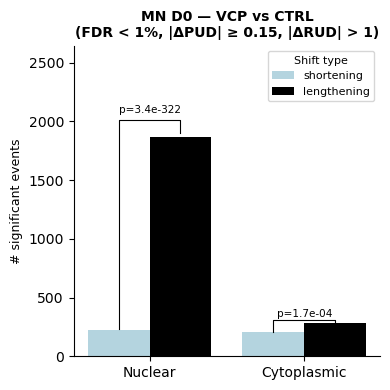

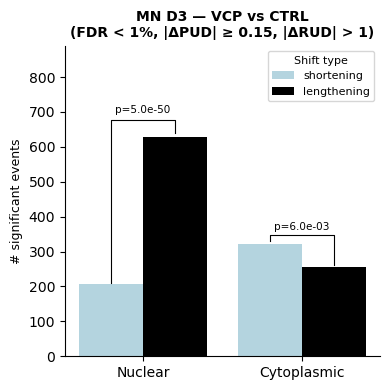

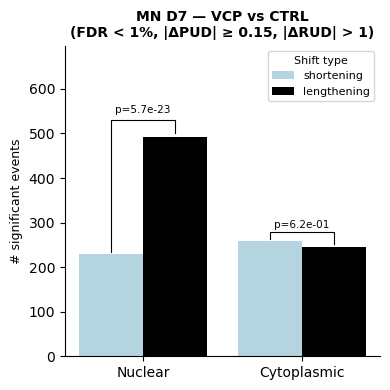

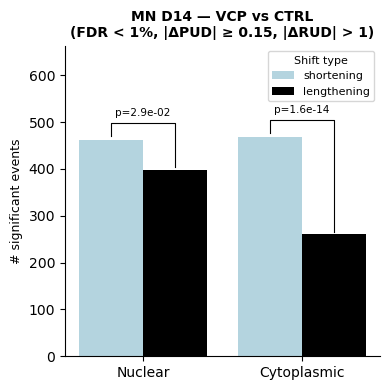

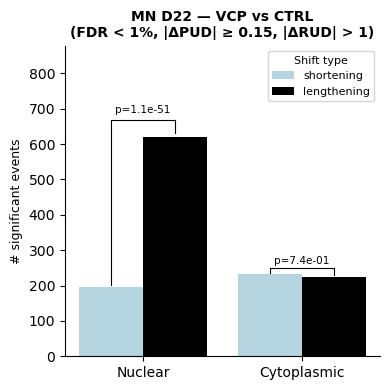

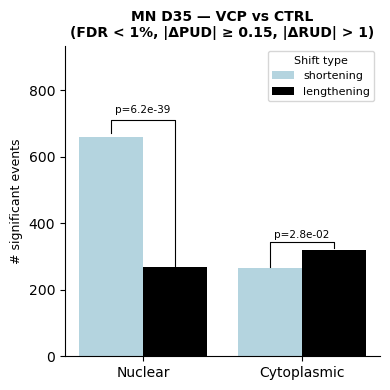

In [4]:

for day in ["D0", "D3", "D7", "D14", "D22", "D35"]:

    volcano_pairs = [
        (f"{day}_Nuclear_Wildtype",     f"{day}_Nuclear_VCP",     f"Nuclear — {day}\nVCP vs CTRL"),
        (f"{day}_Cytoplasmic_Wildtype", f"{day}_Cytoplasmic_VCP", f"Cytoplasmic — {day}\nVCP vs CTRL"),
    ]
    # Barplot: significant shortening vs lengthening — MN, VCP vs CTRL at this day
    mn_sig_counts = []
    for t1, t2, title in volcano_pairs:
        suffix       = f"{t1}_{t2}"
        adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
        pud_t1_col   = f"PUD_{t1}"
        pud_t2_col   = f"PUD_{t2}"
        rud_t1_col   = f"RUD_{t1}"
        rud_t2_col   = f"RUD_{t2}"

        cols = [adj_pval_col, pud_t1_col, pud_t2_col]
        if rud_t1_col in df_mn.columns and rud_t2_col in df_mn.columns:
            cols += [rud_t1_col, rud_t2_col]
        plot_df = df_mn[cols].dropna().copy()
        plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
        if rud_t1_col in df_mn.columns and rud_t2_col in df_mn.columns:
            plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
            rud_mask = plot_df["delta_RUD"].abs() > 1
        else:
            rud_mask = pd.Series(True, index=plot_df.index)

        n_short = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask).sum())
        n_long  = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask).sum())
        fraction = "Nuclear" if "Nuclear" in t2 else "Cytoplasmic"
        mn_sig_counts.append({"fraction": fraction, "shortening": n_short, "lengthening": n_long})

    counts_mn = pd.DataFrame(mn_sig_counts)
    counts_mn_long = counts_mn.melt(
        id_vars="fraction",
        value_vars=["shortening", "lengthening"],
        var_name="shift_type",
        value_name="n_events",
    )

    palette_shift = {"shortening": "lightblue", "lengthening": "black"}
    fraction_order_mn = [f for f in ["Nuclear", "Cytoplasmic"] if f in counts_mn["fraction"].values]

    fig, ax = plt.subplots(figsize=(4, 4))
    sns.barplot(
        data=counts_mn_long,
        x="fraction",
        y="n_events",
        hue="shift_type",
        palette=palette_shift,
        order=fraction_order_mn,
        hue_order=["shortening", "lengthening"],
        ax=ax,
    )

    # Binomial test annotation per fraction
    patches = sorted(ax.patches, key=lambda p: p.get_x())
    for frac_idx, fraction in enumerate(fraction_order_mn):
        row = counts_mn[counts_mn["fraction"] == fraction]
        if row.empty:
            continue
        n_s = int(row["shortening"].values[0])
        n_l = int(row["lengthening"].values[0])
        total = n_s + n_l
        if total == 0:
            continue
        binom_result = stats.binomtest(n_s, total, p=0.5, alternative="two-sided")
        pval_label = f"p={binom_result.pvalue:.1e}"

        p_short = patches[frac_idx * 2]
        p_long  = patches[frac_idx * 2 + 1]
        x_s = p_short.get_x() + p_short.get_width() / 2
        x_l = p_long.get_x()  + p_long.get_width()  / 2
        h_s = p_short.get_height()
        h_l = p_long.get_height()
        y_top = max(h_s, h_l) * 1.08
        ax.plot([x_s, x_s, x_l, x_l], [h_s * 1.02, y_top, y_top, h_l * 1.02],
                color="black", lw=0.8)
        ax.text((x_s + x_l) / 2, y_top * 1.02, pval_label,
                ha="center", va="bottom", fontsize=7.5)

    ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
    ax.set_xlabel("")
    ax.set_ylabel("# significant events", fontsize=9)
    ax.set_title(f"MN {day} — VCP vs CTRL\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)", fontsize=10, weight="bold")
    ax.legend(title="Shift type", fontsize=8, title_fontsize=8)
    sns.despine(ax=ax)
    plt.tight_layout()

    save_figure(f"{figures_subfolder}/MN_3UTR_shifts_VCP_vs_CTRL/barplot_shortening_vs_lengthening_VCP_vs_CTRL_{day}.pdf",
                legend=f"Number of significant 3'UTR shortening (light blue; dPUD (VCP - CTRL) >= 0.15) and "
                    f"lengthening (black; dPUD <= -0.15) events in VCP vs CTRL motor neurons at {day} (adj. Fisher p < 0.01, "
                    "|dRUD| > 1), nuclear and cytoplasmic fractions. p = two-sided binomial test, shortening vs "
                    "lengthening (H0: 50/50).")
    plt.show()


<a id="maturation-vs-vcp-overlap"></a>
## Overlap between 3'UTRs lengthened during maturation and shortened in VCP

Venn diagram comparing 3'UTRs lengthened between D22 and D35 in CTRL nuclei with 3'UTRs shortened in VCP vs CTRL nuclei at D35 (significant on both PUD and RUD), with a hypergeometric test. This cell defines `lengthening_events_upon_TD` and `shortening_events_in_VCP`, which the pathway analyses use.

Saved: `MN_maturation_lengthening_vs_VCP_shortening/venn_nuclear_lengthening_D22_to_D35_vs_shortening_VCP_D35.pdf`.

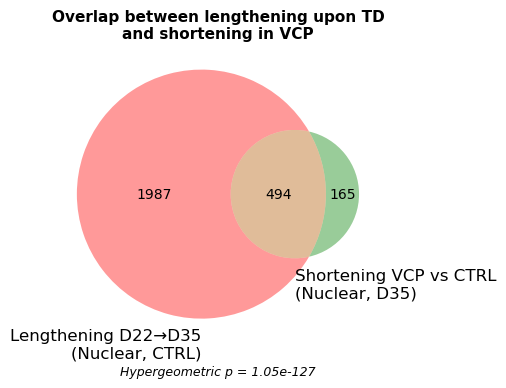

Lengthening upon TD: 2481
Shortening in VCP:   659
Common:              494
Hypergeometric p:    1.05e-127
Fold enrichment:     2.38x


In [5]:

lengthening_events_upon_TD = df_mn[(df_mn["PUD_significance_D22_Nuclear_Wildtype_D35_Nuclear_Wildtype"] == 'Significant distal shift') & (df_mn["RUD_significance_D22_Nuclear_Wildtype_D35_Nuclear_Wildtype"] == 'Significant distal shift')]
shortening_events_in_VCP = df_mn[(df_mn["PUD_significance_D35_Nuclear_Wildtype_D35_Nuclear_VCP"] == 'Significant proximal shift') & (df_mn["RUD_significance_D35_Nuclear_Wildtype_D35_Nuclear_VCP"] == 'Significant proximal shift')]


from matplotlib_venn import venn2
from scipy.stats import hypergeom

set_len  = set(lengthening_events_upon_TD.index)
set_short = set(shortening_events_in_VCP.index)

N = len(df_mn)
K = len(shortening_events_in_VCP)
n = len(lengthening_events_upon_TD)
k = len(set_len & set_short)

p_value = hypergeom.sf(k - 1, N, K, n)
expected = n * K / N
enrichment = k / expected

fig, ax = plt.subplots(figsize=(5, 4))
v = venn2(
    [set_len, set_short],
    set_labels=("Lengthening D22→D35\n(Nuclear, CTRL)", "Shortening VCP vs CTRL\n(Nuclear, D35)"),
    ax=ax,
)
plt.title("Overlap between lengthening upon TD\nand shortening in VCP", fontsize=11, weight="bold")
ax.text(0.5, -0.08,
        f"Hypergeometric p = {p_value:.2e}",
        ha="center", va="top", transform=ax.transAxes, fontsize=9, style="italic")
plt.tight_layout()




save_figure(f"{figures_subfolder}/MN_maturation_lengthening_vs_VCP_shortening/venn_nuclear_lengthening_D22_to_D35_vs_shortening_VCP_D35.pdf",
            legend="Overlap between the 3'UTR pairs lengthened from D22 to D35 in CTRL nuclei (distal shift "
                   "in both the PUD and RUD significance calls) and the pairs shortened in VCP vs CTRL nuclei at D35 "
                   "(proximal shift). One-sided hypergeometric test for enrichment; background = all pairs of the table.")
plt.show()

print(f"Lengthening upon TD: {len(set_len)}")
print(f"Shortening in VCP:   {len(set_short)}")
print(f"Common:              {k}")
print(f"Hypergeometric p:    {p_value:.2e}")
print(f"Fold enrichment:     {enrichment:.2f}x")


<a id="vcp-ki-vs-wt"></a>
## 3'UTR shifts in VCP knock-in vs wild-type cells

Number of significant shortening and lengthening events in untreated VCP-KI vs untreated WT, per fraction. This cell also defines `_count_shifts` and `_shift_barplot`, which the next panel reuses.

Saved: `VCP-KI_3UTR_shifts/barplot_shortening_vs_lengthening_VCP-KI_vs_WT.pdf`.

In [6]:
df_ki = pd.read_csv(f"{PROJECT_DIR}/VCP-KI-Ml240/results/3UTR_analysis/table_of_pairs.csv", index_col=0)

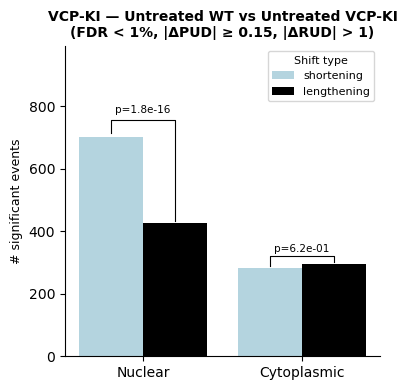

In [7]:
# ── df_ki: VCP-KI-Ml240 — barplots of significant shifts ────────────────────

def _count_shifts(df, t1, t2, fdr=0.01, pud_thresh=0.15, rud_thresh=1):
    suffix = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col, pud_t2_col = f"PUD_{t1}", f"PUD_{t2}"
    rud_t1_col, rud_t2_col = f"RUD_{t1}", f"RUD_{t2}"

    cols = [adj_pval_col, pud_t1_col, pud_t2_col]
    if rud_t1_col in df.columns and rud_t2_col in df.columns:
        cols += [rud_t1_col, rud_t2_col]
    plot_df = df[cols].dropna().copy()
    plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    if rud_t1_col in df.columns and rud_t2_col in df.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > rud_thresh
    else:
        rud_mask = pd.Series(True, index=plot_df.index)

    n_short = int(((plot_df[adj_pval_col] < fdr) & (plot_df["delta_PUD"] >=  pud_thresh) & rud_mask).sum())
    n_long  = int(((plot_df[adj_pval_col] < fdr) & (plot_df["delta_PUD"] <= -pud_thresh) & rud_mask).sum())
    return n_short, n_long


def _shift_barplot(df, pairs, title, out_subdir, out_name, legend):
    """pairs: list of (t1, t2, fraction_label). One bar group per fraction,
    hue = shift type, with a binomial-test p-value annotated per fraction
    (same style as the MN_diff / Astrocytes barplots above).
    """
    records = []
    for t1, t2, fraction in pairs:
        n_short, n_long = _count_shifts(df, t1, t2)
        records.append({"fraction": fraction, "shortening": n_short, "lengthening": n_long})
    counts = pd.DataFrame(records)
    counts_long = counts.melt(id_vars="fraction", value_vars=["shortening", "lengthening"],
                               var_name="shift_type", value_name="n_events")

    fraction_order = [f for f in ["Nuclear", "Cytoplasmic"] if f in counts["fraction"].values]

    fig, ax = plt.subplots(figsize=(4, 4))
    sns.barplot(data=counts_long, x="fraction", y="n_events", hue="shift_type",
                palette={"shortening": "lightblue", "lengthening": "black"},
                order=fraction_order, hue_order=["shortening", "lengthening"], ax=ax)

    patches = sorted(ax.patches, key=lambda p: p.get_x())
    for frac_idx, fraction in enumerate(fraction_order):
        row = counts[counts["fraction"] == fraction]
        n_s, n_l = int(row["shortening"].values[0]), int(row["lengthening"].values[0])
        total = n_s + n_l
        if total == 0:
            continue
        binom_result = stats.binomtest(n_s, total, p=0.5, alternative="two-sided")
        pval_label = f"p={binom_result.pvalue:.1e}"
        p_short, p_long = patches[frac_idx * 2], patches[frac_idx * 2 + 1]
        x_s, x_l = p_short.get_x() + p_short.get_width() / 2, p_long.get_x() + p_long.get_width() / 2
        h_s, h_l = p_short.get_height(), p_long.get_height()
        y_top = max(h_s, h_l) * 1.08
        ax.plot([x_s, x_s, x_l, x_l], [h_s * 1.02, y_top, y_top, h_l * 1.02], color="black", lw=0.8)
        ax.text((x_s + x_l) / 2, y_top * 1.02, pval_label, ha="center", va="bottom", fontsize=7.5)

    ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
    ax.set_xlabel("")
    ax.set_ylabel("# significant events", fontsize=9)
    ax.set_title(title, fontsize=10, weight="bold")
    ax.legend(title="Shift type", fontsize=8, title_fontsize=8)
    sns.despine(ax=ax)
    plt.tight_layout()

    out_dir = os.path.join(figures_subfolder, out_subdir)
    os.makedirs(out_dir, exist_ok=True)
    save_figure(os.path.join(out_dir, out_name), legend=legend)
    plt.show()
    return counts


ki_comparison_pairs_wt_vs_ki = [
    ("Untreated_WT_Nuc",  "Untreated_VCP_KI_Nuc",  "Nuclear"),
    ("Untreated_WT_Cyto", "Untreated_VCP_KI_Cyto", "Cytoplasmic"),
]
counts_wt_vs_ki = _shift_barplot(
    df_ki, ki_comparison_pairs_wt_vs_ki,
    "VCP-KI — Untreated WT vs Untreated VCP-KI\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)",
    "VCP-KI_3UTR_shifts", "barplot_shortening_vs_lengthening_VCP-KI_vs_WT.pdf",
    legend="Number of significant 3'UTR shortening (light blue) and lengthening (black) events in untreated VCP knock-in vs untreated WT cells (VCP-KI +- ML240 dataset), nuclear and cytoplasmic fractions (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1). p = two-sided binomial test, shortening vs lengthening.",
)


<a id="vcp-ki-ml240"></a>
## 3'UTR shifts after ML240 treatment of VCP knock-in cells

Same barplot, comparing untreated VCP-KI with ML240-treated VCP-KI.

Saved: `VCP-KI_3UTR_shifts/barplot_shortening_vs_lengthening_ML240_vs_untreated_VCP-KI.pdf`.

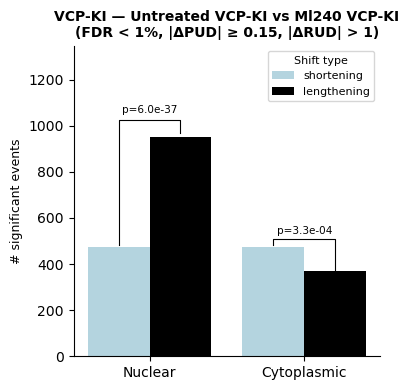

In [8]:
ki_comparison_pairs_ki_vs_ml240 = [
    ("Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc",  "Nuclear"),
    ("Untreated_VCP_KI_Cyto", "Ml240_VCP_KI_Cyto", "Cytoplasmic"),
]
counts_ki_vs_ml240 = _shift_barplot(
    df_ki, ki_comparison_pairs_ki_vs_ml240,
    "VCP-KI — Untreated VCP-KI vs Ml240 VCP-KI\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)",
    "VCP-KI_3UTR_shifts", "barplot_shortening_vs_lengthening_ML240_vs_untreated_VCP-KI.pdf",
    legend="Number of significant 3'UTR shortening (light blue) and lengthening (black) events in ML240-treated vs untreated VCP knock-in cells (VCP-KI +- ML240 dataset), nuclear and cytoplasmic fractions (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1). p = two-sided binomial test, shortening vs lengthening.",
)


<a id="rbp-kd-shifts"></a>
## 3'UTR shifts upon TDP-43 / FUS / SFPQ knockdown

Two knockdown datasets: ENCODE knockdowns in two cell lines, and SFPQ / TDP-43 / FUS knockdowns with nuclear and cytoplasmic fractions.

<a id="encode-kd"></a>
### ENCODE knockdowns in K562 and HepG2

Number of significant proximal vs distal shifts upon TARDBP, FUS and SFPQ knockdown in K562 (first cell) and HepG2 (second cell).

Saved in `ENCODE_KD_3UTR_shifts/`: `barplot_proximal_vs_distal_TARDBP_FUS_SFPQ_KD_K562.pdf` and `barplot_proximal_vs_distal_TARDBP_FUS_SFPQ_KD_HepG2.pdf`.

FUS: 2838 proximal, 4501 distal
SFPQ: 2292 proximal, 1382 distal


TARDBP: 1538 proximal, 2258 distal


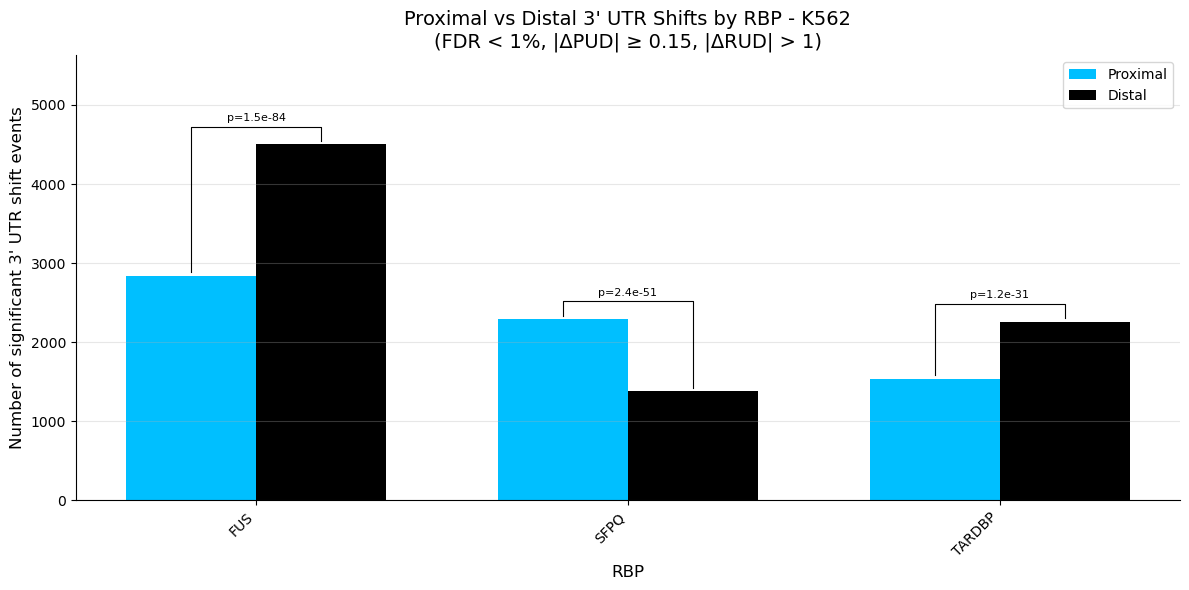

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import seaborn as sns

import matplotlib


# Get all RBP folders
ENCODE_RESULTS_DIR = f"{PROJECT_DIR}/ENCODE-KD_K562"
rbp_folders = [d for d in Path(ENCODE_RESULTS_DIR).iterdir()
               if d.is_dir() and d.name in ['TARDBP', 'FUS', 'SFPQ']]

# Significant shortening (proximal) / lengthening (distal) events per RBP,
# using the Fisher-test adjusted p-values already computed in table_of_pairs.csv
# (same PUD/RUD/FDR criteria as the other volcano/barplot panels).
records = []
for rbp_folder in sorted(rbp_folders):
    rbp_name = rbp_folder.name
    table_path = rbp_folder / "3UTR_analysis" / "table_of_pairs.csv"

    if not table_path.exists():
        print(f"Warning: {table_path} does not exist")
        continue

    df_rbp = pd.read_csv(table_path, index_col=0)

    t1, t2 = "control", f"{rbp_name}-KD"
    suffix       = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"
    rud_t1_col   = f"RUD_{t1}"
    rud_t2_col   = f"RUD_{t2}"

    if adj_pval_col not in df_rbp.columns or pud_t1_col not in df_rbp.columns or pud_t2_col not in df_rbp.columns:
        print(f"Warning: expected columns not found for {rbp_name}")
        continue

    cols = [adj_pval_col, pud_t1_col, pud_t2_col]
    if rud_t1_col in df_rbp.columns and rud_t2_col in df_rbp.columns:
        cols += [rud_t1_col, rud_t2_col]
    plot_df = df_rbp[cols].dropna().copy()
    plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    if rud_t1_col in df_rbp.columns and rud_t2_col in df_rbp.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1
    else:
        rud_mask = pd.Series(True, index=plot_df.index)

    # delta > 0: more proximal in KD = shortening in KD
    # delta < 0: more distal in KD   = lengthening in KD
    n_proximal = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask).sum())
    n_distal   = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask).sum())

    records.append({"rbp": rbp_name, "proximal": n_proximal, "distal": n_distal})
    print(f"{rbp_name}: {n_proximal} proximal, {n_distal} distal")

counts_df = pd.DataFrame(records)

# Create barplot
fig, ax = plt.subplots(figsize=(12, 6))

rbps = counts_df["rbp"].tolist()
x = range(len(rbps))
width = 0.35

proximal_vals = counts_df.set_index("rbp")["proximal"]
distal_vals   = counts_df.set_index("rbp")["distal"]

# Plot bars
bars_proximal = ax.bar([i - width/2 for i in x], [proximal_vals[rbp] for rbp in rbps],
                        width, label='Proximal', color='deepskyblue')
bars_distal   = ax.bar([i + width/2 for i in x], [distal_vals[rbp] for rbp in rbps],
                        width, label='Distal', color='black')

# Binomial test annotation per RBP (proximal vs distal counts)
y_max = max(list(proximal_vals) + list(distal_vals))
for i, rbp in enumerate(rbps):
    n_p = int(proximal_vals[rbp])
    n_d = int(distal_vals[rbp])
    total = n_p + n_d
    if total == 0:
        continue
    binom_result = stats.binomtest(n_p, total, p=0.5, alternative="two-sided")
    pval_label = f"p={binom_result.pvalue:.1e}"

    x_p = bars_proximal[i].get_x() + bars_proximal[i].get_width() / 2
    x_d = bars_distal[i].get_x()   + bars_distal[i].get_width()   / 2
    h_p = bars_proximal[i].get_height()
    h_d = bars_distal[i].get_height()
    y_top = max(h_p, h_d) + y_max * 0.05
    ax.plot([x_p, x_p, x_d, x_d],
            [h_p + y_max * 0.01, y_top, y_top, h_d + y_max * 0.01],
            color="black", lw=0.8)
    ax.text((x_p + x_d) / 2, y_top + y_max * 0.01, pval_label,
            ha="center", va="bottom", fontsize=8)

# Customize plot
ax.set_xlabel('RBP', fontsize=12)
ax.set_ylabel('Number of significant 3\' UTR shift events', fontsize=12)
ax.set_title("Proximal vs Distal 3' UTR Shifts by RBP - K562\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(rbps, rotation=45, ha='right')
ax.set_ylim(0, y_max * 1.25)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
sns.despine()

save_figure(f"{figures_subfolder}/ENCODE_KD_3UTR_shifts/barplot_proximal_vs_distal_TARDBP_FUS_SFPQ_KD_K562.pdf",
            legend="ENCODE knockdowns in K562: number of significant proximal (blue, "
                   "shortening) and distal (black, lengthening) 3'UTR shifts upon FUS, SFPQ and TARDBP knockdown vs "
                   "control (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1). p = two-sided binomial test, proximal vs distal.")
plt.show()


FUS: 1616 proximal, 3018 distal
SFPQ: 3523 proximal, 2834 distal


TARDBP: 2949 proximal, 2802 distal


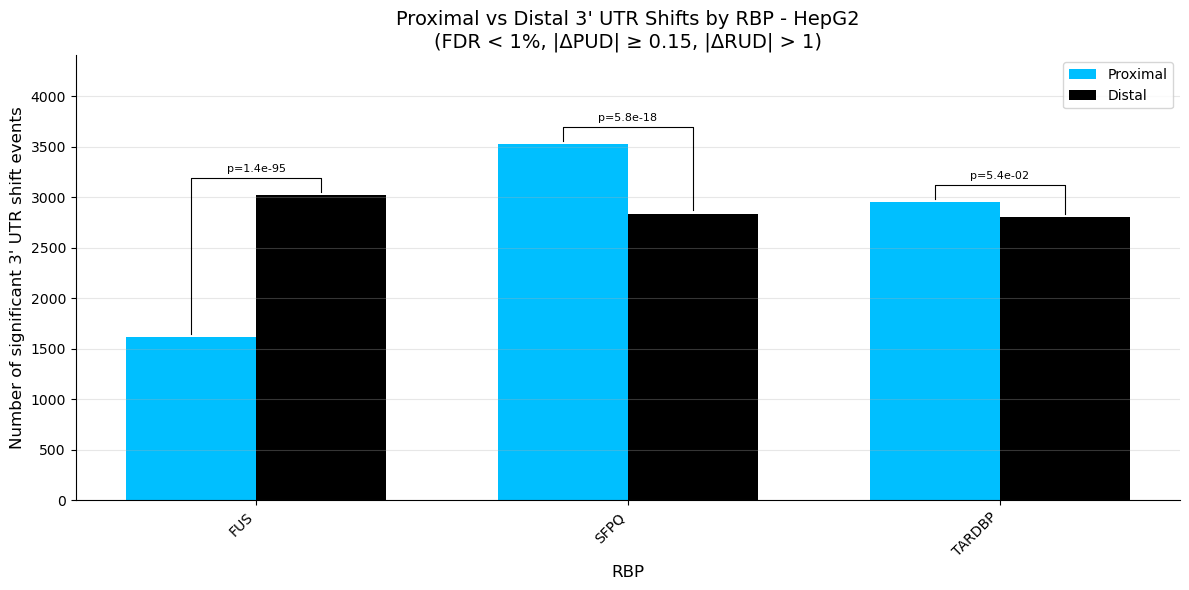

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import seaborn as sns

import matplotlib



# Get all RBP folders
ENCODE_RESULTS_DIR = f"{PROJECT_DIR}/ENCODE-KD_HepG2"
rbp_folders = [d for d in Path(ENCODE_RESULTS_DIR).iterdir()
               if d.is_dir() and d.name in ['TARDBP', 'FUS', 'SFPQ']]

# Significant shortening (proximal) / lengthening (distal) events per RBP,
# using the Fisher-test adjusted p-values already computed in table_of_pairs.csv
# (same PUD/RUD/FDR criteria as the other volcano/barplot panels).
records = []
for rbp_folder in sorted(rbp_folders):
    rbp_name = rbp_folder.name
    table_path = rbp_folder / "3UTR_analysis" / "table_of_pairs.csv"

    if not table_path.exists():
        print(f"Warning: {table_path} does not exist")
        continue

    df_rbp = pd.read_csv(table_path, index_col=0)

    t1, t2 = "control", f"{rbp_name}-KD"
    suffix       = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"
    rud_t1_col   = f"RUD_{t1}"
    rud_t2_col   = f"RUD_{t2}"

    if adj_pval_col not in df_rbp.columns or pud_t1_col not in df_rbp.columns or pud_t2_col not in df_rbp.columns:
        print(f"Warning: expected columns not found for {rbp_name}")
        continue

    cols = [adj_pval_col, pud_t1_col, pud_t2_col]
    if rud_t1_col in df_rbp.columns and rud_t2_col in df_rbp.columns:
        cols += [rud_t1_col, rud_t2_col]
    plot_df = df_rbp[cols].dropna().copy()
    plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    if rud_t1_col in df_rbp.columns and rud_t2_col in df_rbp.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1
    else:
        rud_mask = pd.Series(True, index=plot_df.index)

    # delta > 0: more proximal in KD = shortening in KD
    # delta < 0: more distal in KD   = lengthening in KD
    n_proximal = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask).sum())
    n_distal   = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask).sum())

    records.append({"rbp": rbp_name, "proximal": n_proximal, "distal": n_distal})
    print(f"{rbp_name}: {n_proximal} proximal, {n_distal} distal")

counts_df = pd.DataFrame(records)

# Create barplot
fig, ax = plt.subplots(figsize=(12, 6))

rbps = counts_df["rbp"].tolist()
x = range(len(rbps))
width = 0.35

proximal_vals = counts_df.set_index("rbp")["proximal"]
distal_vals   = counts_df.set_index("rbp")["distal"]

# Plot bars
bars_proximal = ax.bar([i - width/2 for i in x], [proximal_vals[rbp] for rbp in rbps],
                        width, label='Proximal', color='deepskyblue')
bars_distal   = ax.bar([i + width/2 for i in x], [distal_vals[rbp] for rbp in rbps],
                        width, label='Distal', color='black')

# Binomial test annotation per RBP (proximal vs distal counts)
y_max = max(list(proximal_vals) + list(distal_vals))
for i, rbp in enumerate(rbps):
    n_p = int(proximal_vals[rbp])
    n_d = int(distal_vals[rbp])
    total = n_p + n_d
    if total == 0:
        continue
    binom_result = stats.binomtest(n_p, total, p=0.5, alternative="two-sided")
    pval_label = f"p={binom_result.pvalue:.1e}"

    x_p = bars_proximal[i].get_x() + bars_proximal[i].get_width() / 2
    x_d = bars_distal[i].get_x()   + bars_distal[i].get_width()   / 2
    h_p = bars_proximal[i].get_height()
    h_d = bars_distal[i].get_height()
    y_top = max(h_p, h_d) + y_max * 0.05
    ax.plot([x_p, x_p, x_d, x_d],
            [h_p + y_max * 0.01, y_top, y_top, h_d + y_max * 0.01],
            color="black", lw=0.8)
    ax.text((x_p + x_d) / 2, y_top + y_max * 0.01, pval_label,
            ha="center", va="bottom", fontsize=8)

# Customize plot
ax.set_xlabel('RBP', fontsize=12)
ax.set_ylabel('Number of significant 3\' UTR shift events', fontsize=12)
ax.set_title("Proximal vs Distal 3' UTR Shifts by RBP - HepG2\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(rbps, rotation=45, ha='right')
ax.set_ylim(0, y_max * 1.25)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
sns.despine()

save_figure(f"{figures_subfolder}/ENCODE_KD_3UTR_shifts/barplot_proximal_vs_distal_TARDBP_FUS_SFPQ_KD_HepG2.pdf",
            legend="ENCODE knockdowns in HepG2: number of significant proximal (blue, "
                   "shortening) and distal (black, lengthening) 3'UTR shifts upon FUS, SFPQ and TARDBP knockdown vs "
                   "control (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1). p = two-sided binomial test, proximal vs distal.")
plt.show()


<a id="sfpq-tdp43-fus-kd"></a>
### SFPQ / TDP-43 / FUS knockdown, nuclear and cytoplasmic fractions

The first cell loads the KD table of pairs (`df`). The second cell draws volcano plots for each KD vs untreated, per fraction, and defines `comparison_pairs`. The third cell plots the number of significant shortening and lengthening events per KD and fraction.

Saved in `SFPQ_TDP43_FUS_KD_3UTR_shifts/`: `volcano_dPUD_KD_vs_untreated_per_fraction.pdf` and `barplot_shortening_vs_lengthening_KD_vs_untreated_per_fraction.pdf`.

In [11]:
df = pd.read_csv(f"{PROJECT_DIR}/SFPQ_TDP_FUS_KD/results/3UTR_analysis/table_of_pairs.csv", index_col=0)

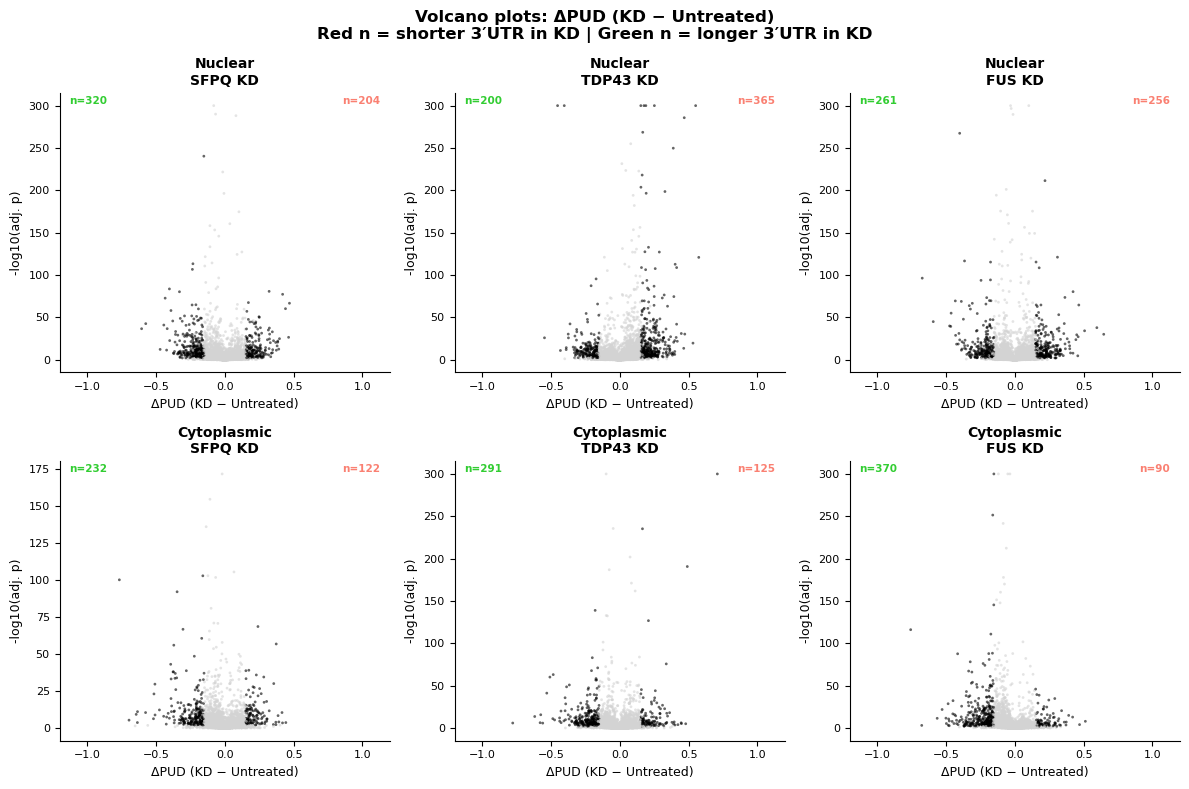

In [12]:

import numpy as np
import matplotlib.pyplot as plt

# Define (t1, t2, subplot title) for each comparison
comparison_pairs = [
    ("Untreated_Nuc",  "SFPQ_KD_Nuc",   "Nuclear\nSFPQ KD"),
    ("Untreated_Nuc",  "TDP43_KD_Nuc",  "Nuclear\nTDP43 KD"),
    ("Untreated_Nuc",  "FUS_KD_Nuc",    "Nuclear\nFUS KD"),
    ("Untreated_Cyto", "SFPQ_KD_Cyto",  "Cytoplasmic\nSFPQ KD"),
    ("Untreated_Cyto", "TDP43_KD_Cyto", "Cytoplasmic\nTDP43 KD"),
    ("Untreated_Cyto", "FUS_KD_Cyto",   "Cytoplasmic\nFUS KD"),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for idx, (t1, t2, title) in enumerate(comparison_pairs):
    row_idx = idx // 3
    col_idx = idx % 3
    ax = axes[row_idx, col_idx]

    suffix = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"
    rud_t1_col   = f"RUD_{t1}"
    rud_t2_col   = f"RUD_{t2}"

    if adj_pval_col not in df.columns or pud_t1_col not in df.columns or pud_t2_col not in df.columns:
        ax.text(0.5, 0.5, "not found", ha="center", va="center",
                transform=ax.transAxes, fontsize=9)
        ax.set_title(title, fontsize=10, weight="bold")
        sns.despine(ax=ax)
        continue

    plot_df = df[[adj_pval_col, pud_t1_col, pud_t2_col, rud_t1_col, rud_t2_col]].dropna().copy()
    plot_df["delta_PUD"]       = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    plot_df["neg_log10_pval"]  = -np.log10(plot_df[adj_pval_col].clip(lower=1e-300))
    
    rud_mask = pd.Series(True, index=plot_df.index)
    if rud_t1_col in df.columns and rud_t2_col in df.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1

    sig_short = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask
    sig_long  = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask
    sig_any   = sig_short | sig_long
    colors = sig_any.map({True: "black", False: "lightgray"})

    ax.scatter(plot_df["delta_PUD"], plot_df["neg_log10_pval"],
               c=colors, s=4, alpha=0.6, linewidths=0)
    ax.set_xlabel("ΔPUD (KD − Untreated)", fontsize=9)
    ax.set_ylabel("-log10(adj. p)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_title(title, fontsize=10, weight="bold")
    ax.set_xlim(-1.2, 1.2)

    n_short = sig_short.sum()
    n_long  = sig_long.sum()
    ax.text(0.97, 0.99, f"n={n_short}", color="salmon", fontsize=7.5, weight="bold",
            ha="right", va="top", transform=ax.transAxes)
    ax.text(0.03, 0.99, f"n={n_long}", color="limegreen", fontsize=7.5, weight="bold",
            ha="left", va="top", transform=ax.transAxes)
    sns.despine(ax=ax)

plt.suptitle(
    "Volcano plots: ΔPUD (KD − Untreated)\nRed n = shorter 3′UTR in KD | Green n = longer 3′UTR in KD",
    fontsize=12, weight="bold",
)
plt.tight_layout()



save_figure(f"{figures_subfolder}/SFPQ_TDP43_FUS_KD_3UTR_shifts/volcano_dPUD_KD_vs_untreated_per_fraction.pdf",
            legend="SFPQ, TDP-43 and FUS knockdown vs untreated cells, nuclear (top) and cytoplasmic (bottom) fractions: "
                   "volcano plots of dPUD (KD - untreated) vs -log10(adjusted Fisher p); black = significant (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1); "
                   "n = significant pairs shorter (right, red) or longer (left, green) in the KD.")
plt.show()

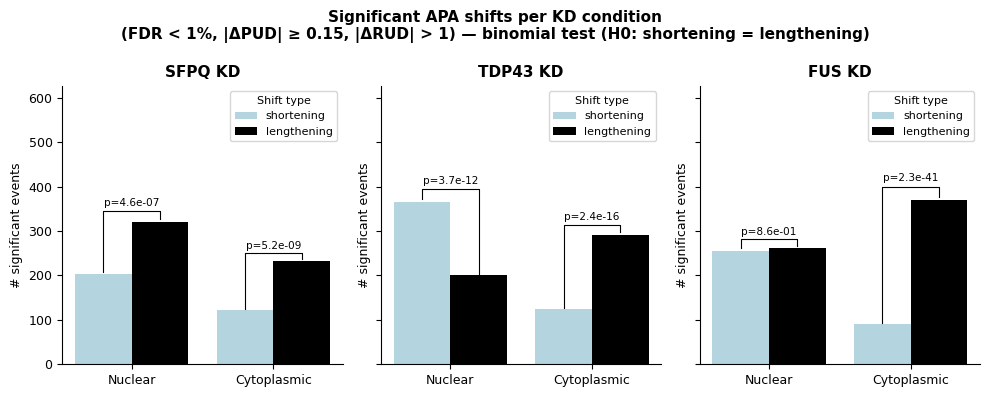

In [13]:
# 
# Collect event counts per comparison
records = []
for t1, t2, title in comparison_pairs:
    suffix = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"

    if adj_pval_col not in df.columns or pud_t1_col not in df.columns or pud_t2_col not in df.columns:
        continue

    rud_t1_col = f"RUD_{t1}"
    rud_t2_col = f"RUD_{t2}"
    cols = [adj_pval_col, pud_t1_col, pud_t2_col]
    if rud_t1_col in df.columns and rud_t2_col in df.columns:
        cols += [rud_t1_col, rud_t2_col]
    plot_df = df[cols].dropna().copy()
    plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    if rud_t1_col in df.columns and rud_t2_col in df.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1
    else:
        rud_mask = pd.Series(True, index=plot_df.index)

    n_short = ((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask).sum()
    n_long  = ((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask).sum()

    fraction  = "Nuclear" if "Nuc" in t2 else "Cytoplasmic"
    condition = title.split("\n")[1]  # e.g. "SFPQ KD"

    records.append({"comparison": condition, "fraction": fraction, "shortening": n_short, "lengthening": n_long})

counts_df = pd.DataFrame(records)

# Melt to long form
counts_long = counts_df.melt(
    id_vars=["comparison", "fraction"],
    value_vars=["shortening", "lengthening"],
    var_name="shift_type",
    value_name="n_events",
)

palette_shift = {"shortening": "lightblue", "lengthening": "black"}
comparison_order = ["SFPQ KD", "TDP43 KD", "FUS KD"]

# 3 rows (one per KD) × 2 cols (Nuclear / Cytoplasmic)
kd_order = ["SFPQ KD", "TDP43 KD", "FUS KD"]
fraction_order = ["Nuclear", "Cytoplasmic"]

# 1 row per KD, x = fraction (Nuclear / Cyto), hue = shift type
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey=True)

for col_idx, kd in enumerate(kd_order):
    ax = axes[col_idx]
    sub = counts_long[counts_long["comparison"] == kd]

    sns.barplot(
        data=sub,
        x="fraction",
        y="n_events",
        hue="shift_type",
        palette=palette_shift,
        order=fraction_order,
        hue_order=["shortening", "lengthening"],
        ax=ax,
    )

    ax.set_title(kd, fontsize=11, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("# significant events", fontsize=9)
    ax.tick_params(labelsize=9)
    ax.legend(title="Shift type", fontsize=8, title_fontsize=8)
    sns.despine(ax=ax)

    # Add binomial test annotation for each fraction
    patches = sorted(ax.patches, key=lambda p: p.get_x())

    for frac_idx, fraction in enumerate(fraction_order):
        p_short = patches[frac_idx * 2]
        p_long  = patches[frac_idx * 2 + 1]

        row = counts_df[(counts_df["comparison"] == kd) & (counts_df["fraction"] == fraction)]
        if row.empty:
            continue
        n_s = int(row["shortening"].values[0])
        n_l = int(row["lengthening"].values[0])
        total = n_s + n_l
        if total == 0:
            continue

        binom_result = stats.binomtest(n_s, total, p=0.5, alternative="two-sided")
        pval_label = f"p={binom_result.pvalue:.1e}"

        x_s = p_short.get_x() + p_short.get_width() / 2
        x_l = p_long.get_x()  + p_long.get_width()  / 2
        h_s = p_short.get_height()
        h_l = p_long.get_height()

        y_top  = max(h_s, h_l) * 1.08
        y_text = y_top * 1.02
        ax.plot([x_s, x_s, x_l, x_l], [h_s * 1.02, y_top, y_top, h_l * 1.02],
                color="black", lw=0.8)
        ax.text((x_s + x_l) / 2, y_text, pval_label,
                ha="center", va="bottom", fontsize=7.5)

    ax.set_ylim(0, ax.get_ylim()[1] * 1.2)

plt.suptitle(
    "Significant APA shifts per KD condition\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1) — binomial test (H0: shortening = lengthening)",
    fontsize=11, weight="bold",
)
plt.tight_layout()


save_figure(f"{figures_subfolder}/SFPQ_TDP43_FUS_KD_3UTR_shifts/barplot_shortening_vs_lengthening_KD_vs_untreated_per_fraction.pdf",
            legend="Number of significant 3'UTR shortening (light blue) and lengthening (black) events "
                   "upon SFPQ, TDP-43 and FUS knockdown vs untreated cells, nuclear and cytoplasmic fractions (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1). "
                   "p = two-sided binomial test, shortening vs lengthening.")
plt.show()


<a id="vcp-shortening-go"></a>
## Biological processes enriched among genes with 3'UTRs shortened in VCP

The first cell gets the STRING v12.5 GO enrichment of the two gene sets from the overlap panel (lengthened during maturation, shortened in VCP) from the raw responses archived in `cache/STRING_v12.5_responses/` (it stops with an error if they are missing, rather than querying STRING again), defines the term-curation helpers (`_extract`, `select_top_nonredundant`) and fixes the plotted terms to those of the 2026-10-13 version of the figure. The second cell draws the bubble plot comparing both lists with their v12.5 values (it defines `plot_go_bubble`, `_to_long` and `mcolors`, which later cells use). Two reference cells follow: the 2026-10-13 figure, made from STRING's live site, which cannot be regenerated (STRING's results for these genes have changed since) and is displayed from its PDF; and STRING v12.5's own top 10 non-redundant terms per list among the terms with at least 10 genes of the list (the rule that picked the 2026-10-13 terms, plus that size filter). The next cell writes every significant term (FDR < 0.05) of both lists, with their genes, to `Tables/Figure_3UTR_CTRL_vs_VCP/bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35_significant_terms.xlsx`, flagging the plotted ones. The last cell draws the barplot of the top terms of the VCP-shortened genes only.

Saved in `MN_pathway_enrichment/`: `bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35.pdf` (both lists), `../cache/reference_figures/bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35_STRING_live_2026-10-13.pdf` (reference, not regenerated; read, not saved), `bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35_STRING_v12.5_top10_min10genes.pdf` (reference) and `barplot_GO_BP_VCP_shortening_D35.pdf` (VCP-shortened genes).

In [14]:
from utrals.string_api import get_string_enrichment, get_string_enrichment_cached, add_strength_and_signal, to_pathways_format
from utrals import string_api
# Pin the STRING release: the default string-db.org address follows the latest release, whose results
# drift (same genes: 286 Lengthening GO terms on 2026-10-13, 475 on 2026-10-20 with v12.5).
string_api.STRING_API = "https://version-12-5.string-db.org/api/json"
# Every other get_string_enrichment() call of this notebook archives STRING's raw response in ../cache/STRING_v12.5/
# and reads it back on later runs (string_analysis.STRING_CACHE_DIR)
string_api.CACHE_DIR = string_analysis.STRING_CACHE_DIR
# STRING's raw responses are saved in the repository on the first query and read back afterwards,
# so the enrichment below stays reproducible even if STRING's servers change or go offline.
string_responses_dir = "../cache/STRING_v12.5_responses"

# Query STRING (replaces the manually-downloaded pathways/*.tsv files).
# Cache the raw (all-category) results so the COMPARTMENTS/Keyword cells below
# can reuse them without re-querying STRING.
genes_lengthening = sorted(lengthening_events_upon_TD["gene"].dropna().unique())
genes_vcp_shortening = sorted(shortening_events_in_VCP["gene"].dropna().unique())

print(f"Querying STRING for Lengthening ({len(genes_lengthening)} genes)...")
_raw_lengthening = add_strength_and_signal(get_string_enrichment_cached(
    genes_lengthening, f"{string_responses_dir}/lengthening_D22_to_D35_Nuclear_Wildtype.json.gz", query_if_missing=False))
print(f"Querying STRING for VCP shortening ({len(genes_vcp_shortening)} genes)...")
_raw_vcp_shortening = add_strength_and_signal(get_string_enrichment_cached(
    genes_vcp_shortening, f"{string_responses_dir}/shortening_D35_Nuclear_VCP_vs_Wildtype.json.gz", query_if_missing=False))

df_lengthening = to_pathways_format(_raw_lengthening[_raw_lengthening["category"] == "Process"])
df_vcp_shortening = to_pathways_format(_raw_vcp_shortening[_raw_vcp_shortening["category"] == "Process"])

# ── Diagnostic: how many pathways survive the background-count filter? ───────
bg_threshold = 10000
print("=== Lengthening ===")
print(f"  Total rows: {len(df_lengthening)}")
print(f"  After background count < {bg_threshold}: {(df_lengthening['background gene count'] < bg_threshold).sum()}")
print(f"  Removed: {(df_lengthening['background gene count'] >= bg_threshold).sum()}")

print("=== VCP shortening ===")
print(f"  Total rows: {len(df_vcp_shortening)}")
print(f"  After background count < {bg_threshold}: {(df_vcp_shortening['background gene count'] < bg_threshold).sum()}")
print(f"  Removed: {(df_vcp_shortening['background gene count'] >= bg_threshold).sum()}")
print(f"  Removed pathways: {df_vcp_shortening.loc[df_vcp_shortening['background gene count'] >= bg_threshold, 'term description'].tolist()}")

# NOTE: we colour bubbles by "strength" (log10 observed/expected), NOT STRING's
# "signal" column. signal = strength * -log10(FDR), and FDR is mechanically
# smaller for larger input gene lists (more statistical power), so signal
# systematically over-states enrichment for the bigger "Lengthening" gene set
# even when the true effect size (strength) is comparable to "VCP".
def _extract(df, cond, bg_threshold=1000):
    df = df[df["background gene count"] < bg_threshold]
    sub = df[["term description", "strength", "false discovery rate"]].copy()
    sub.columns = ["pathway", f"strength_{cond}", f"fdr_{cond}"]
    sub[f"present_{cond}"] = True
    return sub

def _jaccard(a, b):
    if not a or not b:
        return 0.0
    return len(a & b) / len(a | b)

def select_top_nonredundant(df_pathways, raw_df, top_n=10, jaccard_thresh=0.5, bg_threshold=10000):
    """Rank terms by strength (size-independent effect size) and greedily keep the
    top `top_n`, skipping any term whose STRING member-gene set (preferredNames)
    overlaps an already-kept term above `jaccard_thresh`. GO/Keyword/Compartment
    terms are often near-duplicates (a parent term and its child, e.g. "RNA
    processing" and "mRNA processing", enriched for almost the same genes) — this
    keeps only the strongest/most specific representative of each redundant
    cluster instead of listing every synonym-level term.
    """
    df = df_pathways[df_pathways["background gene count"] < bg_threshold].sort_values("strength", ascending=False)
    gene_sets = raw_df.set_index("term")["preferredNames"].apply(set)

    kept_ids, kept_sets = [], []
    for _, row in df.iterrows():
        gs = gene_sets.get(row["term ID"], set())
        if all(_jaccard(gs, ks) < jaccard_thresh for ks in kept_sets):
            kept_ids.append(row["term ID"])
            kept_sets.append(gs)
        if len(kept_ids) == top_n:
            break
    return df[df["term ID"].isin(kept_ids)]

top_n = 10  # used by the later GO cells

# Rows of the bubble plot = the terms of the 2026-10-13 version of this figure (top 10 non-redundant terms per
# list, by strength, in STRING's live results of that date, which were not saved and can no longer be retrieved;
# see the reference cell below the plot). Fixed here so the plot no longer depends on STRING's ranking.
# Each list = the terms drawn as a bubble for that list in the 2026-10-13 figure.
paper_plot_terms = {
    "Lengthening": ["Negative regulation of synapse assembly", "Regulation of axon extension involved in axon guidance",
                    "Mitochondrion transport along microtubule", "Negative chemotaxis",
                    "Negative regulation of BMP signaling pathway", "Neuron recognition",
                    "Negative regulation of axonogenesis", "Cellular response to nerve growth factor stimulus",
                    "Embryonic digit morphogenesis", "Long-term synaptic potentiation", "Protein modification process",
                    "Cellular localization", "Nervous system development", "Intracellular protein localization",
                    "Negative regulation of macromolecule metabolic process", "Regulation of primary metabolic process"],
    "VCP": ["Localization within membrane", "Protein modification process", "Cellular localization",
            "Nervous system development", "Intracellular protein localization",
            "Negative regulation of macromolecule metabolic process", "Regulation of primary metabolic process"],
}
selected_terms = set(paper_plot_terms["Lengthening"]) | set(paper_plot_terms["VCP"])

# Look up every SELECTED term's true strength/FDR/presence in each condition's full
# (bg_threshold-filtered) enrichment result — not just its own top-N subset. A term
# that makes VCP's top 10 but was ALSO significantly enriched in Lengthening (just
# ranked outside Lengthening's top 10 by strength) must still be plotted as
# "present" for Lengthening. Restricting the lookup to each condition's own top-N
# subset would wrongly draw it as a "not enriched" cross for Lengthening, when in
# fact STRING did return it there — just not among the 10 strongest.
lengthening = _extract(df_lengthening[df_lengthening["term description"].isin(selected_terms)], "Lengthening", bg_threshold)
vcp_shortening = _extract(df_vcp_shortening[df_vcp_shortening["term description"].isin(selected_terms)], "VCP", bg_threshold)
print(f"Selected {len(selected_terms)} unique terms (those of the 2026-10-13 figure)")
print(f"  True presence — Lengthening: {len(lengthening)} / VCP: {len(vcp_shortening)}")


Querying STRING for Lengthening (2481 genes)...


Querying STRING for VCP shortening (659 genes)...
=== Lengthening ===
  Total rows: 475
  After background count < 10000: 471
  Removed: 4
=== VCP shortening ===
  Total rows: 15
  After background count < 10000: 15
  Removed: 0
  Removed pathways: []
Selected 17 unique terms (those of the 2026-10-13 figure)
  True presence — Lengthening: 16 / VCP: 7


Unique pathways: 17


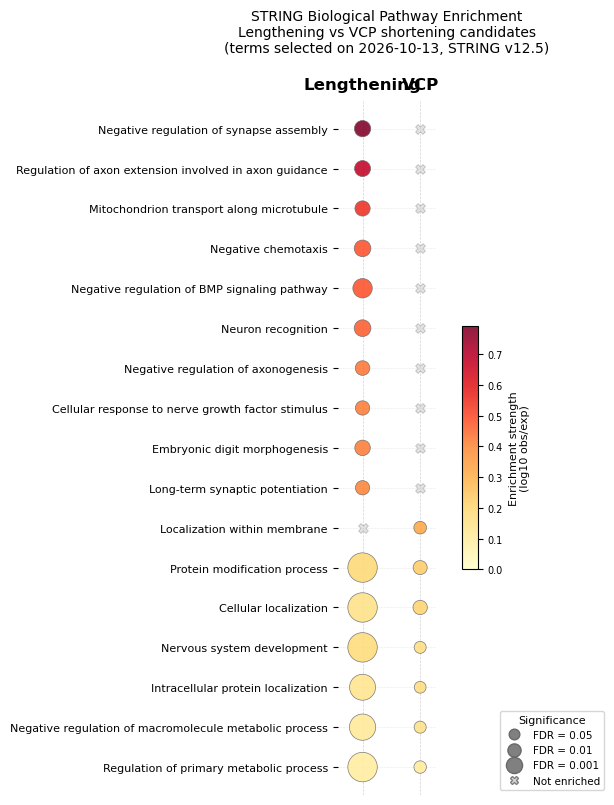

In [15]:
# Bubble plot of the 2026-10-13 terms (selected_terms, query cell above) with their STRING v12.5 strength / FDR.
# plot_go_bubble() is reused by the reference cell below for STRING v12.5's own top-N terms.
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D


# Convert to long format for plotting
def _to_long(merged, cond):
    s = merged[["pathway", f"strength_{cond}", f"fdr_{cond}", f"present_{cond}"]].copy()
    s.columns = ["pathway", "strength", "fdr", "present"]
    s["condition"] = cond
    return s


def plot_go_bubble(lengthening, vcp_shortening, title, path, legend):
    """Bubble plot of the terms in `lengthening` / `vcp_shortening` (outputs of _extract()); returns `merged`."""
    merged = pd.merge(lengthening, vcp_shortening, how="outer", on="pathway")
    for cond in ["Lengthening", "VCP"]:
        merged[f"strength_{cond}"] = merged[f"strength_{cond}"].fillna(0)
        merged[f"fdr_{cond}"] = merged[f"fdr_{cond}"].fillna(1)
        merged[f"present_{cond}"] = merged[f"present_{cond}"].fillna(False)

    df_long = pd.concat([_to_long(merged, "Lengthening"), _to_long(merged, "VCP")], ignore_index=True)
    df_long["neg_log10_fdr"] = -np.log10(df_long["fdr"].clip(lower=1e-10))
    print(f"Unique pathways: {merged['pathway'].nunique()}")

    # ── Ordering: sort pathways by maximum strength (highest at top) ────────────
    pathway_order = (
        merged
        .assign(max_strength=merged[["strength_Lengthening", "strength_VCP"]].max(axis=1))
        .sort_values("max_strength", ascending=True)["pathway"]
        .tolist()
    )
    n_pathways = len(pathway_order)

    df_long["y"] = df_long["pathway"].map({p: i for i, p in enumerate(pathway_order)})
    df_long["x"] = df_long["condition"].map({"Lengthening": 0, "VCP": 3})

    # ── Colour scale (enrichment strength, size-independent) ───────────────────
    vmax = df_long["strength"].max()
    norm = mcolors.Normalize(vmin=0, vmax=vmax)
    cmap = plt.cm.YlOrRd

    # ── Bubble size scale (-log10 FDR) ─────────────────────────────────────────
    present_mask = df_long["present"]
    absent_mask  = ~present_mask

    max_neg_log   = df_long.loc[present_mask, "neg_log10_fdr"].max()
    max_dot_size  = 450                               # max bubble area in pt²
    size_scale    = max_dot_size / max_neg_log if max_neg_log > 0 else 1

    # ── Figure ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(6.5, max(4, n_pathways * 0.48)))

    # Present entries — coloured bubbles
    sc = ax.scatter(
        df_long.loc[present_mask, "x"],
        df_long.loc[present_mask, "y"],
        c=df_long.loc[present_mask, "strength"],
        cmap=cmap, norm=norm,
        s=df_long.loc[present_mask, "neg_log10_fdr"] * size_scale,
        alpha=0.88, linewidths=0.5, edgecolors="dimgray", zorder=3,
    )

    # Absent entries — small light cross to indicate not enriched
    if absent_mask.any():
        ax.scatter(
            df_long.loc[absent_mask, "x"],
            df_long.loc[absent_mask, "y"],
            c="lightgray", s=50, marker="X",
            alpha=0.65, linewidths=0.4, edgecolors="gray", zorder=2,
        )

    # ── Axes formatting ─────────────────────────────────────────────────────────
    ax.set_xticks([0, 3])
    ax.set_xticklabels(["Lengthening", "VCP"], fontsize=12, fontweight="bold")
    ax.xaxis.set_ticks_position("top")
    ax.xaxis.set_label_position("top")
    ax.tick_params(axis="x", pad=6, length=0)

    ax.set_yticks(range(n_pathways))
    ax.set_yticklabels(pathway_order, fontsize=8)

    ax.set_xlim(-1.3, 3.8)
    ax.set_ylim(-0.7, n_pathways - 0.3)

    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
    ax.grid(axis="x", linestyle="--", linewidth=0.5, color="lightgray", zorder=0)
    ax.grid(axis="y", linestyle=":",  linewidth=0.4, color="lightgray", zorder=0)
    ax.set_axisbelow(True)

    # ── Colorbar ────────────────────────────────────────────────────────────────
    cbar = plt.colorbar(sc, ax=ax, shrink=0.35, pad=0.18, aspect=15)
    cbar.set_label("Enrichment strength\n(log10 obs/exp)", fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    # ── Size legend (significance) ───────────────────────────────────────────────
    fdr_ticks   = [0.05, 0.01, 0.001]
    size_handles = [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor="gray", markeredgecolor="dimgray",
               markersize=np.sqrt(-np.log10(f) * size_scale),
               label=f"FDR = {f}")
        for f in fdr_ticks
    ]
    size_handles.append(
        Line2D([0], [0], marker="X", color="w",
               markerfacecolor="lightgray", markeredgecolor="gray",
               markersize=6, label="Not enriched")
    )
    ax.legend(
        handles=size_handles,
        title="Significance", title_fontsize=8,
        fontsize=7.5, frameon=True,
        bbox_to_anchor=(1.6, 0.0), loc="lower left",
    )

    plt.title(title, fontsize=10, pad=18)
    plt.tight_layout()
    save_figure(path, legend=legend)
    plt.show()
    return merged


merged = plot_go_bubble(
    lengthening, vcp_shortening,
    title="STRING Biological Pathway Enrichment\nLengthening vs VCP shortening candidates\n(terms selected on 2026-10-13, STRING v12.5)",
    path=os.path.join(f"{figures_subfolder}", "MN_pathway_enrichment", "bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35.pdf"),
    legend=f"STRING v12.5 GO Biological Process enrichment of the genes lengthened D22 -> D35 in CTRL nuclei "
           "('Lengthening') and of the genes shortened in VCP vs CTRL nuclei at D35 ('VCP'), the two lists of "
           f"the maturation vs VCP Venn diagram. Rows = the terms selected on 2026-10-13 as the top {top_n} non-redundant terms of each list (ranked by strength, a term skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed) in STRING's live results of that date; values from STRING v12.5. Colour = strength (log10 observed/expected), "
           "bubble size = -log10(FDR); grey cross = not enriched in that list.",
)

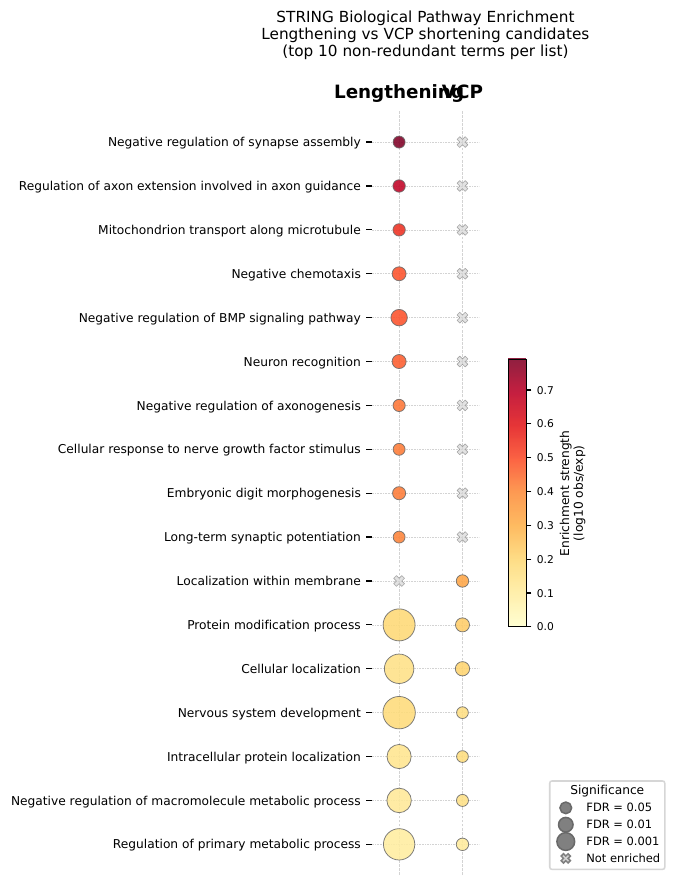

In [16]:
# Reference: the 2026-10-13 version of this figure, made from STRING's live site, whose results for these genes have
# changed since (286 Lengthening / 10 VCP GO terms then, 475 / 15 with v12.5 above). It cannot be regenerated, so
# it is shown from its PDF. The plot above uses its terms with their v12.5 values.
import subprocess
import tempfile
from IPython.display import Image, display

# kept in the git-tracked ../cache/reference_figures/ (Figures/ is not versioned)
reference_figure = "../cache/reference_figures/bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35_STRING_live_2026-10-13.pdf"
with tempfile.TemporaryDirectory() as tmp:
    subprocess.run(["pdftoppm", "-png", "-singlefile", "-r", "110", reference_figure, f"{tmp}/reference_figure"], check=True)
    display(Image(filename=f"{tmp}/reference_figure.png"))

Unique pathways: 18


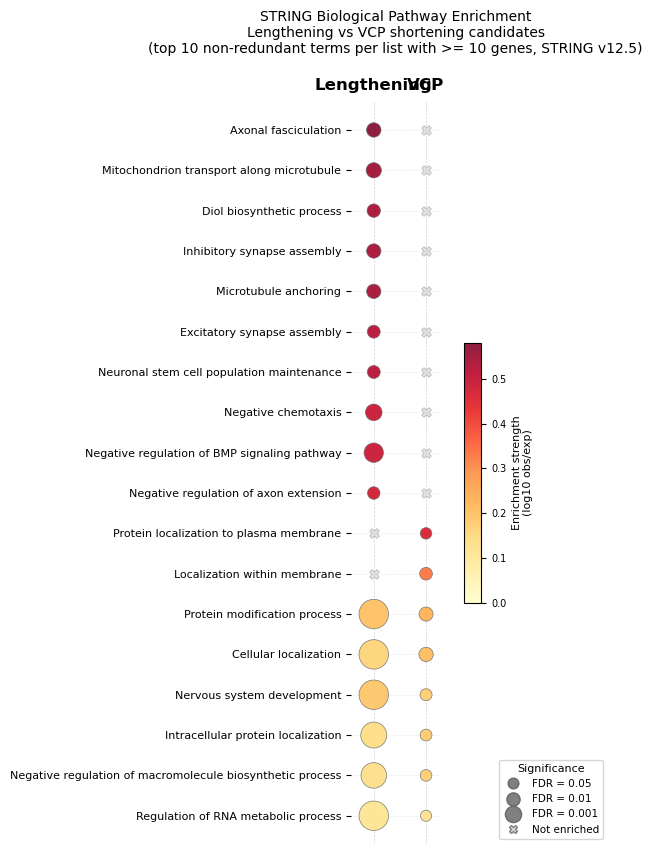

In [17]:
# Reference: STRING v12.5's own top {top_n} non-redundant terms per list, with the same rule that picked the terms
# of the 2026-10-13 figure, but keeping only terms with at least `min_genes` genes of the list (observed gene count),
# so that very small terms (3-5 genes) do not take the top ranks by strength.
min_genes = 10
top_terms_v12_5 = (
    set(select_top_nonredundant(df_lengthening[df_lengthening["observed gene count"] >= min_genes], _raw_lengthening,
                                top_n=top_n, bg_threshold=bg_threshold)["term description"])
    | set(select_top_nonredundant(df_vcp_shortening[df_vcp_shortening["observed gene count"] >= min_genes], _raw_vcp_shortening,
                                  top_n=top_n, bg_threshold=bg_threshold)["term description"])
)
plot_go_bubble(
    _extract(df_lengthening[df_lengthening["term description"].isin(top_terms_v12_5)], "Lengthening", bg_threshold),
    _extract(df_vcp_shortening[df_vcp_shortening["term description"].isin(top_terms_v12_5)], "VCP", bg_threshold),
    title=f"STRING Biological Pathway Enrichment\nLengthening vs VCP shortening candidates\n"
          f"(top {top_n} non-redundant terms per list with >= {min_genes} genes, STRING v12.5)",
    path=os.path.join(f"{figures_subfolder}", "MN_pathway_enrichment",
                      f"bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35_STRING_v12.5_top{top_n}_min{min_genes}genes.pdf"),
    legend=f"Reference for bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35.pdf: same STRING v12.5 enrichment, but "
           f"rows = STRING v12.5's own top {top_n} non-redundant terms of each list among the terms with >= {min_genes} genes "
           "of the list (ranked by strength, a term skipped when its gene set overlaps a kept term with Jaccard >= 0.5; "
           "terms with >= 10,000 background genes removed). Colour = strength (log10 observed/expected), "
           "bubble size = -log10(FDR); grey cross = not enriched in that list.",
);

In [18]:
# All significant GO Process terms (FDR < 0.05) of both lists, from the STRING v12.5 query above — not only the
# plotted terms, and without the background-size or redundancy filters — with their member genes.
# "list" = the gene list the term is enriched in ("Lengthening" or "VCP"); "in_plot" flags the terms drawn as a
# bubble for that list in the bubble plot above.
def _significant_terms(df_pathways, raw_df, cond):
    term_genes = raw_df.set_index("term")["preferredNames"].apply(lambda g: ", ".join(sorted(g)))
    out = df_pathways[df_pathways["false discovery rate"] < 0.05].copy()
    out.insert(0, "list", cond)
    out["genes"] = out["term ID"].map(term_genes)
    out["in_plot"] = out["term description"].isin(set(merged.loc[merged[f"present_{cond}"], "pathway"]))
    return out.sort_values("false discovery rate").reset_index(drop=True)

significant_terms = {
    "Lengthening": _significant_terms(df_lengthening, _raw_lengthening, "Lengthening"),
    "VCP": _significant_terms(df_vcp_shortening, _raw_vcp_shortening, "VCP"),
}
save_table({"All": pd.concat(significant_terms.values(), ignore_index=True), **significant_terms},
           f"{tables_subfolder}/bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35_significant_terms.xlsx",
           index=False,
           legend="Every significant term (FDR < 0.05) of the STRING v12.5 GO Biological Process enrichment behind "
                  "bubble_GO_BP_lengthening_D22_to_D35_vs_VCP_shortening_D35.pdf, without the background-size or "
                  "redundancy filters of the plot: genes lengthened D22 -> D35 in CTRL nuclei ('Lengthening') and genes "
                  "shortened in VCP vs CTRL nuclei at D35 ('VCP'). Sheets: All, Lengthening, VCP. Columns: list, the "
                  "STRING enrichment columns (term ID, description, observed / background gene counts, strength, "
                  "signal, FDR, ...), genes = member genes of the list, in_plot = drawn as a bubble for that list.")

for cond, sig_df in significant_terms.items():
    missing = [t for t in paper_plot_terms[cond] if t not in set(sig_df["term description"])]
    print(f"{cond}: {len(sig_df)} significant terms, {int(sig_df['in_plot'].sum())} in the plot; "
          f"2026-10-13 terms not significant in v12.5: {missing}")

Lengthening: 475 significant terms, 16 in the plot; 2026-10-13 terms not significant in v12.5: []
VCP: 15 significant terms, 7 in the plot; 2026-10-13 terms not significant in v12.5: []


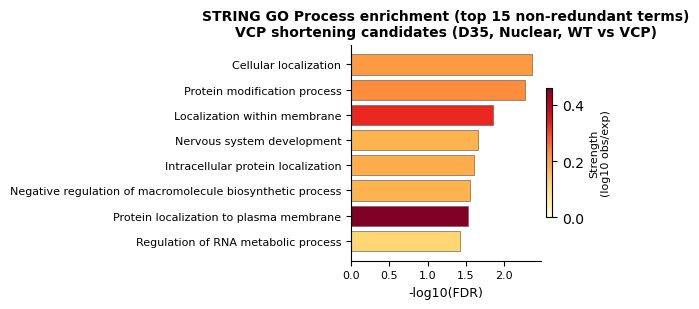

In [19]:

# ── STRING GO Process enrichment — VCP shortening candidates only ───────────
# The bubble plot above compares Lengthening vs VCP side by side; this barplot
# isolates just the VCP shortening list (reusing df_vcp_shortening /
# _raw_vcp_shortening and the same select_top_nonredundant curation from the
# GO cell above) so its own top pathways are easier to read at a glance.
top_n_vcp_bar = 15
df_plot_vcp_only = select_top_nonredundant(df_vcp_shortening, _raw_vcp_shortening, top_n=top_n_vcp_bar, bg_threshold=bg_threshold)
df_plot_vcp_only = df_plot_vcp_only.sort_values("false discovery rate", ascending=False)

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_vcp_only))))
norm = mcolors.Normalize(vmin=0, vmax=df_plot_vcp_only["strength"].max())
cmap = plt.cm.YlOrRd
ax.barh(
    df_plot_vcp_only["term description"],
    -np.log10(df_plot_vcp_only["false discovery rate"]),
    color=cmap(norm(df_plot_vcp_only["strength"])),
    edgecolor="dimgray", linewidth=0.5,
)
ax.set_xlabel("-log10(FDR)", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(f"STRING GO Process enrichment (top {top_n_vcp_bar} non-redundant terms)\nVCP shortening candidates (D35, Nuclear, WT vs VCP)", fontsize=10, weight="bold")
sns.despine(ax=ax)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Strength\n(log10 obs/exp)", fontsize=8)
plt.tight_layout()

out_dir_vcp_only = os.path.join(figures_subfolder, "MN_pathway_enrichment")
os.makedirs(out_dir_vcp_only, exist_ok=True)
save_figure(os.path.join(out_dir_vcp_only, "barplot_GO_BP_VCP_shortening_D35.pdf"),
            legend=f"STRING GO Biological Process enrichment of the genes with a 3'UTR shortened in VCP vs "
                   f"CTRL nuclei at D35: top {top_n_vcp_bar} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed). Bar = -log10(FDR), colour = strength "
                   "(log10 observed/expected).")
plt.show()


<a id="astrocytes"></a>
## 3'UTR shortening vs lengthening in VCP vs CTRL astrocytes

The first cells load the astrocyte table of pairs and detect the CTRL → VCP comparisons. Next come volcano plots per fraction, and the last cell is the barplot of significant shortening and lengthening events.

Saved in `astrocytes_3UTR_shifts_VCP_vs_CTRL/`: `volcano_dPUD_VCP_vs_CTRL.pdf` and `barplot_shortening_vs_lengthening_VCP_vs_CTRL.pdf`.

In [20]:
df_astro = pd.read_csv(f"{PROJECT_DIR}/Astrocytes/results/3UTR_analysis/table_of_pairs.csv", index_col=0)

In [21]:
df_astro

,index_prox,proximal_id,strand_prox,SRR12899407_prox,SRR12899408_prox,SRR12899409_prox,SRR12899410_prox,SRR12899403_prox,SRR12899404_prox,SRR12899405_prox,...,DUD_significance_CTRL_CYTO_VCP_NUC,PUD_significance_VCP_CYTO_CTRL_NUC,RUD_significance_VCP_CYTO_CTRL_NUC,DUD_significance_VCP_CYTO_CTRL_NUC,PUD_significance_VCP_CYTO_VCP_NUC,RUD_significance_VCP_CYTO_VCP_NUC,DUD_significance_VCP_CYTO_VCP_NUC,PUD_significance_CTRL_NUC_VCP_NUC,RUD_significance_CTRL_NUC_VCP_NUC,DUD_significance_CTRL_NUC_VCP_NUC
0,16578,AAGAB.2.ENST00000542650.MUT3.D7.Nuclear.VCP-R191Q,-,960.7500,1255.6875,1081.625,833.2500,524.2500,669.6250,451.6875,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
1,3170,AAK1.2.ENST00000409068.CTRL4.D14.Cytoplasmic.W...,-,135.3750,0.0000,179.000,149.7500,242.6250,464.4375,225.7500,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
2,7933,AARS2.1.ENST00000244571.CTRL1.D14.Cytoplasmic....,-,659.5000,572.9375,532.125,472.0000,1009.4375,1479.8125,1599.8125,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
3,12033,AASDHPPT.1.ENST00000278618.MUT4.D0.Nuclear.VCP...,+,1211.0625,600.0000,1134.000,908.3125,721.6875,519.0625,364.7500,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
4,11466,ABCA1.1.ENST00000374736.MUT4.D3.Nuclear.VCP-R191Q,-,1379.0000,618.8750,764.250,1050.6250,3465.2500,2618.6250,4742.7500,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6707,13362,ZWINT.ENST00000361148.Ensembl,-,392.8750,1401.6250,1256.250,311.7500,399.7500,1300.0000,1423.4375,...,Non-Significant,Non-Significant,Significant distal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
6708,9425,ZXDB.3.ENST00000374888.CTRL1.D22.Cytoplasmic.W...,+,96.3750,165.3750,145.375,195.5000,59.6875,94.0000,90.2500,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Significant proximal shift,Significant proximal shift,Significant proximal shift
6709,319,ZYG11B.1.ENST00000294353.MUT1.D0.Nuclear.VCP-R...,+,192.3750,315.1250,290.375,339.3750,208.3750,229.3750,285.2500,...,Significant proximal shift,Non-Significant,Non-Significant,Non-Significant,Significant proximal shift,Non-Significant,Significant proximal shift,Significant proximal shift,Significant proximal shift,Significant proximal shift
6710,17905,ZZEF1.1.ENST00000381638.MUT2.D0.Cytoplasmic.VC...,-,26.3125,0.0000,46.250,130.7500,40.0000,322.0000,0.0000,...,Non-Significant,Non-Significant,Significant distal shift,Non-Significant,Significant distal shift,Significant distal shift,Significant distal shift,Non-Significant,Significant distal shift,Non-Significant


In [22]:

# Auto-detect VCP vs CTRL comparison pairs from column names
import re

vcp_pval_cols = [c for c in df_astro.columns if c.startswith("adjusted_fisher_pvalue_") and "VCP" in c]

detected_pairs = []
for col in vcp_pval_cols:
    suffix = col.replace("adjusted_fisher_pvalue_", "")
    parts = suffix.split("_")
    for i in range(1, len(parts)):
        t2_candidate = "_".join(parts[i:])
        t1_candidate = "_".join(parts[:i])
        if (f"PUD_{t1_candidate}" in df_astro.columns
                and f"PUD_{t2_candidate}" in df_astro.columns):
            detected_pairs.append((t1_candidate, t2_candidate))
            break

# Keep only CTRL→VCP pairs where the fraction token matches between t1 and t2
def _fraction_token(name):
    """Return 'NUC', 'CYTO', or '' based on the condition name."""
    u = name.upper()
    if "NUC" in u:
        return "NUC"
    if "CYTO" in u:
        return "CYTO"
    return ""

valid_pairs = [
    (t1, t2) for t1, t2 in detected_pairs
    if t1.upper().startswith("CTRL")
    and t2.upper().startswith("VCP")
    and _fraction_token(t1) == _fraction_token(t2)
    and _fraction_token(t1) != ""
]

print("Valid CTRL→VCP pairs (same fraction):")
for t1, t2 in valid_pairs:
    print(f"  {t1}  →  {t2}  [{_fraction_token(t1)}]")


Valid CTRL→VCP pairs (same fraction):
  CTRL_CYTO  →  VCP_CYTO  [CYTO]
  CTRL_NUC  →  VCP_NUC  [NUC]


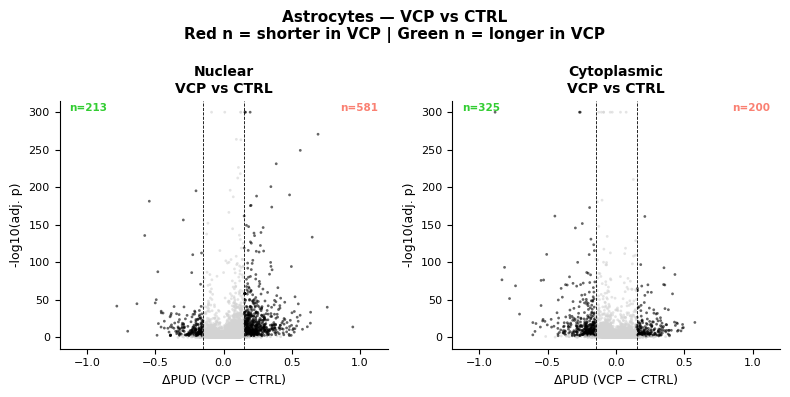

In [23]:

# Volcano plots: VCP vs CTRL — Astrocytes (Nuclear and Cytoplasmic)
nuc_pairs  = [(t1, t2) for t1, t2 in valid_pairs if _fraction_token(t2) == "NUC"]
cyto_pairs = [(t1, t2) for t1, t2 in valid_pairs if _fraction_token(t2) == "CYTO"]

volcano_pairs_astro = []
for t1, t2 in nuc_pairs:
    volcano_pairs_astro.append((t1, t2, "Nuclear\nVCP vs CTRL"))
for t1, t2 in cyto_pairs:
    volcano_pairs_astro.append((t1, t2, "Cytoplasmic\nVCP vs CTRL"))

n_panels = len(volcano_pairs_astro)
if n_panels == 0:
    print("No valid pairs found — check column names above.")
else:
    fig, axes = plt.subplots(1, n_panels, figsize=(4 * n_panels, 4))
    axes = np.atleast_1d(axes)

    astro_sig_counts = []

    for ax, (t1, t2, title) in zip(axes, volcano_pairs_astro):
        suffix       = f"{t1}_{t2}"
        adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
        pud_t1_col   = f"PUD_{t1}"
        pud_t2_col   = f"PUD_{t2}"

        rud_t1_col = f"RUD_{t1}"
        rud_t2_col = f"RUD_{t2}"
        cols = [adj_pval_col, pud_t1_col, pud_t2_col]
        
        if rud_t1_col in df_astro.columns and rud_t2_col in df_astro.columns:
            cols += [rud_t1_col, rud_t2_col]
        plot_df = df_astro[cols].dropna().copy()
        plot_df["delta_PUD"]      = plot_df[pud_t2_col] - plot_df[pud_t1_col]
        plot_df["neg_log10_pval"] = -np.log10(plot_df[adj_pval_col].clip(lower=1e-300))
        if rud_t1_col in df_astro.columns and rud_t2_col in df_astro.columns:
            plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
            rud_mask = plot_df["delta_RUD"].abs() > 1
        else:
            rud_mask = pd.Series(True, index=plot_df.index)

        sig_short = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15)
        sig_long  = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15)
        sig_any   = sig_short | sig_long
        colors    = sig_any.map({True: "black", False: "lightgray"})

        ax.scatter(plot_df["delta_PUD"], plot_df["neg_log10_pval"],
                   c=colors, s=4, alpha=0.6, linewidths=0)
        ax.axvline( 0.15, color="black", linestyle="--", linewidth=0.6)
        ax.axvline(-0.15, color="black", linestyle="--", linewidth=0.6)
        ax.set_xlabel("ΔPUD (VCP − CTRL)", fontsize=9)
        ax.set_ylabel("-log10(adj. p)", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.set_title(title, fontsize=10, weight="bold")
        ax.set_xlim(-1.2, 1.2)

        n_short = (sig_short & rud_mask).sum()
        n_long  = (sig_long  & rud_mask).sum()
        ax.text(0.97, 0.99, f"n={n_short}", color="salmon", fontsize=7.5, weight="bold",
                ha="right", va="top", transform=ax.transAxes)
        ax.text(0.03, 0.99, f"n={n_long}", color="limegreen", fontsize=7.5, weight="bold",
                ha="left", va="top", transform=ax.transAxes)
        sns.despine(ax=ax)

        fraction = "Nuclear" if _fraction_token(t2) == "NUC" else "Cytoplasmic"
        astro_sig_counts.append({"fraction": fraction, "shortening": int(n_short), "lengthening": int(n_long)})

    plt.suptitle("Astrocytes — VCP vs CTRL\nRed n = shorter in VCP | Green n = longer in VCP",
                 fontsize=11, weight="bold")
    plt.tight_layout()


    save_figure(f"{figures_subfolder}/astrocytes_3UTR_shifts_VCP_vs_CTRL/volcano_dPUD_VCP_vs_CTRL.pdf",
                legend="VCP vs CTRL astrocytes, nuclear and cytoplasmic fractions: "
                       "volcano plots of dPUD (VCP - CTRL) vs -log10(adjusted Fisher p); black = adj. p < 0.01 and "
                       "|dPUD| >= 0.15 (dashed lines; the RUD criterion is not used for the colours); n = significant "
                       "pairs, with |dRUD| > 1, shorter (right, red) or longer (left, green) in VCP.")
    plt.show()


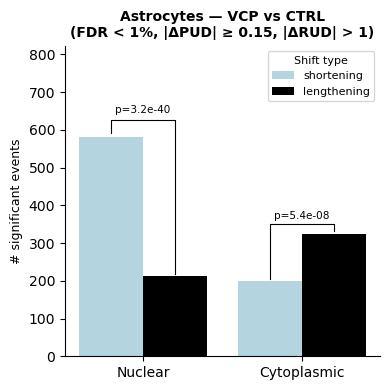

In [24]:
# Barplot: number of significant shortening vs lengthening events — Astrocytes
counts_astro = pd.DataFrame(astro_sig_counts)
counts_astro_long = counts_astro.melt(
    id_vars="fraction",
    value_vars=["shortening", "lengthening"],
    var_name="shift_type",
    value_name="n_events",
)

palette_shift = {"shortening": "lightblue", "lengthening": "black"}
fraction_order_astro = [f for f in ["Nuclear", "Cytoplasmic"] if f in counts_astro["fraction"].values]

fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(
    data=counts_astro_long,
    x="fraction",
    y="n_events",
    hue="shift_type",
    palette=palette_shift,
    order=fraction_order_astro,
    hue_order=["shortening", "lengthening"],
    ax=ax,
)

# Binomial test annotation per fraction
patches = sorted(ax.patches, key=lambda p: p.get_x())
for frac_idx, fraction in enumerate(fraction_order_astro):
    row = counts_astro[counts_astro["fraction"] == fraction]
    if row.empty:
        continue
    n_s = int(row["shortening"].values[0])
    n_l = int(row["lengthening"].values[0])
    total = n_s + n_l
    if total == 0:
        continue
    binom_result = stats.binomtest(n_s, total, p=0.5, alternative="two-sided")
    pval_label = f"p={binom_result.pvalue:.1e}"

    p_short = patches[frac_idx * 2]
    p_long  = patches[frac_idx * 2 + 1]
    x_s = p_short.get_x() + p_short.get_width() / 2
    x_l = p_long.get_x()  + p_long.get_width()  / 2
    h_s = p_short.get_height()
    h_l = p_long.get_height()
    y_top  = max(h_s, h_l) * 1.08
    ax.plot([x_s, x_s, x_l, x_l], [h_s * 1.02, y_top, y_top, h_l * 1.02],
            color="black", lw=0.8)
    ax.text((x_s + x_l) / 2, y_top * 1.02, pval_label,
            ha="center", va="bottom", fontsize=7.5)

ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
ax.set_xlabel("")
ax.set_ylabel("# significant events", fontsize=9)
ax.set_title("Astrocytes — VCP vs CTRL\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)", fontsize=10, weight="bold")
ax.legend(title="Shift type", fontsize=8, title_fontsize=8)
sns.despine(ax=ax)
plt.tight_layout()



save_figure(f"{figures_subfolder}/astrocytes_3UTR_shifts_VCP_vs_CTRL/barplot_shortening_vs_lengthening_VCP_vs_CTRL.pdf",
            legend="Number of significant 3'UTR shortening (light blue) and "
                   "lengthening (black) events in VCP vs CTRL astrocytes, nuclear and cytoplasmic fractions (adj. Fisher p < 0.01, |dPUD| >= 0.15, |dRUD| > 1). "
                   "p = two-sided binomial test, shortening vs lengthening.")
plt.show()


<a id="ml240-reversal"></a>
## Reversal of VCP-KI shortening by ML240

Overlap between genes shortened WT → VCP-KI and genes lengthened VCP-KI → ML240 (nuclear fraction), shown as a Venn diagram and a pie chart, followed by STRING enrichment of the reversed genes.

Saved in `VCP-KI_ML240_reversal/`: `venn_VCP-KI_shortened_vs_ML240_lengthened_nuclear.pdf`, `piechart_VCP-KI_shortened_reversed_by_ML240_nuclear.pdf` and `barplot_GO_CC_VCP-KI_shortened_reversed_by_ML240_nuclear.pdf`.

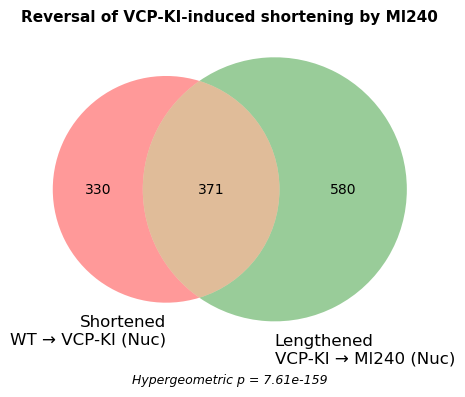

Shortened WT→VCP-KI (Nuc):        701
Lengthened VCP-KI→Ml240 (Nuc):     951
Common (reversed by Ml240):        371  (52.9% of shortened genes)
Hypergeometric p:                  7.61e-159
Fold enrichment:                   3.89x


In [25]:

# ── Overlap: genes shortened WT→VCP-KI (Nuc) vs genes lengthened VCP-KI→Ml240 (Nuc) ──
# i.e. how much of the VCP-KI-induced shortening does Ml240 treatment reverse?
from matplotlib_venn import venn2
from scipy.stats import hypergeom

shifts_dir_ki = f"{PROJECT_DIR}/VCP-KI-Ml240/results/3UTR_analysis/shifts"
with open(f"{shifts_dir_ki}/genes_proximals_Untreated_WT_Nuc_vs_Untreated_VCP_KI_Nuc.csv") as f:
    genes_ki_shortened_nuc = [line.strip() for line in f if line.strip()]
with open(f"{shifts_dir_ki}/genes_distals_Untreated_VCP_KI_Nuc_vs_Ml240_VCP_KI_Nuc.csv") as f:
    genes_ki_lengthened_ml240_nuc = [line.strip() for line in f if line.strip()]

set_ki_shortened = set(genes_ki_shortened_nuc)
set_ki_lengthened_ml240 = set(genes_ki_lengthened_ml240_nuc)

N = len(df_ki)
K = len(set_ki_shortened)
n = len(set_ki_lengthened_ml240)
k = len(set_ki_shortened & set_ki_lengthened_ml240)

p_value = hypergeom.sf(k - 1, N, K, n)
expected = n * K / N
enrichment = k / expected

fig, ax = plt.subplots(figsize=(5, 4))
v = venn2(
    [set_ki_shortened, set_ki_lengthened_ml240],
    set_labels=("Shortened\nWT → VCP-KI (Nuc)", "Lengthened\nVCP-KI → Ml240 (Nuc)"),
    ax=ax,
)
plt.title("Reversal of VCP-KI-induced shortening by Ml240", fontsize=11, weight="bold")
ax.text(0.5, -0.08,
        f"Hypergeometric p = {p_value:.2e}",
        ha="center", va="top", transform=ax.transAxes, fontsize=9, style="italic")
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_reversal")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "venn_VCP-KI_shortened_vs_ML240_lengthened_nuclear.pdf"),
            legend="Overlap between the genes with a 3'UTR shortened in untreated VCP-KI vs WT "
                   "cells and the genes with a 3'UTR lengthened after ML240 treatment of VCP-KI cells (nuclear fraction; "
                   "gene lists from VCP-KI-Ml240/results/3UTR_analysis/shifts). One-sided hypergeometric test; "
                   "background = number of pairs in the VCP-KI table.")
plt.show()

print(f"Shortened WT→VCP-KI (Nuc):        {len(set_ki_shortened)}")
print(f"Lengthened VCP-KI→Ml240 (Nuc):     {len(set_ki_lengthened_ml240)}")
print(f"Common (reversed by Ml240):        {k}  ({k / K:.1%} of shortened genes)")
print(f"Hypergeometric p:                  {p_value:.2e}")
print(f"Fold enrichment:                   {enrichment:.2f}x")


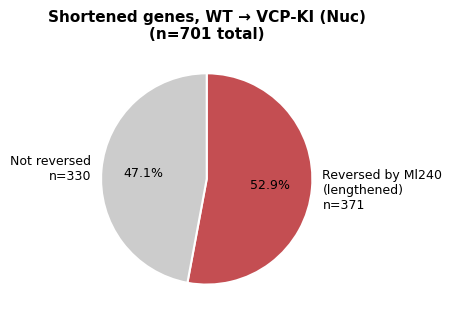

In [26]:
# ── Pie chart: of the genes shortened WT→VCP-KI (Nuc), how many are reversed
# (lengthened) by Ml240 vs not? ───────────────────────────────────────────────
n_reversed = k
n_not_reversed = K - k

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(
    [n_reversed, n_not_reversed],
    labels=[f"Reversed by Ml240\n(lengthened)\nn={n_reversed}", f"Not reversed\nn={n_not_reversed}"],
    colors=["#C44E52", "#CCCCCC"],
    autopct=lambda pct: f"{pct:.1f}%",
    startangle=90,
    counterclock=False,
    wedgeprops=dict(edgecolor="white", linewidth=1.5),
    textprops=dict(fontsize=9),
)
ax.set_title(f"Shortened genes, WT → VCP-KI (Nuc)\n(n={K} total)", fontsize=11, weight="bold")
plt.tight_layout()

save_figure(os.path.join(out_dir, "piechart_VCP-KI_shortened_reversed_by_ML240_nuclear.pdf"),
            legend="Of the genes with a 3'UTR shortened in untreated VCP-KI vs WT cells "
                   "(nuclear), the share lengthened back by ML240 (red) vs not (grey).")
plt.show()


In [27]:
out_dir

'../Figures/Figure_3UTR_CTRL_vs_VCP/VCP-KI_ML240_reversal'

Querying STRING for Ml240-reversed genes (371 genes)...
Terms returned per STRING category:
GWAS         52
Component    19
TISSUES       8
Process       3
HPO           3
Hallmark      2
Function      1
Keyword       1

3 GO Process terms
15 GO Component terms


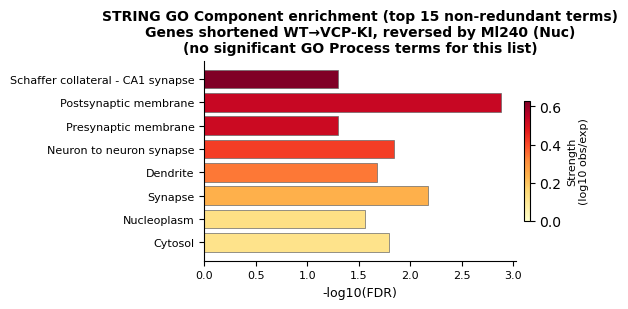

In [28]:
# ── STRING enrichment on the 371 genes reversed by Ml240 (shortened WT→VCP-KI,
# then lengthened back VCP-KI→Ml240; Nuc) ────────────────────────────────────
overlap_genes_ki_reversed = sorted(set_ki_shortened & set_ki_lengthened_ml240)
print(f"Querying STRING for Ml240-reversed genes ({len(overlap_genes_ki_reversed)} genes)...")
raw_ki_reversed = add_strength_and_signal(get_string_enrichment(overlap_genes_ki_reversed))
print("Terms returned per STRING category:")
print(raw_ki_reversed["category"].value_counts().to_string())

# GO Process (Biological Process) comes back empty for this list — real result,
# not a bug (verified directly against the STRING API). The signal instead shows
# up in GO Component / Keyword / TISSUES, all pointing the same direction
# (synapse / neuron), so we plot Component here instead of Process.
df_ki_reversed_go = to_pathways_format(raw_ki_reversed[raw_ki_reversed["category"] == "Process"])
df_ki_reversed_go = df_ki_reversed_go[df_ki_reversed_go["background gene count"] < 10000]
print(f"\n{len(df_ki_reversed_go)} GO Process terms")

df_ki_reversed_component = to_pathways_format(raw_ki_reversed[raw_ki_reversed["category"] == "Component"])
df_ki_reversed_component = df_ki_reversed_component[df_ki_reversed_component["background gene count"] < 10000]
print(f"{len(df_ki_reversed_component)} GO Component terms")

# Curate with the same non-redundant top-N selection used throughout this notebook.
top_n_ki_reversed = 15
df_plot_ki_reversed = select_top_nonredundant(df_ki_reversed_component, raw_ki_reversed, top_n=top_n_ki_reversed, bg_threshold=10000)
df_plot_ki_reversed = df_plot_ki_reversed.sort_values("strength")

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_ki_reversed))))
norm = mcolors.Normalize(vmin=0, vmax=df_plot_ki_reversed["strength"].max())
cmap = plt.cm.YlOrRd
ax.barh(
    df_plot_ki_reversed["term description"],
    -np.log10(df_plot_ki_reversed["false discovery rate"]),
    color=cmap(norm(df_plot_ki_reversed["strength"])),
    edgecolor="dimgray", linewidth=0.5,
)
ax.set_xlabel("-log10(FDR)", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(f"STRING GO Component enrichment (top {top_n_ki_reversed} non-redundant terms)\nGenes shortened WT\u2192VCP-KI, reversed by Ml240 (Nuc)\n(no significant GO Process terms for this list)", fontsize=10, weight="bold")
sns.despine(ax=ax)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Strength\n(log10 obs/exp)", fontsize=8)
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_reversal")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "barplot_GO_CC_VCP-KI_shortened_reversed_by_ML240_nuclear.pdf"),
            legend=f"STRING GO Cellular Component enrichment of the genes shortened in VCP-KI "
                   f"vs WT and lengthened back by ML240 (nuclear): top {top_n_ki_reversed} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed). Bar = "
                   "-log10(FDR), colour = strength (log10 observed/expected). GO Biological Process gives no "
                   "significant term for this list.")
plt.show()


<a id="vcp-ki-gene-expression"></a>
## Gene expression and 3'UTR usage (PUD) in VCP knock-in cells ± ML240

Untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells, nuclear and cytoplasmic fractions, analysed twice with `omicstools`:
1. **Gene expression**: filtered, normalised gene counts.
2. **PUD**: per-sample PUD of each proximal/distal pair (`VCP-KI-Ml240/results/3UTR_analysis/table_of_pairs_simplified.csv`).

For each, the first cell builds the `OmicsDataset` and runs the SVD: on log2(x+1) expression for genes and on raw PUD values for PUD, the first component is removed and the SVD is recomputed (`perform_svd_analysis`). Next comes the hierarchical clustering of treatments (samples of each treatment averaged, Spearman correlation, average linkage). The last cell shows the scores of the first 10 components per treatment, with the % of variance each component explains on the y-axis label.

Saved in `VCP-KI_ML240_SVD/`: `dendrogram_treatments_gene_expression.pdf`, `boxplot_SVD_components_per_treatment_gene_expression.pdf`, `dendrogram_treatments_PUD.pdf` and `boxplot_SVD_components_per_treatment_PUD.pdf`. The variance-explained scatter plots drawn by `perform_svd_analysis` are closed, not saved.

Note: `Ml240_VCP_KI_Nuc` has a single sample.

In [29]:
# ── VCP-KI ± ML240: gene expression SVD (setup for the clustering and component plots) ──
from omicstools.OmicsDataset import OmicsDataset

df_ki_genes = pd.read_csv(f"{PROJECT_DIR}/VCP-KI-Ml240/results/genes_preprocessing/df_genes_filtered_normalized.csv", index_col=0)

ki_treatments = {
    "Ml240_VCP_KI_Cyto":     ["SRR21683987", "SRR21683988"],
    "Untreated_VCP_KI_Cyto": ["SRR21684010", "SRR21684011"],
    "Ml240_VCP_KI_Nuc":      ["SRR21683999"],
    "Untreated_VCP_KI_Nuc":  ["SRR21684022", "SRR21684023"],
    "Untreated_WT_Cyto":     ["SRR21684016", "SRR21684017", "SRR21684018", "SRR21684019"],
    "Untreated_WT_Nuc":      ["SRR21684028", "SRR21684029", "SRR21684030", "SRR21684031"],
}
ki_palette_dict = {
    "Untreated_WT_Cyto":     "#EBEBEB",
    "Untreated_WT_Nuc":      "#A5A5A5",
    "Untreated_VCP_KI_Cyto": "#FFC183",
    "Untreated_VCP_KI_Nuc":  "#FF8C00",
    "Ml240_VCP_KI_Cyto":     "#ff6464",
    "Ml240_VCP_KI_Nuc":      "#ff0000",
}
ki_palette = [ki_palette_dict[t] for t in ki_treatments]

df_ki_genes = df_ki_genes[[s for samples in ki_treatments.values() for s in samples]]
ki_genes_dataset = OmicsDataset(df=df_ki_genes, treatments=ki_treatments,
                                treatment_name="treatment", feature_type="gene", nb_comp=17)
ki_genes_dataset.perform_svd_analysis(top_n=10)
plt.close("all")  # variance-explained scatter plots, not part of the figure

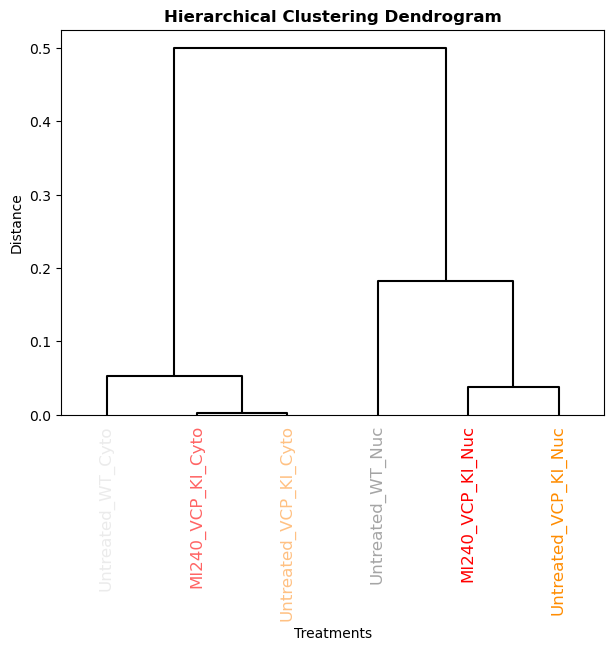

In [30]:
## Hierarchical clustering of treatments (gene expression)
# Leaves are treatments: samples of each treatment are averaged before clustering
ki_genes_dataset.hierarchical_clustering(palette=ki_palette, treatments=ki_treatments, color_threshold=0, level="treatment")

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_SVD")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "dendrogram_treatments_gene_expression.pdf"),
            legend="VCP knock-in +- ML240, gene expression: hierarchical clustering of the treatments "
                   "(samples of each treatment averaged; Spearman correlation, average linkage; omicstools). Untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells, nuclear and cytoplasmic fractions (ML240 VCP-KI nuclear: a single sample).")
plt.show()

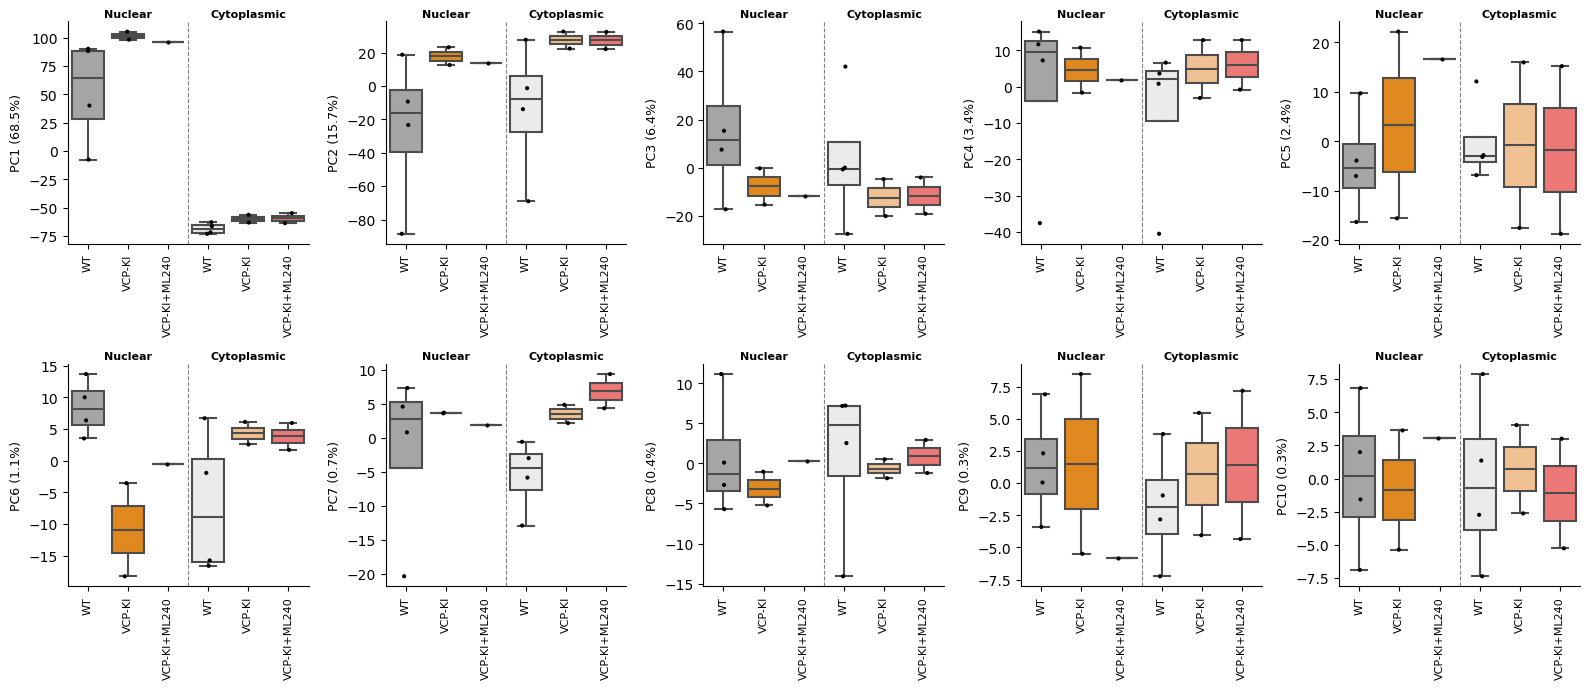

In [31]:
## PC scores per treatment (gene expression)
# Nuclear on the left, Cytoplasmic on the right; WT, VCP-KI, VCP-KI+ML240 within each
ki_conditions = [("Untreated_WT", "WT"), ("Untreated_VCP_KI", "VCP-KI"), ("Ml240_VCP_KI", "VCP-KI+ML240")]
ki_compartments = [("Nuc", "Nuclear"), ("Cyto", "Cytoplasmic")]
ki_order = [f"{cond}_{comp}" for comp, _ in ki_compartments for cond, _ in ki_conditions]
ki_xtick_labels = [label for _ in ki_compartments for _, label in ki_conditions]

def plot_ki_pc_boxplots(dataset, n_pcs=10):
    # % of variance explained by each component (after removing the first component)
    var_pct = 100 * dataset.s_w1**2 / (dataset.s_w1**2).sum()
    fig, axes = plt.subplots(2, 5, figsize=(16, 7))
    for i, ax in enumerate(axes.flat[:n_pcs]):
        pc = f"PC{i+1}"
        sns.boxplot(data=dataset.pca, x="treatment", y=pc, order=ki_order, palette=ki_palette_dict, showfliers=False, ax=ax)
        sns.stripplot(data=dataset.pca, x="treatment", y=pc, order=ki_order, color="black", size=3, ax=ax)
        ax.axvline(len(ki_conditions) - 0.5, color="gray", linestyle="--", linewidth=0.8)
        for j, (_, name) in enumerate(ki_compartments):
            ax.text(j * len(ki_conditions) + (len(ki_conditions) - 1) / 2, 1.01, name, transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=8, weight="bold")
        ax.set_xticks(range(len(ki_order)))
        ax.set_xticklabels(ki_xtick_labels, rotation=90, fontsize=8)
        ax.set_xlabel("")
        ax.set_ylabel(f"{pc} ({var_pct[i]:.1f}%)", fontsize=9)
        sns.despine(ax=ax)
    plt.tight_layout()

plot_ki_pc_boxplots(ki_genes_dataset)

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_SVD")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "boxplot_SVD_components_per_treatment_gene_expression.pdf"),
            legend="VCP knock-in +- ML240, gene expression (SVD of log2(normalised counts + 1)): scores of the first 10 components after "
                   "removing the first one and recomputing the SVD (omicstools), per treatment, nuclear (left) and "
                   "cytoplasmic (right) samples; y-label = % of variance explained (s^2 share). Boxes without outliers, "
                   "one dot per sample. Untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells, nuclear and cytoplasmic fractions (ML240 VCP-KI nuclear: a single sample).")
plt.show()

In [32]:
# ── VCP-KI ± ML240: PUD SVD (setup for the clustering and component plots) ──
path_to_table_of_pairs = f"{PROJECT_DIR}/VCP-KI-Ml240/results/3UTR_analysis/table_of_pairs_simplified.csv"
df_ki_pairs = pd.read_csv(path_to_table_of_pairs, index_col=0)

PUD_columns_samples = [col for col in df_ki_pairs.columns if "PUD_" in col and "SRR" in col]
df_ki_pud = df_ki_pairs[PUD_columns_samples]
df_ki_pud.columns = [col.replace("PUD_", "") for col in df_ki_pud.columns]
df_ki_pud.index = df_ki_pairs["proximal_id"] + "/" + df_ki_pairs["distal_id"]

# df_log=df_ki_pud: run the SVD on raw PUD values (OmicsDataset would otherwise use log2(PUD+1))
pud_dataset = OmicsDataset(df=df_ki_pud, df_log=df_ki_pud, treatments=ki_treatments,
                           treatment_name="treatment", feature_type="PUD", nb_comp=17)
pud_dataset.perform_svd_analysis(top_n=10)
plt.close("all")  # variance-explained scatter plots, not part of the figure

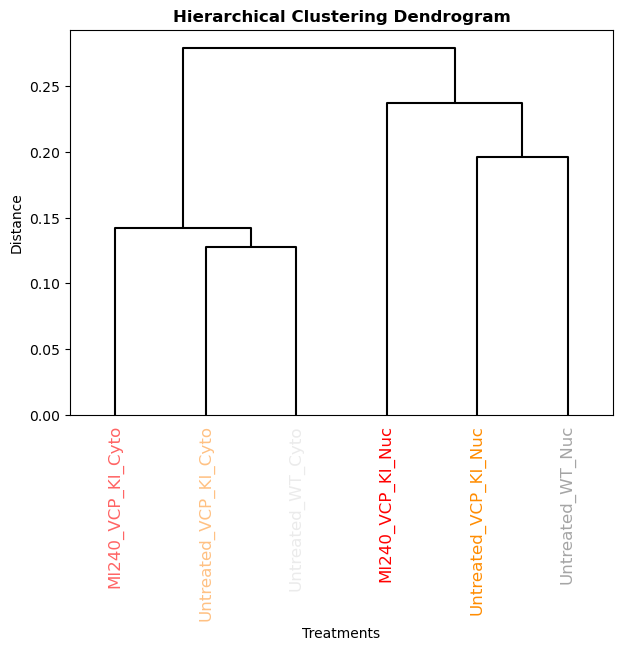

In [33]:
## Hierarchical clustering of treatments (PUD)
# Leaves are treatments: samples of each treatment are averaged before clustering
pud_dataset.hierarchical_clustering(palette=ki_palette, treatments=ki_treatments, color_threshold=0, level="treatment")

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_SVD")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "dendrogram_treatments_PUD.pdf"),
            legend="VCP knock-in +- ML240, PUD of each 3'UTR pair: hierarchical clustering of the treatments "
                   "(samples of each treatment averaged; Spearman correlation, average linkage; omicstools). Untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells, nuclear and cytoplasmic fractions (ML240 VCP-KI nuclear: a single sample).")
plt.show()

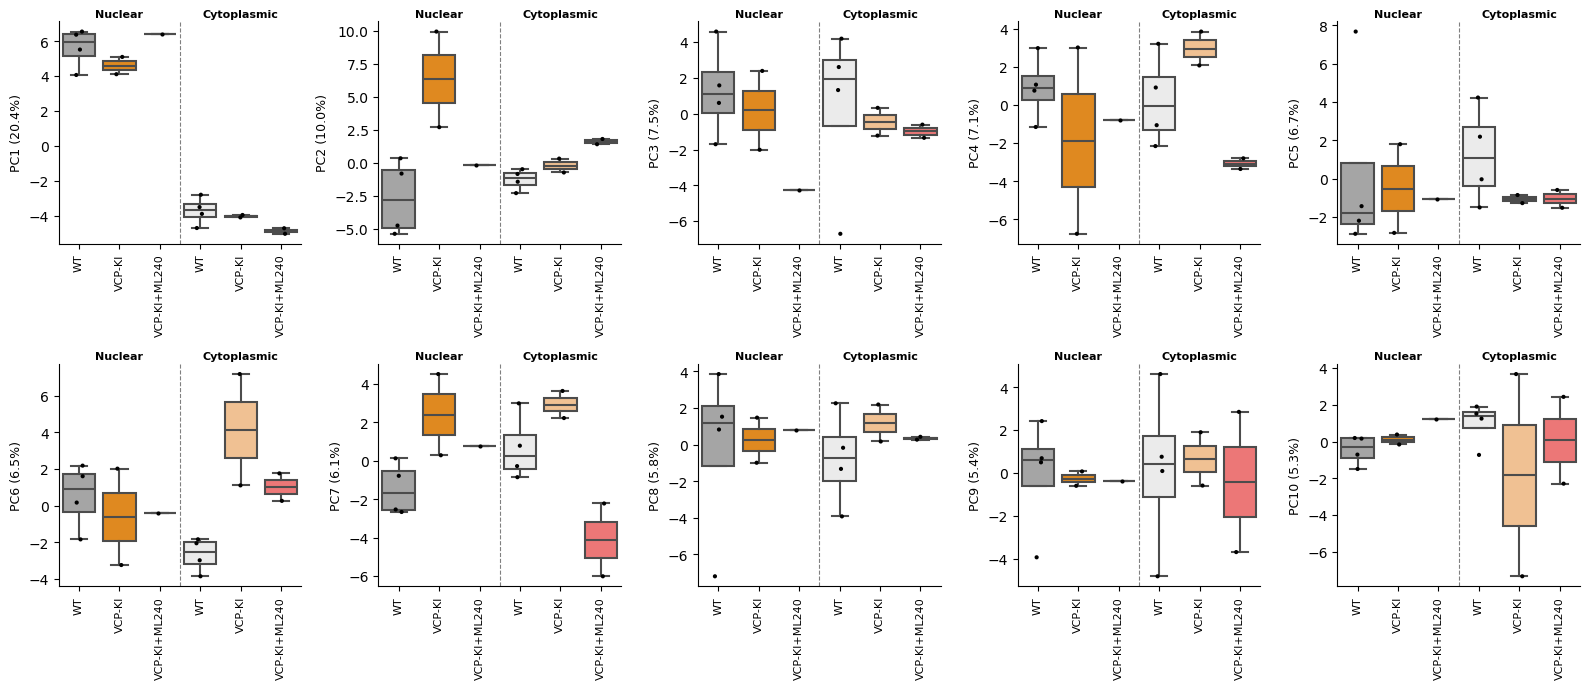

In [34]:
## PC scores per treatment (PUD)
plot_ki_pc_boxplots(pud_dataset)

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_SVD")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "boxplot_SVD_components_per_treatment_PUD.pdf"),
            legend="VCP knock-in +- ML240, PUD of each 3'UTR pair (SVD of the raw per-sample PUD): scores of the first 10 components after "
                   "removing the first one and recomputing the SVD (omicstools), per treatment, nuclear (left) and "
                   "cytoplasmic (right) samples; y-label = % of variance explained (s^2 share). Boxes without outliers, "
                   "one dot per sample. Untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells, nuclear and cytoplasmic fractions (ML240 VCP-KI nuclear: a single sample).")
plt.show()

<a id="mn-d35-volcano"></a>
## Volcano plots, VCP vs CTRL motor neurons at D35

Volcano plots of ΔPUD (VCP − CTRL) vs −log10(adjusted p) at D35, per fraction (the RUD criterion is not applied). Saved: `MN_3UTR_shifts_VCP_vs_CTRL/volcano_dPUD_VCP_vs_CTRL_D35.pdf`.

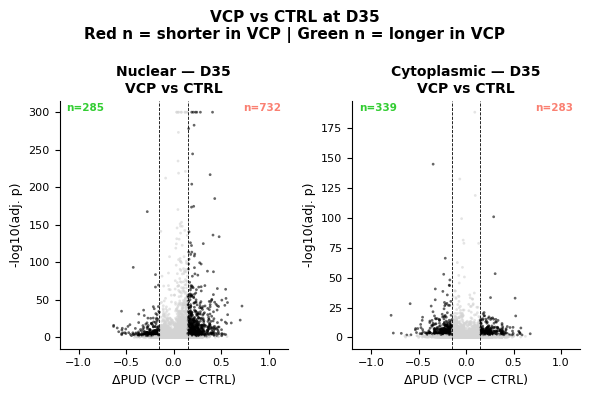

In [35]:

# Volcano plots: VCP vs CTRL at D35 — Nuclear and Cytoplasmic
volcano_pairs = [
    ("D35_Nuclear_Wildtype",     "D35_Nuclear_VCP",     "Nuclear — D35\nVCP vs CTRL"),
    ("D35_Cytoplasmic_Wildtype", "D35_Cytoplasmic_VCP", "Cytoplasmic — D35\nVCP vs CTRL"),
]

fig, axes = plt.subplots(1, 2, figsize=(6, 4))

for ax, (t1, t2, title) in zip(axes, volcano_pairs):
    suffix       = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"

    if adj_pval_col not in df_mn.columns or pud_t1_col not in df_mn.columns or pud_t2_col not in df_mn.columns:
        ax.text(0.5, 0.5, "not found", ha="center", va="center",
                transform=ax.transAxes, fontsize=9)
        ax.set_title(title, fontsize=10, weight="bold")
        sns.despine(ax=ax)
        continue
    
    rud_t1_col = f"RUD_{t1}"
    rud_t2_col = f"RUD_{t2}"



    plot_df = df_mn[[adj_pval_col, pud_t1_col, pud_t2_col, rud_t1_col, rud_t2_col]].dropna().copy()
    plot_df["delta_PUD"]      = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    plot_df["neg_log10_pval"] = -np.log10(plot_df[adj_pval_col].clip(lower=1e-300))
    
    if rud_t1_col in df_mn.columns and rud_t2_col in df_mn.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1
    else:
        rud_mask = pd.Series(True, index=plot_df.index)

    sig_short = ((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask).sum()
    sig_long  = ((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask).sum()

    # delta > 0: more proximal in VCP = shortening in VCP
    # delta < 0: more distal in VCP   = lengthening in VCP
    sig_short = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15)
    sig_long  = (plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15)
    sig_any   = sig_short | sig_long
    colors = sig_any.map({True: "black", False: "lightgray"})

    ax.scatter(plot_df["delta_PUD"], plot_df["neg_log10_pval"],
               c=colors, s=4, alpha=0.6, linewidths=0)
    ax.axvline( 0.15, color="black", linestyle="--", linewidth=0.6)
    ax.axvline(-0.15, color="black", linestyle="--", linewidth=0.6)
    ax.set_xlabel("ΔPUD (VCP − CTRL)", fontsize=9)
    ax.set_ylabel("-log10(adj. p)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_title(title, fontsize=10, weight="bold")
    ax.set_xlim(-1.2, 1.2)

    n_short = sig_short.sum()
    n_long  = sig_long.sum()
    ax.text(0.97, 0.99, f"n={n_short}", color="salmon", fontsize=7.5, weight="bold",
            ha="right", va="top", transform=ax.transAxes)
    ax.text(0.03, 0.99, f"n={n_long}", color="limegreen", fontsize=7.5, weight="bold",
            ha="left", va="top", transform=ax.transAxes)
    sns.despine(ax=ax)

plt.suptitle("VCP vs CTRL at D35\nRed n = shorter in VCP | Green n = longer in VCP",
             fontsize=11, weight="bold")
plt.tight_layout()


save_figure(f"{figures_subfolder}/MN_3UTR_shifts_VCP_vs_CTRL/volcano_dPUD_VCP_vs_CTRL_D35.pdf",
            legend="VCP vs CTRL motor neurons at D35, nuclear and cytoplasmic fractions: volcano plots of dPUD (VCP - "
                   "CTRL) vs -log10(adjusted Fisher p); black = adj. p < 0.01 and |dPUD| >= 0.15 (dashed lines); n = "
                   "significant pairs shorter (right, red) or longer (left, green) in VCP. The RUD criterion is not "
                   "applied here (unlike the shortening vs lengthening barplots).")
plt.show()


<a id="mn-d22-d35-counts"></a>
## 3'UTR shifts between D22 and D35 in CTRL motor neurons

Same barplot as the VCP vs CTRL counts above, for D22 → D35 in CTRL (maturation). Displayed only, not saved.

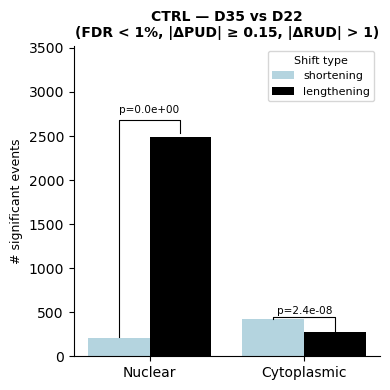

In [36]:
volcano_pairs = [
    ("D22_Nuclear_Wildtype",     "D35_Nuclear_Wildtype",     "Nuclear — D35 vs D22\nCTRL"),
    ("D22_Cytoplasmic_Wildtype", "D35_Cytoplasmic_Wildtype", "Cytoplasmic — D35 vs D22\nCTRL"),
]

# Barplot: significant shortening vs lengthening — CTRL MN, D35 vs D22
mn_d35_sig_counts = []
for t1, t2, title in volcano_pairs:
    suffix       = f"{t1}_{t2}"
    adj_pval_col = f"adjusted_fisher_pvalue_{suffix}"
    pud_t1_col   = f"PUD_{t1}"
    pud_t2_col   = f"PUD_{t2}"
    rud_t1_col   = f"RUD_{t1}"
    rud_t2_col   = f"RUD_{t2}"

    cols = [adj_pval_col, pud_t1_col, pud_t2_col]
    if rud_t1_col in df_mn.columns and rud_t2_col in df_mn.columns:
        cols += [rud_t1_col, rud_t2_col]
    plot_df = df_mn[cols].dropna().copy()
    plot_df["delta_PUD"] = plot_df[pud_t2_col] - plot_df[pud_t1_col]
    if rud_t1_col in df_mn.columns and rud_t2_col in df_mn.columns:
        plot_df["delta_RUD"] = plot_df[rud_t2_col] - plot_df[rud_t1_col]
        rud_mask = plot_df["delta_RUD"].abs() > 1
    else:
        rud_mask = pd.Series(True, index=plot_df.index)

    n_short = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] >=  0.15) & rud_mask).sum())
    n_long  = int(((plot_df[adj_pval_col] < 0.01) & (plot_df["delta_PUD"] <= -0.15) & rud_mask).sum())
    fraction = "Nuclear" if "Nuclear" in t2 else "Cytoplasmic"
    mn_d35_sig_counts.append({"fraction": fraction, "shortening": n_short, "lengthening": n_long})

counts_mn_d35 = pd.DataFrame(mn_d35_sig_counts)
counts_mn_d35_long = counts_mn_d35.melt(
    id_vars="fraction",
    value_vars=["shortening", "lengthening"],
    var_name="shift_type",
    value_name="n_events",
)

palette_shift = {"shortening": "lightblue", "lengthening": "black"}
fraction_order_mn = [f for f in ["Nuclear", "Cytoplasmic"] if f in counts_mn_d35["fraction"].values]

fig, ax = plt.subplots(figsize=(4, 4))
sns.barplot(
    data=counts_mn_d35_long,
    x="fraction",
    y="n_events",
    hue="shift_type",
    palette=palette_shift,
    order=fraction_order_mn,
    hue_order=["shortening", "lengthening"],
    ax=ax,
)

# Binomial test annotation per fraction
patches = sorted(ax.patches, key=lambda p: p.get_x())
for frac_idx, fraction in enumerate(fraction_order_mn):
    row = counts_mn_d35[counts_mn_d35["fraction"] == fraction]
    if row.empty:
        continue
    n_s = int(row["shortening"].values[0])
    n_l = int(row["lengthening"].values[0])
    total = n_s + n_l
    if total == 0:
        continue
    binom_result = stats.binomtest(n_s, total, p=0.5, alternative="two-sided")
    pval_label = f"p={binom_result.pvalue:.1e}"

    p_short = patches[frac_idx * 2]
    p_long  = patches[frac_idx * 2 + 1]
    x_s = p_short.get_x() + p_short.get_width() / 2
    x_l = p_long.get_x()  + p_long.get_width()  / 2
    h_s = p_short.get_height()
    h_l = p_long.get_height()
    y_top = max(h_s, h_l) * 1.08
    ax.plot([x_s, x_s, x_l, x_l], [h_s * 1.02, y_top, y_top, h_l * 1.02],
            color="black", lw=0.8)
    ax.text((x_s + x_l) / 2, y_top * 1.02, pval_label,
            ha="center", va="bottom", fontsize=7.5)

ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
ax.set_xlabel("")
ax.set_ylabel("# significant events", fontsize=9)
ax.set_title("CTRL — D35 vs D22\n(FDR < 1%, |ΔPUD| ≥ 0.15, |ΔRUD| > 1)", fontsize=10, weight="bold")
ax.legend(title="Shift type", fontsize=8, title_fontsize=8)
sns.despine(ax=ax)
plt.tight_layout()


plt.show()

<a id="nsd-genes-vcp"></a>
## Nervous system development genes shortened in VCP

Which genes in the "Nervous system development" GO term (GO:0007399) have the largest proximal shift in VCP?

Saved: `MN_pathway_enrichment/barplot_nervous_system_development_genes_top_dPUD_VCP_D35.pdf`.

Nervous system development (GO:0007399): 112 genes, FDR=2.17e-02


,gene,PUD_D35_Nuclear_Wildtype,PUD_D35_Nuclear_VCP,dPUD_Nuclear_WT_to_VCP
2085,EYA1,0.050616,0.600249,0.549633
3086,JAG2,0.010888,0.559305,0.548417
4011,NARS1,0.032627,0.511207,0.478580
2855,HOXA3,0.243505,0.715242,0.471738
49,ACAN,0.523742,0.970035,0.446293
3953,MYLIP,0.197168,0.629837,0.432670
4874,POU3F2,0.115138,0.547681,0.432543
6421,SUDS3,0.133806,0.558831,0.425025
7462,ZBTB16,0.417225,0.833256,0.416032
6622,TGFBR1,0.184332,0.585843,0.401511


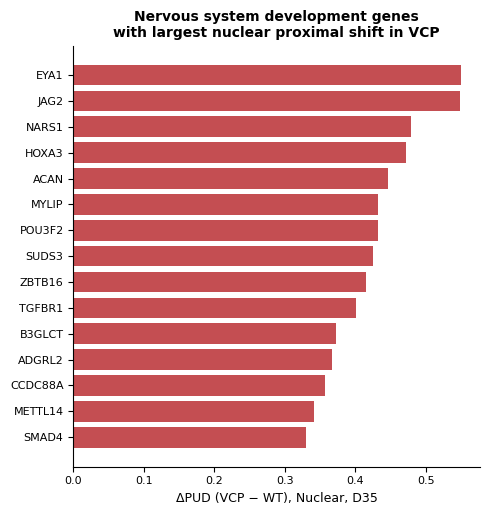

In [37]:
# Which "Nervous system development" (GO:0007399) genes drive the biggest
# proximal (3'UTR shortening) shift in VCP?
# shortening_events_in_VCP is defined from PUD_significance_D35_Nuclear_Wildtype_D35_Nuclear_VCP
# (see cell above querying STRING) — i.e. this is Nuclear-fraction-specific shortening
# (D35, Wildtype vs VCP), not a whole-cell/cytoplasmic effect.
nsd_term = _raw_vcp_shortening[
    (_raw_vcp_shortening["category"] == "Process") &
    (_raw_vcp_shortening["description"] == "Nervous system development")
].iloc[0]

nsd_genes = set(nsd_term["preferredNames"])
print(f"{nsd_term['description']} ({nsd_term['term']}): {len(nsd_genes)} genes, FDR={nsd_term['fdr']:.2e}")

nsd_shift = shortening_events_in_VCP[shortening_events_in_VCP["gene"].isin(nsd_genes)].copy()
nsd_shift["dPUD_Nuclear_WT_to_VCP"] = nsd_shift["PUD_D35_Nuclear_VCP"] - nsd_shift["PUD_D35_Nuclear_Wildtype"]
nsd_shift = nsd_shift.sort_values("dPUD_Nuclear_WT_to_VCP", ascending=False)

display(nsd_shift[["gene", "PUD_D35_Nuclear_Wildtype", "PUD_D35_Nuclear_VCP", "dPUD_Nuclear_WT_to_VCP"]].head(15))

top_n_nsd = 15
df_plot_nsd = nsd_shift.head(top_n_nsd).sort_values("dPUD_Nuclear_WT_to_VCP")

fig, ax = plt.subplots(figsize=(5, max(3, 0.35 * len(df_plot_nsd))))
ax.barh(df_plot_nsd["gene"], df_plot_nsd["dPUD_Nuclear_WT_to_VCP"], color="#C44E52")
ax.set_xlabel("ΔPUD (VCP − WT), Nuclear, D35", fontsize=9)
ax.set_title("Nervous system development genes\nwith largest nuclear proximal shift in VCP", fontsize=10, weight="bold")
ax.tick_params(labelsize=8)
sns.despine(ax=ax)
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "MN_pathway_enrichment")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "barplot_nervous_system_development_genes_top_dPUD_VCP_D35.pdf"),
            legend="Genes of the GO term 'Nervous system development' (GO:0007399, from the STRING enrichment of the "
                   "VCP-shortened genes) with a 3'UTR shortened in VCP vs CTRL nuclei at D35: the 15 with the largest "
                   "dPUD (VCP - CTRL, nuclear, D35).")
plt.show()


<a id="nefl-kd"></a>
## NEFL PUD upon SFPQ / TDP-43 / FUS knockdown

Mean ± SD across replicates, nuclear vs cytoplasmic fractions.

Saved: `SFPQ_TDP43_FUS_KD_example_genes/barplot_NEFL_PUD_nuclear_vs_cytoplasmic_KD.pdf`.

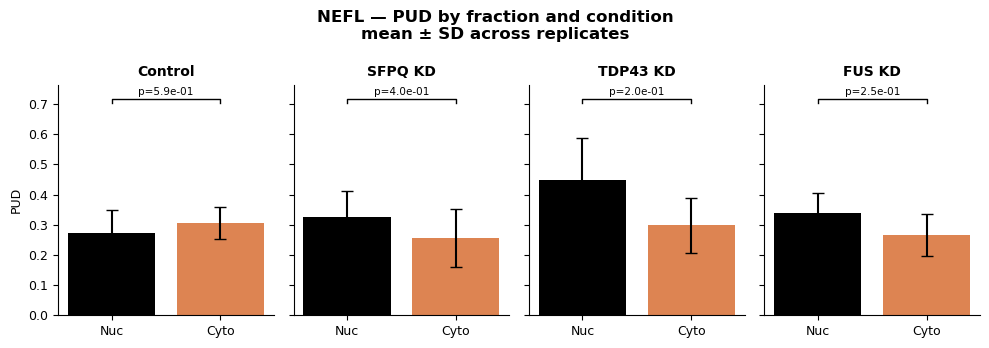

In [38]:
# PUD barplots for NEFL — Control, SFPQ KD, TDP43 KD, FUS KD (Nuc vs Cyto)
# mean +/- SD across the replicate samples listed in bulkapa.yaml (condition-level
# PUD_<condition> columns are themselves replicate averages, so we go back to the
# per-replicate PUD_<sample> columns for the error bars).
from scipy.stats import ttest_ind

kd_sample_map = {
    "Untreated_Cyto":  ["TYZ4001A1",  "TYZ4001A11", "TYZ4001A6"],
    "SFPQ_KD_Cyto":    ["TYZ4001A13", "TYZ4001A3",  "TYZ4001A8"],
    "TDP43_KD_Cyto":   ["TYZ4001A14", "TYZ4001A4",  "TYZ4001A9"],
    "FUS_KD_Cyto":     ["TYZ4001A10", "TYZ4001A15", "TYZ4001A5"],
    "Untreated_Nuc":   ["TYZ4001A16", "TYZ4001A21", "TYZ4001A26"],
    "SFPQ_KD_Nuc":     ["TYZ4001A18", "TYZ4001A23", "TYZ4001A28"],
    "TDP43_KD_Nuc":    ["TYZ4001A19", "TYZ4001A24", "TYZ4001A29"],
    "FUS_KD_Nuc":      ["TYZ4001A20", "TYZ4001A25", "TYZ4001A30"],
}

gene = "NEFL"
conditions = [
    ("Control",  "Untreated_Nuc", "Untreated_Cyto"),
    ("SFPQ KD",  "SFPQ_KD_Nuc",   "SFPQ_KD_Cyto"),
    ("TDP43 KD", "TDP43_KD_Nuc",  "TDP43_KD_Cyto"),
    ("FUS KD",   "FUS_KD_Nuc",    "FUS_KD_Cyto"),
]

gene_row = df[df["gene"] == gene]

fig, axes = plt.subplots(1, 4, figsize=(10, 3.5), sharey=True)

all_means, all_stds = [], []
p_vals = []
for ax, (title, nuc_col, cyto_col) in zip(axes, conditions):
    means, stds, raw_vals = [], [], []
    for cond in (nuc_col, cyto_col):
        samples = kd_sample_map[cond]
        vals = gene_row[[f"PUD_{s}" for s in samples]].values.flatten().astype(float)
        vals = vals[~np.isnan(vals)]
        raw_vals.append(vals)
        means.append(np.nanmean(vals))
        stds.append(np.nanstd(vals, ddof=1) if len(vals) > 1 else 0.0)
    all_means += means
    all_stds += stds

    nuc_vals, cyto_vals = raw_vals
    if len(nuc_vals) > 1 and len(cyto_vals) > 1:
        _, p_val = ttest_ind(nuc_vals, cyto_vals, alternative="two-sided", equal_var=False)
    else:
        p_val = np.nan
    p_vals.append(p_val)

    ax.bar(["Nuc", "Cyto"], means, yerr=stds, capsize=4, color=["black", "#DD8452"])
    ax.set_title(title, fontsize=10, weight="bold")
    ax.tick_params(labelsize=9)
    sns.despine(ax=ax)

ylim_top = max(m + s for m, s in zip(all_means, all_stds)) * 1.3
for ax in axes:
    ax.set_ylim(0, ylim_top)

for ax, (title, nuc_col, cyto_col), p_val in zip(axes, conditions, p_vals):
    y_bracket = ylim_top * 0.92
    ax.plot([0, 0, 1, 1], [y_bracket, y_bracket * 1.02, y_bracket * 1.02, y_bracket],
            lw=1, color="black")
    label = f"p={p_val:.1e}" if not np.isnan(p_val) else "n/a"
    ax.text(0.5, y_bracket * 1.03, label, ha="center", va="bottom", fontsize=7.5)

axes[0].set_ylabel("PUD", fontsize=9)
plt.suptitle(f"{gene} — PUD by fraction and condition\nmean ± SD across replicates", fontsize=12, weight="bold")
plt.tight_layout()

save_figure(f"{figures_subfolder}/SFPQ_TDP43_FUS_KD_example_genes/barplot_{gene}_PUD_nuclear_vs_cytoplasmic_KD.pdf",
            legend=f"{gene} PUD in untreated, SFPQ KD, TDP-43 KD and FUS KD cells, nuclear (black) vs cytoplasmic "
                   "(orange) fraction: mean +- SD across the 3 replicates; p = two-sided Welch's t-test nuclear vs "
                   "cytoplasmic.")
plt.show()


<a id="kd-go"></a>
## Biological processes enriched among genes shortened upon knockdown

STRING queries on genes with a nuclear proximal shift for each KD, then a bubble plot comparing the three KDs.

Saved: `SFPQ_TDP43_FUS_KD_pathway_enrichment/bubble_GO_BP_shortening_nuclear_SFPQ_TDP43_FUS_KD.pdf`.

In [39]:
from utrals.string_api import get_string_enrichment, add_strength_and_signal, to_pathways_format

# Proximal shift (shortening) in KD relative to Untreated, Nuclear fraction —
# genes_proximals_A_vs_B = proximal (shortening) shift in B relative to A
# (same convention as genes_distals_D22_..._vs_D35_... = distal shift used above).
shifts_dir_kd = f"{PROJECT_DIR}/SFPQ_TDP_FUS_KD/results/3UTR_analysis/shifts"

kd_gene_files = {
    "SFPQ KD":  "genes_proximals_Untreated_Nuc_vs_SFPQ_KD_Nuc.csv",
    "TDP43 KD": "genes_proximals_Untreated_Nuc_vs_TDP43_KD_Nuc.csv",
    "FUS KD":   "genes_proximals_Untreated_Nuc_vs_FUS_KD_Nuc.csv",
}

df_kd_pathways = {}
raw_kd_pathways = {}
for cond, fname in kd_gene_files.items():
    with open(f"{shifts_dir_kd}/{fname}") as f:
        genes = [line.strip() for line in f if line.strip()]
    print(f"Querying STRING for {cond} ({len(genes)} genes)...")
    raw = add_strength_and_signal(get_string_enrichment(genes))
    raw_kd_pathways[cond] = raw
    df_kd_pathways[cond] = to_pathways_format(raw[raw["category"] == "Process"])
    print(f"  {len(df_kd_pathways[cond])} GO Process terms")


Querying STRING for SFPQ KD (204 genes)...
  0 GO Process terms
Querying STRING for TDP43 KD (365 genes)...
  0 GO Process terms
Querying STRING for FUS KD (256 genes)...
  0 GO Process terms


Selected 0 unique terms (top 10 non-redundant per condition, union)


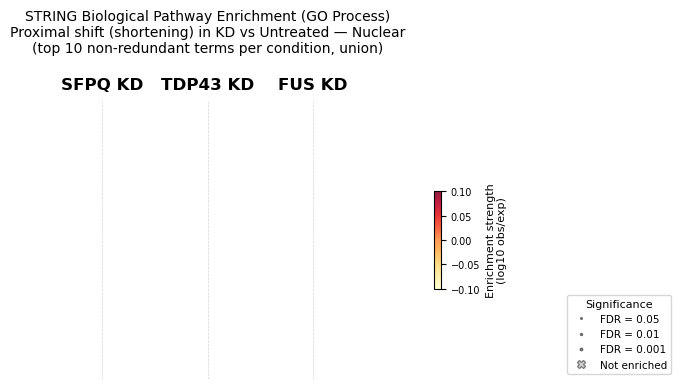

In [40]:
from functools import reduce
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

bg_threshold = 10000
conditions_kd = list(kd_gene_files.keys())

# Reuses _extract()/_to_long()/select_top_nonredundant() defined in the GO cell
# above (MN_diff section): colours by "strength" (size-independent log10 obs/exp),
# not STRING's "signal", since signal is mechanically biased by input gene-list
# size (FDR is smaller for larger lists), and the three KD gene lists are very
# different sizes.
#
# Select top `top_n` non-redundant terms per condition, then union across
# conditions — but look up each selected term's true strength/FDR/presence in
# every condition's FULL (bg_threshold-filtered) result, not just its own top-N
# subset. Otherwise a term that makes e.g. TDP43 KD's top 10 but was also
# significantly enriched in SFPQ KD (just ranked outside SFPQ KD's own top 10)
# would incorrectly draw as a "not enriched" cross for SFPQ KD.
top_terms_kd = {
    cond: set(select_top_nonredundant(df, raw_kd_pathways[cond], top_n=top_n, bg_threshold=bg_threshold)["term description"])
    for cond, df in df_kd_pathways.items()
}
selected_terms_kd = set().union(*top_terms_kd.values())

kd_extracted = {
    cond: _extract(df[df["term description"].isin(selected_terms_kd)], cond, bg_threshold)
    for cond, df in df_kd_pathways.items()
}

merged_kd = reduce(lambda l, r: pd.merge(l, r, how="outer", on="pathway"), kd_extracted.values())
for cond in conditions_kd:
    merged_kd[f"strength_{cond}"] = merged_kd[f"strength_{cond}"].fillna(0)
    merged_kd[f"fdr_{cond}"] = merged_kd[f"fdr_{cond}"].fillna(1)
    merged_kd[f"present_{cond}"] = merged_kd[f"present_{cond}"].fillna(False)

df_long_kd = pd.concat([_to_long(merged_kd, cond) for cond in conditions_kd], ignore_index=True)
df_long_kd["neg_log10_fdr"] = -np.log10(df_long_kd["fdr"].clip(lower=1e-10))

print(f"Selected {len(selected_terms_kd)} unique terms (top {top_n} non-redundant per condition, union)")

# ── Ordering: sort pathways by maximum strength (highest at top) ────────────
strength_cols = [f"strength_{c}" for c in conditions_kd]
pathway_order = (
    merged_kd
    .assign(max_strength=merged_kd[strength_cols].max(axis=1))
    .sort_values("max_strength", ascending=True)["pathway"]
    .tolist()
)
n_pathways = len(pathway_order)

x_positions = {cond: i * 2 for i, cond in enumerate(conditions_kd)}
df_long_kd["y"] = df_long_kd["pathway"].map({p: i for i, p in enumerate(pathway_order)})
df_long_kd["x"] = df_long_kd["condition"].map(x_positions)

# ── Colour scale (enrichment strength, size-independent) ───────────────────
vmax = df_long_kd["strength"].max()
norm = mcolors.Normalize(vmin=0, vmax=vmax)
cmap = plt.cm.YlOrRd

# ── Bubble size scale (-log10 FDR) ─────────────────────────────────────────
present_mask = df_long_kd["present"]
absent_mask  = ~present_mask

max_neg_log  = df_long_kd.loc[present_mask, "neg_log10_fdr"].max()
max_dot_size = 450
size_scale   = max_dot_size / max_neg_log if max_neg_log > 0 else 1

# ── Figure ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6.5, max(4, n_pathways * 0.48)))

sc = ax.scatter(
    df_long_kd.loc[present_mask, "x"],
    df_long_kd.loc[present_mask, "y"],
    c=df_long_kd.loc[present_mask, "strength"],
    cmap=cmap, norm=norm,
    s=df_long_kd.loc[present_mask, "neg_log10_fdr"] * size_scale,
    alpha=0.88, linewidths=0.5, edgecolors="dimgray", zorder=3,
)

if absent_mask.any():
    ax.scatter(
        df_long_kd.loc[absent_mask, "x"],
        df_long_kd.loc[absent_mask, "y"],
        c="lightgray", s=50, marker="X",
        alpha=0.65, linewidths=0.4, edgecolors="gray", zorder=2,
    )

ax.set_xticks(list(x_positions.values()))
ax.set_xticklabels(list(x_positions.keys()), fontsize=12, fontweight="bold")
ax.xaxis.set_ticks_position("top")
ax.xaxis.set_label_position("top")
ax.tick_params(axis="x", pad=6, length=0)

ax.set_yticks(range(n_pathways))
ax.set_yticklabels(pathway_order, fontsize=8)

ax.set_xlim(-0.8, max(x_positions.values()) + 0.8)
ax.set_ylim(-0.7, n_pathways - 0.3)

ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, color="lightgray", zorder=0)
ax.grid(axis="y", linestyle=":",  linewidth=0.4, color="lightgray", zorder=0)
ax.set_axisbelow(True)

# ── Colorbar ─────────────────────────────────────────────────────────────
cbar = plt.colorbar(sc, ax=ax, shrink=0.35, pad=0.18, aspect=15)
cbar.set_label("Enrichment strength\n(log10 obs/exp)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# ── Size legend (significance) ──────────────────────────────────────────
fdr_ticks = [0.05, 0.01, 0.001]
size_handles = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="gray", markeredgecolor="dimgray",
           markersize=np.sqrt(-np.log10(f) * size_scale),
           label=f"FDR = {f}")
    for f in fdr_ticks
]
size_handles.append(
    Line2D([0], [0], marker="X", color="w",
           markerfacecolor="lightgray", markeredgecolor="gray",
           markersize=6, label="Not enriched")
)
ax.legend(
    handles=size_handles,
    title="Significance", title_fontsize=8,
    fontsize=7.5, frameon=True,
    bbox_to_anchor=(1.7, 0.0), loc="lower left",
)

plt.title(f"STRING Biological Pathway Enrichment (GO Process)\nProximal shift (shortening) in KD vs Untreated — Nuclear\n(top {top_n} non-redundant terms per condition, union)", fontsize=10, pad=18)
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "SFPQ_TDP43_FUS_KD_pathway_enrichment")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "bubble_GO_BP_shortening_nuclear_SFPQ_TDP43_FUS_KD.pdf"),
            legend=f"STRING GO Biological Process enrichment of the genes with a nuclear 3'UTR shortened upon SFPQ, "
                   f"TDP-43 and FUS knockdown vs untreated: union of the top {top_n} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed) of each knockdown. "
                   "Colour = strength (log10 observed/expected), bubble size = -log10(FDR) in that knockdown; grey "
                   "cross = not enriched.")
plt.show()


<a id="vcp-ki-go-nefl"></a>
## Pathway enrichment and NEFL in VCP knock-in cells

Inspection of the VCP-KI table, STRING enrichment of genes shortened in VCP-KI vs WT (nuclear fraction), and NEFL PUD across WT / VCP-KI / ML240-treated VCP-KI.

Saved: `VCP-KI_pathway_enrichment/barplot_GO_BP_VCP-KI_shortened_nuclear.pdf` and `VCP-KI_ML240_example_genes/barplot_NEFL_PUD_nuclear_vs_cytoplasmic_VCP-KI_ML240.pdf`.

In [41]:
df_ki

,index_prox,proximal_id,strand_prox,SRR21683985_prox,SRR21683986_prox,SRR21684008_prox,SRR21684009_prox,SRR21683997_prox,SRR21683998_prox,SRR21684020_prox,...,DUD_significance_Untreated_WT_Cyto_Untreated_VCP_KI_Cyto,PUD_significance_Untreated_WT_Nuc_Untreated_VCP_KI_Nuc,RUD_significance_Untreated_WT_Nuc_Untreated_VCP_KI_Nuc,DUD_significance_Untreated_WT_Nuc_Untreated_VCP_KI_Nuc,PUD_significance_Untreated_VCP_KI_Nuc_Ml240_VCP_KI_Nuc,RUD_significance_Untreated_VCP_KI_Nuc_Ml240_VCP_KI_Nuc,DUD_significance_Untreated_VCP_KI_Nuc_Ml240_VCP_KI_Nuc,PUD_significance_Untreated_VCP_KI_Cyto_Ml240_VCP_KI_Cyto,RUD_significance_Untreated_VCP_KI_Cyto_Ml240_VCP_KI_Cyto,DUD_significance_Untreated_VCP_KI_Cyto_Ml240_VCP_KI_Cyto
0,21615,A1BG.2.ENST00000263100.MUT2.D35.Nuclear.VCP-R155C,-,322.723404,236.553191,203.595745,214.765957,188.914894,214.382979,214.563830,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Significant distal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant
1,17766,AAGAB.2.ENST00000542650.MUT3.D7.Nuclear.VCP-R191Q,-,456.010638,478.819149,435.744681,552.021277,294.510638,224.127660,253.872340,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
2,3390,AAK1.2.ENST00000409068.CTRL4.D14.Cytoplasmic.W...,-,0.000000,45.202128,58.617021,35.702128,0.127660,4.180851,94.765957,...,Non-Significant,Non-Significant,Significant distal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
3,8505,AARS2.1.ENST00000244571.CTRL1.D14.Cytoplasmic....,-,168.702128,103.914894,202.553191,112.021277,710.744681,403.127660,870.617021,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
4,12956,AASDHPPT.1.ENST00000278618.MUT4.D0.Nuclear.VCP...,+,1340.297872,1010.574468,1582.085106,1135.276596,396.000000,134.372340,288.170213,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6991,10584,ZXDA.1.ENST00000358697.MUT1.D22.Cytoplasmic.VC...,-,57.382979,23.361702,4.702128,2.234043,50.510638,20.021277,0.659574,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant
6992,10183,ZXDB.3.ENST00000374888.CTRL1.D22.Cytoplasmic.W...,+,35.680851,43.446809,6.510638,16.914894,37.765957,64.702128,46.170213,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Significant distal shift,Significant distal shift,Significant distal shift,Non-Significant,Non-Significant,Non-Significant
6993,354,ZYG11B.1.ENST00000294353.CTRL1.D0.Nuclear.Wild...,+,9.510638,0.000000,36.404255,62.574468,0.127660,4.180851,15.936170,...,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Significant proximal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant
6994,19152,ZZEF1.1.ENST00000381638.MUT2.D0.Cytoplasmic.VC...,-,0.000000,46.106383,67.617021,11.978723,51.872340,4.180851,0.659574,...,Non-Significant,Non-Significant,Significant distal shift,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Non-Significant,Significant distal shift,Non-Significant


In [42]:
# Pathway analysis: genes shortened (proximal shift) in Nuc, Untreated VCP-KI vs WT
from utrals.string_api import get_string_enrichment, add_strength_and_signal, to_pathways_format

shifts_dir_ki = f"{PROJECT_DIR}/VCP-KI-Ml240/results/3UTR_analysis/shifts"
with open(f"{shifts_dir_ki}/genes_proximals_Untreated_WT_Nuc_vs_Untreated_VCP_KI_Nuc.csv") as f:
    genes_ki_shortened_nuc = [line.strip() for line in f if line.strip()]

print(f"Querying STRING for VCP-KI shortening (Nuc) ({len(genes_ki_shortened_nuc)} genes)...")
raw_ki_shortened = add_strength_and_signal(get_string_enrichment(genes_ki_shortened_nuc))
df_ki_shortened_go = to_pathways_format(raw_ki_shortened[raw_ki_shortened["category"] == "Process"])
df_ki_shortened_go = df_ki_shortened_go[df_ki_shortened_go["background gene count"] < 10000]
print(f"{len(df_ki_shortened_go)} GO Process terms")
df_ki_shortened_go.head(10)


Querying STRING for VCP-KI shortening (Nuc) (701 genes)...
50 GO Process terms


,term ID,term description,observed gene count,background gene count,strength,signal,false discovery rate
6,GO:0000902,Cell morphogenesis,60,727,0.37,0.69,0.000004
7,GO:0048812,Neuron projection morphogenesis,47,505,0.42,0.78,0.000005
9,GO:0009653,Anatomical structure morphogenesis,129,2291,0.20,0.38,0.000049
10,GO:0023051,Regulation of signaling,181,3533,0.16,0.31,0.000049
11,GO:0080090,Regulation of primary metabolic process,243,5090,0.13,0.25,0.000049
12,GO:0007399,Nervous system development,128,2289,0.20,0.38,0.000072
13,GO:0048667,Cell morphogenesis involved in neuron differen...,40,462,0.39,0.70,0.000180
14,GO:0019222,Regulation of metabolic process,280,6170,0.11,0.21,0.000220
18,GO:0060255,Regulation of macromolecule metabolic process,259,5624,0.11,0.22,0.000230
17,GO:0051252,Regulation of RNA metabolic process,180,3611,0.15,0.28,0.000230


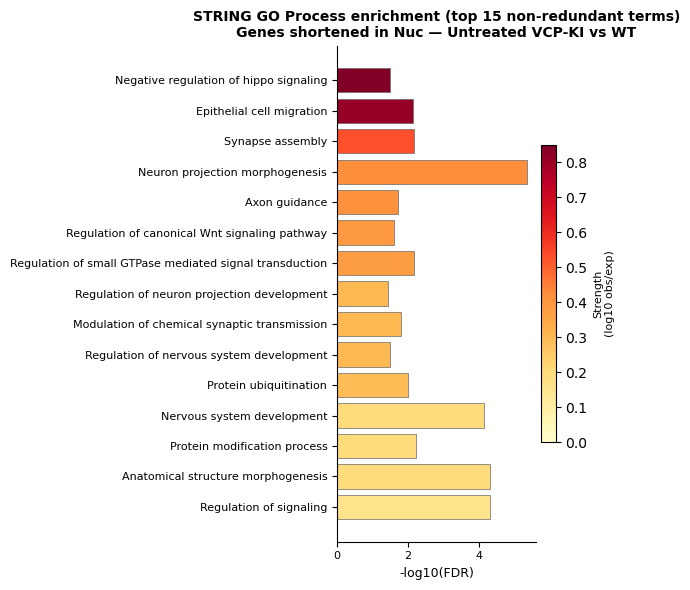

In [43]:
import matplotlib.colors as mcolors

# Curate with the same helper used for the Lengthening-vs-VCP bubble plot above:
# select_top_nonredundant() ranks terms by "strength" (size-independent log10
# obs/exp) and greedily keeps the top `top_n`, dropping any term whose STRING
# member-gene set overlaps an already-kept, stronger term above the Jaccard
# threshold (near-duplicate GO terms, e.g. a parent/child pair enriched for
# almost the same genes).
top_n_ki_bar = 15
df_plot_ki_go = select_top_nonredundant(df_ki_shortened_go, raw_ki_shortened, top_n=top_n_ki_bar, bg_threshold=10000)
df_plot_ki_go = df_plot_ki_go.sort_values("strength")

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_ki_go))))
norm = mcolors.Normalize(vmin=0, vmax=df_plot_ki_go["strength"].max())
cmap = plt.cm.YlOrRd
ax.barh(
    df_plot_ki_go["term description"],
    -np.log10(df_plot_ki_go["false discovery rate"]),
    color=cmap(norm(df_plot_ki_go["strength"])),
    edgecolor="dimgray", linewidth=0.5,
)
ax.set_xlabel("-log10(FDR)", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(f"STRING GO Process enrichment (top {top_n_ki_bar} non-redundant terms)\nGenes shortened in Nuc — Untreated VCP-KI vs WT", fontsize=10, weight="bold")
sns.despine(ax=ax)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Strength\n(log10 obs/exp)", fontsize=8)
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "VCP-KI_pathway_enrichment")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "barplot_GO_BP_VCP-KI_shortened_nuclear.pdf"),
            legend=f"STRING GO Biological Process enrichment of the genes with a nuclear 3'UTR shortened in untreated "
                   f"VCP-KI vs WT cells: top {top_n_ki_bar} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed). Bar = -log10(FDR), colour = strength. "
                   "")
plt.show()


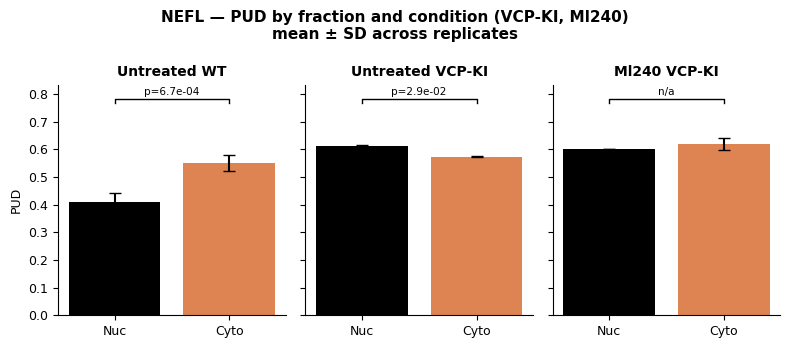

In [44]:
# NEFL PUD by fraction across Untreated WT / Untreated VCP-KI / Ml240 VCP-KI,
# mean +/- SD computed across the replicate SRR runs listed in bulkapa.yaml
# (condition-level PUD_<condition> columns are themselves replicate averages,
# so we go back to the per-replicate PUD_<SRR> columns for the error bars).
from scipy.stats import ttest_ind

ki_srr_map = {
    "Untreated_WT_Nuc":      ["SRR21684028", "SRR21684029", "SRR21684030", "SRR21684031"],
    "Untreated_WT_Cyto":     ["SRR21684016", "SRR21684017", "SRR21684018", "SRR21684019"],
    "Untreated_VCP_KI_Nuc":  ["SRR21684022", "SRR21684023"],
    "Untreated_VCP_KI_Cyto": ["SRR21684010", "SRR21684011"],
    "Ml240_VCP_KI_Nuc":      ["SRR21683999"],                    # single replicate -> SD = 0
    "Ml240_VCP_KI_Cyto":     ["SRR21683987", "SRR21683988"],
}

gene = "NEFL"
gene_row_ki = df_ki[df_ki["gene"] == gene]

conditions_ki = [
    ("Untreated WT",     "Untreated_WT_Nuc",     "Untreated_WT_Cyto"),
    ("Untreated VCP-KI", "Untreated_VCP_KI_Nuc", "Untreated_VCP_KI_Cyto"),
    ("Ml240 VCP-KI",     "Ml240_VCP_KI_Nuc",      "Ml240_VCP_KI_Cyto"),
]

fig, axes = plt.subplots(1, 3, figsize=(8, 3.5), sharey=True)

all_means, all_stds = [], []
p_vals = []
for ax, (title, nuc_cond, cyto_cond) in zip(axes, conditions_ki):
    means, stds, raw_vals = [], [], []
    for cond in (nuc_cond, cyto_cond):
        srrs = ki_srr_map[cond]
        vals = gene_row_ki[[f"PUD_{srr}" for srr in srrs]].values.flatten().astype(float)
        vals = vals[~np.isnan(vals)]
        raw_vals.append(vals)
        means.append(np.nanmean(vals))
        stds.append(np.nanstd(vals, ddof=1) if len(vals) > 1 else 0.0)
    all_means += means
    all_stds += stds

    nuc_vals, cyto_vals = raw_vals
    if len(nuc_vals) > 1 and len(cyto_vals) > 1:
        _, p_val = ttest_ind(nuc_vals, cyto_vals, alternative="two-sided", equal_var=False)
    else:
        p_val = np.nan
    p_vals.append(p_val)

    ax.bar(["Nuc", "Cyto"], means, yerr=stds, capsize=4, color=["black", "#DD8452"])
    ax.set_title(title, fontsize=10, weight="bold")
    ax.tick_params(labelsize=9)
    sns.despine(ax=ax)

ylim_top = max(m + s for m, s in zip(all_means, all_stds)) * 1.3
for ax in axes:
    ax.set_ylim(0, ylim_top)

for ax, (title, nuc_cond, cyto_cond), p_val in zip(axes, conditions_ki, p_vals):
    y_bracket = ylim_top * 0.92
    ax.plot([0, 0, 1, 1], [y_bracket, y_bracket * 1.02, y_bracket * 1.02, y_bracket],
            lw=1, color="black")
    label = f"p={p_val:.1e}" if not np.isnan(p_val) else "n/a"
    ax.text(0.5, y_bracket * 1.03, label, ha="center", va="bottom", fontsize=7.5)

axes[0].set_ylabel("PUD", fontsize=9)
plt.suptitle(f"{gene} — PUD by fraction and condition (VCP-KI, Ml240)\nmean ± SD across replicates", fontsize=11, weight="bold")
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "VCP-KI_ML240_example_genes")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, f"barplot_{gene}_PUD_nuclear_vs_cytoplasmic_VCP-KI_ML240.pdf"),
            legend=f"{gene} PUD in untreated WT, untreated VCP-KI and ML240-treated VCP-KI cells, nuclear (black) vs "
                   "cytoplasmic (orange): mean +- SD across replicates (ML240 VCP-KI nuclear: one sample, SD = 0); "
                   "p = two-sided Welch's t-test nuclear vs cytoplasmic (n/a with a single sample).")
plt.show()


<a id="shared-go-terms"></a>
## GO terms shortened in both VCP motor neurons and VCP knock-in cells

Genes from "Nervous system development" and "Protein localization to membrane" that are shortened in both datasets.

Saved in `MN_VCP_and_VCP-KI_shared_shortening/`: `scatter_dPUD_MN_VCP_vs_VCP-KI_nervous_system_development_genes.pdf` and `scatter_dPUD_MN_VCP_vs_VCP-KI_protein_localization_to_membrane_genes.pdf`.

Nervous system development genes shortened in MN-diff VCP: 112
Nervous system development genes shortened in VCP-KI:      128
Shared (shortened in BOTH conditions):                     22


,gene,dPUD_MNdiff_VCP,dPUD_KI,combined_shift
1,ADGRL2,0.366861,0.351941,0.718802
4,BSN,0.268496,0.422613,0.691109
21,ZBTB16,0.416032,0.247425,0.663457
10,NARS1,0.478580,0.182348,0.660928
2,ARID1B,0.287948,0.363455,0.651403
9,NAIP,0.241371,0.362212,0.603583
8,MAL2,0.187645,0.398947,0.586592
17,SMAD4,0.329732,0.238672,0.568404
19,ULK2,0.310805,0.255130,0.565934
3,B3GLCT,0.372200,0.154304,0.526504


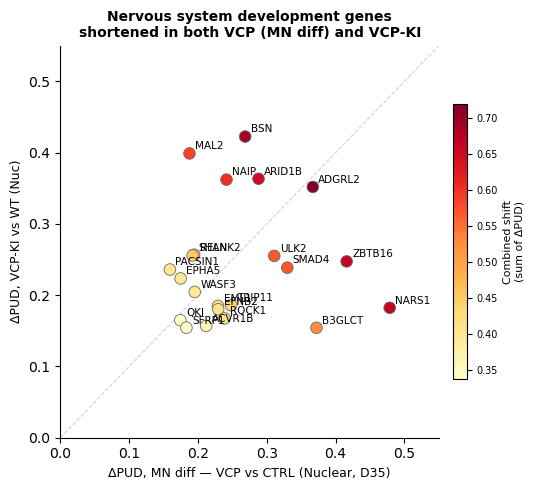

In [45]:
# ── "Nervous system development" (GO:0007399) genes shortened in BOTH
# conditions: VCP vs CTRL (MN diff, Nuclear, D35) AND VCP-KI vs WT (Nuc) ──────
#
# The GO term shows up as enriched in both the MN-diff VCP-shortening list and
# the VCP-KI-shortening list independently (see the bubble/bar plots above).
# Here we ask: which specific genes are driving BOTH signals — i.e. genes that
# (a) belong to "Nervous system development", (b) are significantly shortened
# (proximal PUD shift) in VCP vs CTRL (MN diff, Nuclear D35), AND (c) are also
# significantly shortened in VCP-KI vs WT (Nuc)?
nsd_genes_vcp_mndiff = set(_raw_vcp_shortening[
    (_raw_vcp_shortening["category"] == "Process") &
    (_raw_vcp_shortening["description"] == "Nervous system development")
].iloc[0]["preferredNames"])

nsd_row_ki = raw_ki_shortened[
    (raw_ki_shortened["category"] == "Process") &
    (raw_ki_shortened["description"] == "Nervous system development")
]
nsd_genes_ki = set(nsd_row_ki.iloc[0]["preferredNames"]) if len(nsd_row_ki) else set()

shared_nsd_genes = nsd_genes_vcp_mndiff & nsd_genes_ki
print(f"Nervous system development genes shortened in MN-diff VCP: {len(nsd_genes_vcp_mndiff)}")
print(f"Nervous system development genes shortened in VCP-KI:      {len(nsd_genes_ki)}")
print(f"Shared (shortened in BOTH conditions):                     {len(shared_nsd_genes)}")

# ΔPUD in each comparison (positive = more proximal = shortened)
mn_shift = df_mn[df_mn["gene"].isin(shared_nsd_genes)][["gene", "PUD_D35_Nuclear_Wildtype", "PUD_D35_Nuclear_VCP"]].copy()
mn_shift["dPUD_MNdiff_VCP"] = mn_shift["PUD_D35_Nuclear_VCP"] - mn_shift["PUD_D35_Nuclear_Wildtype"]

ki_shift = df_ki[df_ki["gene"].isin(shared_nsd_genes)][["gene", "PUD_Untreated_WT_Nuc", "PUD_Untreated_VCP_KI_Nuc"]].copy()
ki_shift["dPUD_KI"] = ki_shift["PUD_Untreated_VCP_KI_Nuc"] - ki_shift["PUD_Untreated_WT_Nuc"]

shared_nsd_shift = pd.merge(
    mn_shift[["gene", "dPUD_MNdiff_VCP"]],
    ki_shift[["gene", "dPUD_KI"]],
    on="gene",
)
shared_nsd_shift["combined_shift"] = shared_nsd_shift["dPUD_MNdiff_VCP"] + shared_nsd_shift["dPUD_KI"]
shared_nsd_shift = shared_nsd_shift.sort_values("combined_shift", ascending=False)

display(shared_nsd_shift)

# ── Scatter: ΔPUD in one condition vs the other, labelled by gene ───────────
fig, ax = plt.subplots(figsize=(5.5, 5))

lims = [0, max(shared_nsd_shift["dPUD_MNdiff_VCP"].max(), shared_nsd_shift["dPUD_KI"].max()) * 1.15]
ax.plot(lims, lims, ls="--", lw=0.8, color="lightgray", zorder=1)

norm = mcolors.Normalize(vmin=shared_nsd_shift["combined_shift"].min(), vmax=shared_nsd_shift["combined_shift"].max())
cmap = plt.cm.YlOrRd
sc = ax.scatter(
    shared_nsd_shift["dPUD_MNdiff_VCP"], shared_nsd_shift["dPUD_KI"],
    c=shared_nsd_shift["combined_shift"], cmap=cmap, norm=norm,
    s=70, edgecolors="dimgray", linewidths=0.6, zorder=3,
)

for _, row in shared_nsd_shift.iterrows():
    ax.annotate(
        row["gene"], (row["dPUD_MNdiff_VCP"], row["dPUD_KI"]),
        xytext=(4, 3), textcoords="offset points", fontsize=7.5,
    )

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("ΔPUD, MN diff — VCP vs CTRL (Nuclear, D35)", fontsize=9)
ax.set_ylabel("ΔPUD, VCP-KI vs WT (Nuc)", fontsize=9)
ax.set_title(
    "Nervous system development genes\nshortened in both VCP (MN diff) and VCP-KI",
    fontsize=10, weight="bold",
)
sns.despine(ax=ax)

cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.03)
cbar.set_label("Combined shift\n(sum of ΔPUD)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "MN_VCP_and_VCP-KI_shared_shortening")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "scatter_dPUD_MN_VCP_vs_VCP-KI_nervous_system_development_genes.pdf"),
            legend="Genes of 'Nervous system development' (GO:0007399) found in the STRING enrichment of both the "
                   "VCP-shortened (MN) and the VCP-KI-shortened gene lists: dPUD in MN VCP vs CTRL (nuclear, D35; x) vs dPUD in untreated VCP-KI vs WT (nuclear; y), one dot per gene; colour = sum of the two dPUD; dashed = identity line.")
plt.show()


Protein localization to membrane (GO:0072657), full GO annotation: 199 genes
PLM genes tested in both comparisons: 101
Significant (adj. p < 0.05) in BOTH comparisons:              41
Shortened (ΔPUD > 0) in BOTH conditions:                       13


,gene,dPUD_MNdiff_VCP,dPUD_VCP_KI,combined_shift
5149,SLMAP,0.151613,0.428884,0.580497
1144,CPE,0.402824,0.096680,0.499504
4530,RELN,0.194399,0.256803,0.451202
4665,ROCK1,0.238604,0.167382,0.405987
3736,PACSIN1,0.159163,0.236032,0.395195
1869,FCHO2,0.300382,0.071292,0.371675
6432,ZDHHC3,0.174335,0.170700,0.345035
2622,KCNB1,0.151173,0.050561,0.201734
1679,EPB41L3,0.084110,0.072687,0.156797
4442,RAPGEF2,0.097632,0.057910,0.155542


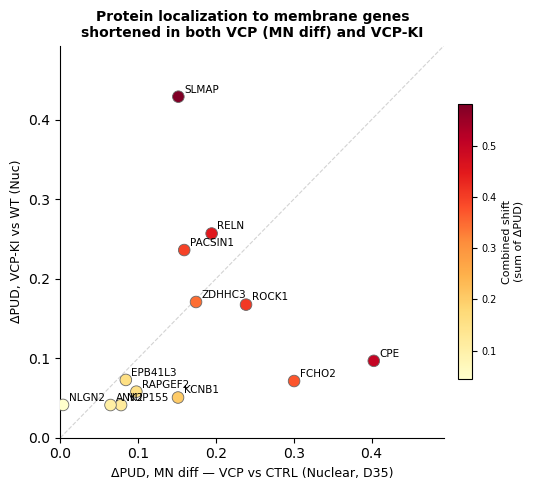

In [46]:
# ── "Protein localization to membrane" (GO:0072657) genes shortened in BOTH
# conditions: VCP vs CTRL (MN diff, Nuclear, D35) AND VCP-KI vs WT (Nuc) ──────
#
# Same question as the Nervous system development analysis above, for a
# different term. Unlike that one, STRING's own enrichment call for VCP-KI
# never returns "Protein localization to membrane" at all (checked directly —
# 0 rows), so intersecting the two STRING-context "preferredNames" sets (as
# done above) would trivially give an empty overlap. Instead we use the full,
# context-independent GO:0072657 gene set (199 genes, from Enrichr's
# GO_Biological_Process_2025 library — same source used for the genome-wide
# "top 200" analysis further down) and check significance/direction directly
# in the full result tables, so genes aren't excluded just because the term
# as a whole didn't clear STRING's significance bar in one of the two lists.
# Enrichr library downloaded once with gseapy, then read from ../cache/Enrichr/ (enrichr.get_enrichr_library)
plm_gene_set = set(enrichr.get_enrichr_library("GO_Biological_Process_2025")["Protein Localization to Membrane (GO:0072657)"])
print(f"Protein localization to membrane (GO:0072657), full GO annotation: {len(plm_gene_set)} genes")

# Self-contained (get_pud_shift() is defined later, in the genome-wide "top 200"
# section further down — duplicated inline here rather than depending on it).
def _get_pud_shift(df, gene_col, pud_before_col, pud_after_col, adj_pvalue_col, label):
    sub = df[[gene_col, pud_before_col, pud_after_col, adj_pvalue_col]].dropna().copy()
    sub[f"dPUD_{label}"] = sub[pud_after_col] - sub[pud_before_col]
    sub[f"sig_{label}"] = sub[adj_pvalue_col] < 0.05
    sub = sub.rename(columns={adj_pvalue_col: f"adjpval_{label}"})
    return sub[[gene_col, f"dPUD_{label}", f"adjpval_{label}", f"sig_{label}"]].drop_duplicates(subset=gene_col)

plm_mn_shift = _get_pud_shift(df_mn, "gene", "PUD_D35_Nuclear_Wildtype", "PUD_D35_Nuclear_VCP",
                               "adjusted_fisher_pvalue_D35_Nuclear_Wildtype_D35_Nuclear_VCP", "MNdiff_VCP")
plm_ki_shift = _get_pud_shift(df_ki, "gene", "PUD_Untreated_WT_Nuc", "PUD_Untreated_VCP_KI_Nuc",
                               "adjusted_fisher_pvalue_Untreated_WT_Nuc_Untreated_VCP_KI_Nuc", "VCP_KI")

plm_shift = plm_mn_shift.merge(plm_ki_shift, on="gene", how="inner")
plm_shift = plm_shift[plm_shift["gene"].isin(plm_gene_set)]
print(f"PLM genes tested in both comparisons: {len(plm_shift)}")

plm_shift_sig = plm_shift[plm_shift["sig_MNdiff_VCP"] & plm_shift["sig_VCP_KI"]].copy()
print(f"Significant (adj. p < 0.05) in BOTH comparisons:              {len(plm_shift_sig)}")

# Restrict to shortened (positive ΔPUD) in both, matching the "shortened in
# both conditions" framing of the NSD analysis above.
plm_shortened_both = plm_shift_sig[(plm_shift_sig["dPUD_MNdiff_VCP"] > 0) & (plm_shift_sig["dPUD_VCP_KI"] > 0)].copy()
print(f"Shortened (ΔPUD > 0) in BOTH conditions:                       {len(plm_shortened_both)}")

plm_shortened_both["combined_shift"] = plm_shortened_both["dPUD_MNdiff_VCP"] + plm_shortened_both["dPUD_VCP_KI"]
plm_shortened_both = plm_shortened_both.sort_values("combined_shift", ascending=False)

display(plm_shortened_both[["gene", "dPUD_MNdiff_VCP", "dPUD_VCP_KI", "combined_shift"]])

# ── Scatter: ΔPUD in one condition vs the other, labelled by gene ───────────
fig, ax = plt.subplots(figsize=(5.5, 5))

lims = [0, max(plm_shortened_both["dPUD_MNdiff_VCP"].max(), plm_shortened_both["dPUD_VCP_KI"].max()) * 1.15]
ax.plot(lims, lims, ls="--", lw=0.8, color="lightgray", zorder=1)

norm = mcolors.Normalize(vmin=plm_shortened_both["combined_shift"].min(), vmax=plm_shortened_both["combined_shift"].max())
cmap = plt.cm.YlOrRd
sc = ax.scatter(
    plm_shortened_both["dPUD_MNdiff_VCP"], plm_shortened_both["dPUD_VCP_KI"],
    c=plm_shortened_both["combined_shift"], cmap=cmap, norm=norm,
    s=70, edgecolors="dimgray", linewidths=0.6, zorder=3,
)

for _, row in plm_shortened_both.iterrows():
    ax.annotate(
        row["gene"], (row["dPUD_MNdiff_VCP"], row["dPUD_VCP_KI"]),
        xytext=(4, 3), textcoords="offset points", fontsize=7.5,
    )

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("ΔPUD, MN diff — VCP vs CTRL (Nuclear, D35)", fontsize=9)
ax.set_ylabel("ΔPUD, VCP-KI vs WT (Nuc)", fontsize=9)
ax.set_title(
    "Protein localization to membrane genes\nshortened in both VCP (MN diff) and VCP-KI",
    fontsize=10, weight="bold",
)
sns.despine(ax=ax)

cbar = plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.03)
cbar.set_label("Combined shift\n(sum of ΔPUD)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.tight_layout()

out_dir_plm = os.path.join(figures_subfolder, "MN_VCP_and_VCP-KI_shared_shortening")
os.makedirs(out_dir_plm, exist_ok=True)
save_figure(os.path.join(out_dir_plm, "scatter_dPUD_MN_VCP_vs_VCP-KI_protein_localization_to_membrane_genes.pdf"),
            legend="Genes of 'Protein localization to membrane' (GO:0072657, full annotation from Enrichr "
                   "GO_Biological_Process_2025) with a 3'UTR significantly shifted (adj. Fisher p < 0.05) and shortened "
                   "(dPUD > 0) in both comparisons: dPUD in MN VCP vs CTRL (nuclear, D35; x) vs dPUD in untreated VCP-KI vs WT (nuclear; y), one dot per gene; colour = sum of the two dPUD; dashed = identity line.")
plt.show()


<a id="vcp-vs-ki-pathways"></a>
## Pathways shortened in VCP motor neurons vs VCP knock-in cells

Bubble plot of the top non-redundant terms for each list.

Saved: `MN_VCP_and_VCP-KI_shared_shortening/bubble_GO_BP_shortening_MN_VCP_vs_VCP-KI.pdf`.

Selected 18 unique terms (top 10 non-redundant per list, union)
  True presence — VCP (MN-diff): 8 / VCP-KI (Nuc): 13


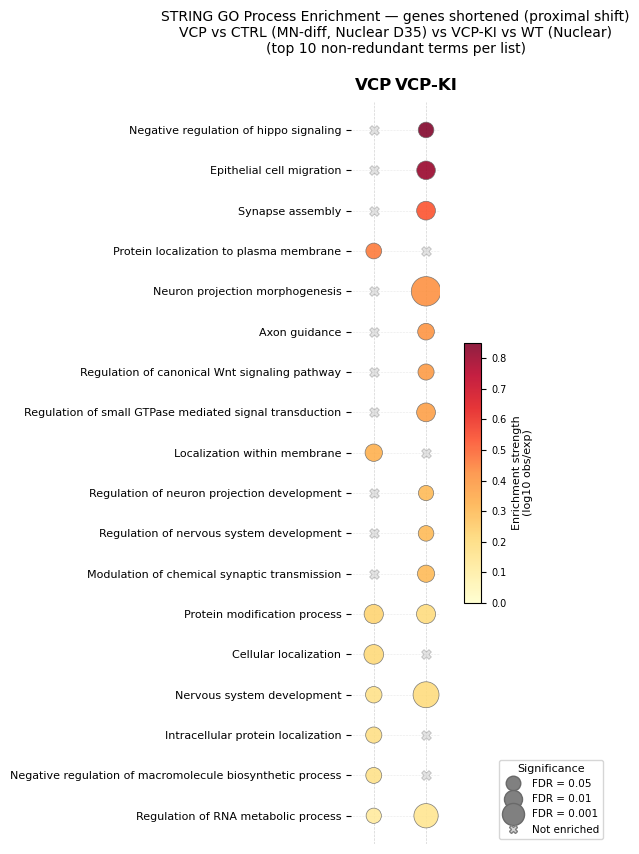

In [47]:
# ── Bubble plot: pathways shortened in VCP (MN-diff, Nuclear D35) vs
# pathways shortened in VCP-KI (Nuclear, Untreated VCP-KI vs WT) ─────────────
# Same layout/logic as the Lengthening-vs-VCP bubble plot above (_extract,
# select_top_nonredundant, _to_long are defined there and reused here).
top_n_vcp_vs_ki = 10
top_vcp_mndiff_terms = select_top_nonredundant(
    df_vcp_shortening, _raw_vcp_shortening, top_n=top_n_vcp_vs_ki, bg_threshold=bg_threshold
)["term description"]
top_vcp_ki_terms = select_top_nonredundant(
    df_ki_shortened_go, raw_ki_shortened, top_n=top_n_vcp_vs_ki, bg_threshold=bg_threshold
)["term description"]
selected_terms_vcp_vs_ki = set(top_vcp_mndiff_terms) | set(top_vcp_ki_terms)

vcp_mndiff_shortening = _extract(
    df_vcp_shortening[df_vcp_shortening["term description"].isin(selected_terms_vcp_vs_ki)],
    "VCP_MNdiff", bg_threshold,
)
vcp_ki_shortening = _extract(
    df_ki_shortened_go[df_ki_shortened_go["term description"].isin(selected_terms_vcp_vs_ki)],
    "VCP_KI", bg_threshold,
)
print(f"Selected {len(selected_terms_vcp_vs_ki)} unique terms (top {top_n_vcp_vs_ki} non-redundant per list, union)")
print(f"  True presence — VCP (MN-diff): {len(vcp_mndiff_shortening)} / VCP-KI (Nuc): {len(vcp_ki_shortening)}")

merged_vcp_vs_ki = pd.merge(vcp_mndiff_shortening, vcp_ki_shortening, how="outer", on="pathway")
for cond in ["VCP_MNdiff", "VCP_KI"]:
    merged_vcp_vs_ki[f"strength_{cond}"] = merged_vcp_vs_ki[f"strength_{cond}"].fillna(0)
    merged_vcp_vs_ki[f"fdr_{cond}"] = merged_vcp_vs_ki[f"fdr_{cond}"].fillna(1)
    merged_vcp_vs_ki[f"present_{cond}"] = merged_vcp_vs_ki[f"present_{cond}"].fillna(False)

df_long_vcp_vs_ki = pd.concat(
    [_to_long(merged_vcp_vs_ki, "VCP_MNdiff"), _to_long(merged_vcp_vs_ki, "VCP_KI")], ignore_index=True
)
df_long_vcp_vs_ki["neg_log10_fdr"] = -np.log10(df_long_vcp_vs_ki["fdr"].clip(lower=1e-10))

import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

# ── Ordering: sort pathways by maximum strength (highest at top) ────────────
pathway_order_vcp_vs_ki = (
    merged_vcp_vs_ki
    .assign(max_strength=merged_vcp_vs_ki[["strength_VCP_MNdiff", "strength_VCP_KI"]].max(axis=1))
    .sort_values("max_strength", ascending=True)["pathway"]
    .tolist()
)
n_pathways_vcp_vs_ki = len(pathway_order_vcp_vs_ki)

df_long_vcp_vs_ki["y"] = df_long_vcp_vs_ki["pathway"].map({p: i for i, p in enumerate(pathway_order_vcp_vs_ki)})
df_long_vcp_vs_ki["x"] = df_long_vcp_vs_ki["condition"].map({"VCP_MNdiff": 0, "VCP_KI": 3})

# ── Colour scale (enrichment strength, size-independent) ───────────────────
vmax_vcp_vs_ki = df_long_vcp_vs_ki["strength"].max()
norm_vcp_vs_ki = mcolors.Normalize(vmin=0, vmax=vmax_vcp_vs_ki)
cmap_vcp_vs_ki = plt.cm.YlOrRd

# ── Bubble size scale (-log10 FDR) ─────────────────────────────────────────
present_mask_vcp_vs_ki = df_long_vcp_vs_ki["present"]
absent_mask_vcp_vs_ki  = ~present_mask_vcp_vs_ki

max_neg_log_vcp_vs_ki  = df_long_vcp_vs_ki.loc[present_mask_vcp_vs_ki, "neg_log10_fdr"].max()
max_dot_size_vcp_vs_ki = 450                      # max bubble area in pt²
size_scale_vcp_vs_ki   = max_dot_size_vcp_vs_ki / max_neg_log_vcp_vs_ki if max_neg_log_vcp_vs_ki > 0 else 1

# ── Figure ──────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6.5, max(4, n_pathways_vcp_vs_ki * 0.48)))

# Present entries — coloured bubbles
sc = ax.scatter(
    df_long_vcp_vs_ki.loc[present_mask_vcp_vs_ki, "x"],
    df_long_vcp_vs_ki.loc[present_mask_vcp_vs_ki, "y"],
    c=df_long_vcp_vs_ki.loc[present_mask_vcp_vs_ki, "strength"],
    cmap=cmap_vcp_vs_ki, norm=norm_vcp_vs_ki,
    s=df_long_vcp_vs_ki.loc[present_mask_vcp_vs_ki, "neg_log10_fdr"] * size_scale_vcp_vs_ki,
    alpha=0.88, linewidths=0.5, edgecolors="dimgray", zorder=3,
)

# Absent entries — small light cross to indicate not enriched
if absent_mask_vcp_vs_ki.any():
    ax.scatter(
        df_long_vcp_vs_ki.loc[absent_mask_vcp_vs_ki, "x"],
        df_long_vcp_vs_ki.loc[absent_mask_vcp_vs_ki, "y"],
        c="lightgray", s=50, marker="X",
        alpha=0.65, linewidths=0.4, edgecolors="gray", zorder=2,
    )

# ── Axes formatting ─────────────────────────────────────────────────────────
ax.set_xticks([0, 3])
ax.set_xticklabels(["VCP", "VCP-KI"], fontsize=12, fontweight="bold")
ax.xaxis.set_ticks_position("top")
ax.xaxis.set_label_position("top")
ax.tick_params(axis="x", pad=6, length=0)

ax.set_yticks(range(n_pathways_vcp_vs_ki))
ax.set_yticklabels(pathway_order_vcp_vs_ki, fontsize=8)

ax.set_xlim(-1.3, 3.8)
ax.set_ylim(-0.7, n_pathways_vcp_vs_ki - 0.3)

ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, color="lightgray", zorder=0)
ax.grid(axis="y", linestyle=":",  linewidth=0.4, color="lightgray", zorder=0)
ax.set_axisbelow(True)

# ── Colorbar ────────────────────────────────────────────────────────────────
cbar = plt.colorbar(sc, ax=ax, shrink=0.35, pad=0.18, aspect=15)
cbar.set_label("Enrichment strength\n(log10 obs/exp)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# ── Size legend (significance) ───────────────────────────────────────────────
fdr_ticks_vcp_vs_ki = [0.05, 0.01, 0.001]
size_handles_vcp_vs_ki = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="gray", markeredgecolor="dimgray",
           markersize=np.sqrt(-np.log10(f) * size_scale_vcp_vs_ki),
           label=f"FDR = {f}")
    for f in fdr_ticks_vcp_vs_ki
]
size_handles_vcp_vs_ki.append(
    Line2D([0], [0], marker="X", color="w",
           markerfacecolor="lightgray", markeredgecolor="gray",
           markersize=6, label="Not enriched")
)
ax.legend(
    handles=size_handles_vcp_vs_ki,
    title="Significance", title_fontsize=8,
    fontsize=7.5, frameon=True,
    bbox_to_anchor=(1.6, 0.0), loc="lower left",
)

plt.title(
    f"STRING GO Process Enrichment — genes shortened (proximal shift)\n"
    f"VCP vs CTRL (MN-diff, Nuclear D35) vs VCP-KI vs WT (Nuclear)\n"
    f"(top {top_n_vcp_vs_ki} non-redundant terms per list)",
    fontsize=10, pad=18,
)
plt.tight_layout()

out_dir_vcp_vs_ki = os.path.join(figures_subfolder, "MN_VCP_and_VCP-KI_shared_shortening")
os.makedirs(out_dir_vcp_vs_ki, exist_ok=True)
save_figure(
    os.path.join(out_dir_vcp_vs_ki, "bubble_GO_BP_shortening_MN_VCP_vs_VCP-KI.pdf"),
    legend=f"STRING GO Biological Process enrichment of the genes with a nuclear 3'UTR shortened in VCP vs CTRL motor "
           "neurons at D35 ('VCP') and in untreated VCP-KI vs WT cells ('VCP-KI'): union of the top "
           f"{top_n_vcp_vs_ki} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed) of each list. Colour = strength, bubble size = -log10(FDR); grey cross = not "
           "enriched.",
)
plt.show()


<a id="checks"></a>
## Gene list and NEFL checks

Printed checks of the gene lists used above; no figure.

In [48]:
vcp_mndiff_shortening

,pathway,strength_VCP_MNdiff,fdr_VCP_MNdiff,present_VCP_MNdiff
16,Cellular localization,0.21,0.0043,True
17,Protein modification process,0.23,0.0053,True
19,Localization within membrane,0.33,0.0140,True
22,Nervous system development,0.17,0.0217,True
25,Intracellular protein localization,0.18,0.0246,True
27,Negative regulation of macromolecule biosynthe...,0.17,0.0275,True
29,Protein localization to plasma membrane,0.46,0.0294,True
30,Regulation of RNA metabolic process,0.12,0.0371,True


In [49]:
genes_ki_shortened_nuc

['ABCB10',
 'ABCB7',
 'ABHD2',
 'ABHD5',
 'ACOX1',
 'ACTR3',
 'ACVR1B',
 'ADAM8',
 'ADAMTS15',
 'ADCY2',
 'ADCYAP1R1',
 'ADGRL2',
 'AFF3',
 'AGGF1',
 'AIM2',
 'AIMP1',
 'AJUBA',
 'AK4',
 'AKAP13',
 'AKAP6',
 'AKAP7',
 'ALDH1L2',
 'ALDH2',
 'ALDH4A1',
 'ALG2',
 'AMER1',
 'AMMECR1L',
 'AMOT',
 'ANKH',
 'ANKRD13A',
 'ANKRD40',
 'ANKRD50',
 'ANOS1',
 'ANP32A',
 'AP1AR',
 'AP3B1',
 'AP4E1',
 'AP5M1',
 'APH1B',
 'ARHGAP19',
 'ARHGAP28',
 'ARHGAP5',
 'ARHGEF10',
 'ARHGEF12',
 'ARHGEF2',
 'ARID1B',
 'ARID5B',
 'ARL1',
 'ARL6',
 'ARRB1',
 'ARRDC3',
 'ARRDC4',
 'ASB1',
 'ASB8',
 'ATG10',
 'ATG2B',
 'ATP11A',
 'ATRIP',
 'AURKA',
 'B3GALT2',
 'B3GLCT',
 'BACE1',
 'BACH1',
 'BBS12',
 'BCAR3',
 'BCL2',
 'BEND4',
 'BHLHE22',
 'BLACAT1',
 'BMAL2',
 'BMP5',
 'BNC2',
 'BRWD1',
 'BSN',
 'BVES',
 'C14orf28',
 'C18orf54',
 'C1D',
 'C1GALT1C1',
 'C2orf49',
 'C3orf62',
 'C3orf70',
 'CA5B',
 'CACHD1',
 'CACNA1B',
 'CACNA1E',
 'CADPS2',
 'CALD1',
 'CBLN2',
 'CCDC186',
 'CCDC3',
 'CCN3',
 'CDH12',
 'CDK14',
 'C

In [50]:
genes_vcp_shortening

['AAGAB',
 'AASDHPPT',
 'ACAN',
 'ACVR1B',
 'ADAMTS12',
 'ADGRL2',
 'ADSS2',
 'AGA',
 'AGPAT5',
 'AIDA',
 'AKAP11',
 'AKAP6',
 'AKAP8',
 'ALDH8A1',
 'AMD1',
 'AMMECR1',
 'ANAPC13',
 'ANGPT1',
 'ANKIB1',
 'ANKRD13C',
 'ANKS1A',
 'ANO5',
 'AP1AR',
 'AP3M2',
 'APBB2',
 'APCDD1',
 'APP',
 'ARHGAP28',
 'ARHGEF12',
 'ARID1B',
 'ARMCX5-GPRASP2',
 'ARSI',
 'ASAH2',
 'ASCC1',
 'ASPH',
 'ATF1',
 'ATP10D',
 'ATP2B1',
 'ATP7A',
 'ATRX',
 'AUTS2',
 'AZIN1',
 'B3GLCT',
 'BACE2',
 'BACH2',
 'BAG5',
 'BARD1',
 'BCAS4',
 'BCAT1',
 'BFAR',
 'BIRC6',
 'BPTF',
 'BSN',
 'BTF3L4',
 'BTG2',
 'C13orf42',
 'C18orf32',
 'C1D',
 'C2orf72',
 'C5orf24',
 'C6orf141',
 'C8orf34',
 'CAB39',
 'CACNA1E',
 'CACNG8',
 'CADM2',
 'CALN1',
 'CAMSAP1',
 'CAPRIN1',
 'CAPZA2',
 'CARF',
 'CASD1',
 'CASP2',
 'CBX7',
 'CCDC126',
 'CCDC134',
 'CCDC14',
 'CCDC177',
 'CCDC186',
 'CCDC85A',
 'CCDC88A',
 'CCDC91',
 'CCNG2',
 'CCNI',
 'CCNT2',
 'CCSAP',
 'CD164',
 'CD24',
 'CD2AP',
 'CD44',
 'CDH7',
 'CDIP1',
 'CDK12',
 'CDYL',
 'CEP17

In [51]:
df_mn[df_mn['gene'] == 'NEFL'].iloc[0]['fisher_results_D35_Nuclear_Wildtype_D35_Nuclear_VCP']

'SignificanceResult(statistic=0.3594410360424598, pvalue=0.0)'

In [52]:
df_mn[df_mn['gene'] == 'NEFL'].iloc[0]['PUD_D35_Nuclear_Wildtype'] - df_mn[df_mn['gene'] == 'NEFL'].iloc[0]['PUD_D35_Nuclear_VCP']

-0.1385901315017232

In [53]:
df_mn[df_mn['gene'] == 'NEFL'].iloc[0]['RUD_D35_Nuclear_Wildtype'] / df_mn[df_mn['gene'] == 'NEFL'].iloc[0]['RUD_D35_Nuclear_VCP']

1.7096319267360909

<a id="shared-3way"></a>
## Genes shortened across MN VCP, TDP-43 KD and VCP-KI (3-way)

Genome-wide mean ΔPUD for genes significant in all three comparisons, the top genes, and GO enrichment of the top 200.

Saved in `MN_VCP_TDP43-KD_VCP-KI_shared_shortening/`: `barplot_top_genes_mean_dPUD_MN_VCP_TDP43-KD_VCP-KI.pdf` and `barplot_GO_BP_genes_shortened_in_MN_VCP_TDP43-KD_VCP-KI.pdf`.

In [54]:
# ── Genome-wide: mean ΔPUD across THREE independent comparisons (MN diff VCP,
# TDP43 KD, VCP-KI), significant in all three — no GO gene-set restriction ───
#
# Earlier version of this analysis restricted to the "Nervous System
# Development" (GO:0007399) gene set up front and NEFL didn't show up — not
# because the data disagreed (NEFL is actually significant with ΔPUD +0.14 to
# +0.20 in all three comparisons), but because GO curators annotate NEFL under
# more literal structural/transport terms (Anterograde/Retrograde Axonal
# Transport, Axonal Transport of Mitochondrion) rather than the broader
# "development" process term — a GO-annotation quirk, not a biological one.
# So this time we go the other way: rank ALL genes genome-wide first, take the
# top hits, and only THEN ask what pathways they enrich for.
#
# Comparisons:
#   - MN diff:   Nuclear, VCP vs CTRL, D35      (df_mn)
#   - TDP43 KD:  Nuclear, TDP43 KD vs Untreated  (df, the KD table)
#   - VCP-KI:    Nuclear, Untreated VCP-KI vs WT (df_ki)
#
# A gene is included only if adjusted_fisher_pvalue < 0.05 in ALL THREE
# comparisons (the FDR-corrected p-value is the significance measure used
# everywhere else in this notebook, e.g. the *_significance_* columns — raw
# fisher_pvalue is nearly always tiny here given sequencing depth).
def get_pud_shift(df, gene_col, pud_before_col, pud_after_col, adj_pvalue_col, label):
    sub = df[[gene_col, pud_before_col, pud_after_col, adj_pvalue_col]].dropna().copy()
    sub[f"dPUD_{label}"] = sub[pud_after_col] - sub[pud_before_col]
    sub[f"sig_{label}"] = sub[adj_pvalue_col] < 0.05
    sub = sub.rename(columns={adj_pvalue_col: f"adjpval_{label}"})
    return sub[[gene_col, f"dPUD_{label}", f"adjpval_{label}", f"sig_{label}"]].drop_duplicates(subset=gene_col)

shift_mndiff = get_pud_shift(df_mn, "gene", "PUD_D35_Nuclear_Wildtype", "PUD_D35_Nuclear_VCP",
                              "adjusted_fisher_pvalue_D35_Nuclear_Wildtype_D35_Nuclear_VCP", "MNdiff_VCP")
shift_tdp43 = get_pud_shift(df, "gene", "PUD_Untreated_Nuc", "PUD_TDP43_KD_Nuc",
                             "adjusted_fisher_pvalue_Untreated_Nuc_TDP43_KD_Nuc", "TDP43_KD")
shift_ki = get_pud_shift(df_ki, "gene", "PUD_Untreated_WT_Nuc", "PUD_Untreated_VCP_KI_Nuc",
                          "adjusted_fisher_pvalue_Untreated_WT_Nuc_Untreated_VCP_KI_Nuc", "VCP_KI")

three_way = shift_mndiff.merge(shift_tdp43, on="gene", how="inner").merge(shift_ki, on="gene", how="inner")
print(f"Genes tested in all 3 comparisons: {len(three_way)}")

three_way_sig = three_way[
    three_way["sig_MNdiff_VCP"] & three_way["sig_TDP43_KD"] & three_way["sig_VCP_KI"]
].copy()
print(f"Significant (adj. p < 0.05) in ALL 3 comparisons: {len(three_way_sig)}")

three_way_sig["mean_dPUD"] = three_way_sig[["dPUD_MNdiff_VCP", "dPUD_TDP43_KD", "dPUD_VCP_KI"]].mean(axis=1)
three_way_sig = three_way_sig.sort_values("mean_dPUD", ascending=False)

top_n_shared = 500
top_shared_genes = three_way_sig.head(top_n_shared).copy()
print(f"Top {len(top_shared_genes)} genes by mean ΔPUD")
if "NEFL" in top_shared_genes["gene"].values:
    rank = top_shared_genes.reset_index(drop=True)
    print(f"  (NEFL included — rank {rank[rank['gene'] == 'NEFL'].index[0] + 1})")

top_shared_genes = top_shared_genes[top_shared_genes['mean_dPUD'] >= 0.15]
display(top_shared_genes[["gene", "dPUD_MNdiff_VCP", "dPUD_TDP43_KD", "dPUD_VCP_KI", "mean_dPUD"]].head(60))




Genes tested in all 3 comparisons: 5967
Significant (adj. p < 0.05) in ALL 3 comparisons: 1328
Top 500 genes by mean ΔPUD
  (NEFL included — rank 56)


,gene,dPUD_MNdiff_VCP,dPUD_TDP43_KD,dPUD_VCP_KI,mean_dPUD
5563,WSB1,0.385076,0.137949,0.647846,0.390290
5119,TOB2,0.701838,0.231475,0.149334,0.360882
4731,ST8SIA4,0.106626,0.322307,0.555290,0.328074
2609,MAPK13,0.508210,0.150737,0.224376,0.294441
826,CEP170,0.415379,0.048467,0.413926,0.292591
284,ARHGEF12,0.253837,0.346554,0.236278,0.278890
4434,SLC25A27,0.359535,0.314530,0.136105,0.270057
2794,MPDZ,0.381271,0.051430,0.353533,0.262078
5034,TMEM168,0.294309,0.446561,0.025069,0.255313
4036,RNF11,0.458725,0.023150,0.270470,0.250782


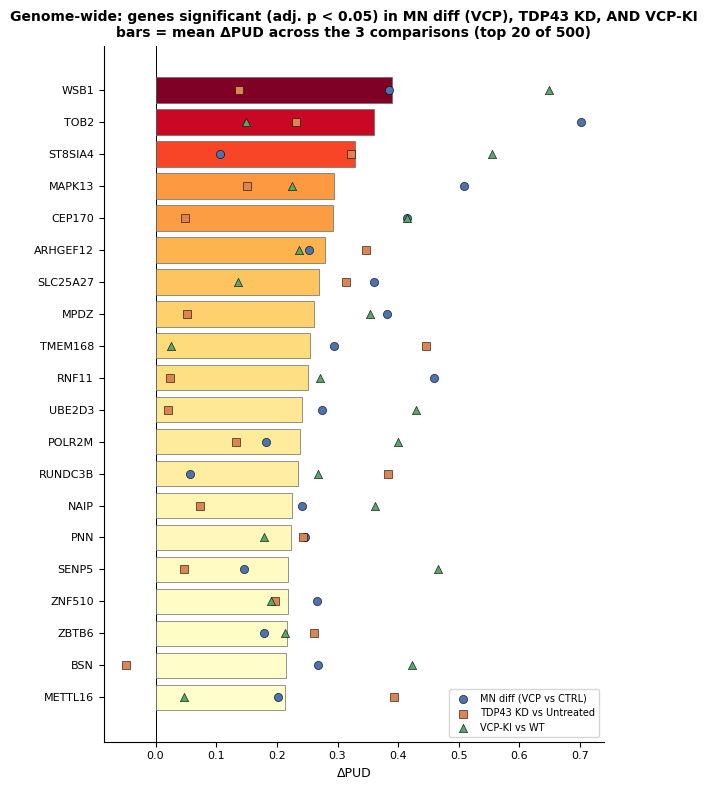

In [55]:
# ── Plot: mean ΔPUD (bar) with the 3 individual comparison values overlaid ──
top_n_plot = 20
df_plot_shared = top_shared_genes.head(top_n_plot).sort_values("mean_dPUD")

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_shared))))
norm = mcolors.Normalize(vmin=df_plot_shared["mean_dPUD"].min(), vmax=df_plot_shared["mean_dPUD"].max())
cmap = plt.cm.YlOrRd
ax.barh(df_plot_shared["gene"], df_plot_shared["mean_dPUD"], color=cmap(norm(df_plot_shared["mean_dPUD"])),
        edgecolor="dimgray", linewidth=0.5, zorder=2, label="_nolegend_")

marker_style = {
    "dPUD_MNdiff_VCP": dict(marker="o", color="#4C72B0", label="MN diff (VCP vs CTRL)"),
    "dPUD_TDP43_KD":   dict(marker="s", color="#DD8452", label="TDP43 KD vs Untreated"),
    "dPUD_VCP_KI":     dict(marker="^", color="#55A868", label="VCP-KI vs WT"),
}
for col, style in marker_style.items():
    ax.scatter(df_plot_shared[col], df_plot_shared["gene"], marker=style["marker"], color=style["color"],
               edgecolor="black", linewidth=0.4, s=35, zorder=3, label=style["label"])

ax.axvline(0, color="black", lw=0.7, zorder=1)
ax.set_xlabel("ΔPUD", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(
    f"Genome-wide: genes significant (adj. p < 0.05) in MN diff (VCP), TDP43 KD, AND VCP-KI\nbars = mean ΔPUD across the 3 comparisons (top {top_n_plot} of {top_n_shared})",
    fontsize=10, weight="bold",
)
ax.legend(fontsize=7, loc="lower right", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()

out_dir = os.path.join(figures_subfolder, "MN_VCP_TDP43-KD_VCP-KI_shared_shortening")
os.makedirs(out_dir, exist_ok=True)
save_figure(os.path.join(out_dir, "barplot_top_genes_mean_dPUD_MN_VCP_TDP43-KD_VCP-KI.pdf"),
            legend=f"Genes with a 3'UTR significantly shifted (adj. Fisher p < 0.05) in all three nuclear comparisons, "
                   "MN VCP vs CTRL (D35), TDP-43 KD vs untreated and untreated VCP-KI vs WT, ranked by mean dPUD (among "
                   f"the top {top_n_shared}, those with mean dPUD >= 0.15): the top {top_n_plot}. Bar = mean dPUD, "
                   "markers = dPUD in each comparison.")
plt.show()


Querying STRING for the top 95 shared genes...
0 GO Process terms


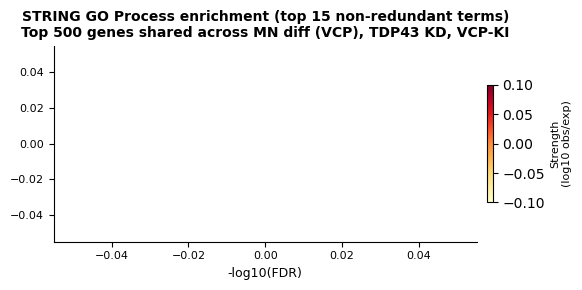

In [56]:
# ── GO Biological Process enrichment (STRING ORA, curated) on the top 200
# genes shared across all three comparisons ──────────────────────────────────
top_shared_gene_list = sorted(top_shared_genes["gene"].unique())
print(f"Querying STRING for the top {len(top_shared_gene_list)} shared genes...")
raw_top_shared = add_strength_and_signal(get_string_enrichment(top_shared_gene_list))
df_top_shared_go = to_pathways_format(raw_top_shared[raw_top_shared["category"] == "Process"])
df_top_shared_go = df_top_shared_go[df_top_shared_go["background gene count"] < 10000]
print(f"{len(df_top_shared_go)} GO Process terms")

top_n_shared_bar = 15
df_plot_top_shared = select_top_nonredundant(df_top_shared_go, raw_top_shared, top_n=top_n_shared_bar, bg_threshold=10000)
df_plot_top_shared = df_plot_top_shared.sort_values("strength")

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_top_shared))))
norm = mcolors.Normalize(vmin=0, vmax=df_plot_top_shared["strength"].max())
cmap = plt.cm.YlOrRd
ax.barh(
    df_plot_top_shared["term description"],
    -np.log10(df_plot_top_shared["false discovery rate"]),
    color=cmap(norm(df_plot_top_shared["strength"])),
    edgecolor="dimgray", linewidth=0.5,
)
ax.set_xlabel("-log10(FDR)", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(f"STRING GO Process enrichment (top {top_n_shared_bar} non-redundant terms)\nTop {top_n_shared} genes shared across MN diff (VCP), TDP43 KD, VCP-KI", fontsize=10, weight="bold")
sns.despine(ax=ax)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Strength\n(log10 obs/exp)", fontsize=8)
plt.tight_layout()

save_figure(os.path.join(out_dir, "barplot_GO_BP_genes_shortened_in_MN_VCP_TDP43-KD_VCP-KI.pdf"),
            legend=f"STRING GO Biological Process enrichment of the genes shortened in all three nuclear comparisons "
                   "(MN VCP, TDP-43 KD, VCP-KI; adj. p < 0.05 in each; mean dPUD >= 0.15 among the top "
                   f"{top_n_shared} by mean dPUD): top "
                   f"{top_n_shared_bar} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed). Bar = -log10(FDR), colour = strength.")
plt.show()


<a id="shared-2way"></a>
## Genes shortened across MN VCP and VCP-KI (2-way)

Same analysis as the 3-way one, without the TDP-43 KD.

Saved in `MN_VCP_and_VCP-KI_shared_shortening/`: `barplot_top_genes_mean_dPUD_MN_VCP_VCP-KI.pdf` and `barplot_GO_BP_genes_shortened_in_MN_VCP_VCP-KI.pdf`.

In [57]:
# ── Genome-wide: mean ΔPUD across TWO comparisons (MN diff VCP, VCP-KI),
# significant in both — same as the 3-way analysis above, minus TDP43 KD ─────
#
# Reuses get_pud_shift() defined above.
shift_mndiff_2way = get_pud_shift(df_mn, "gene", "PUD_D35_Nuclear_Wildtype", "PUD_D35_Nuclear_VCP",
                                   "adjusted_fisher_pvalue_D35_Nuclear_Wildtype_D35_Nuclear_VCP", "MNdiff_VCP")
shift_ki_2way = get_pud_shift(df_ki, "gene", "PUD_Untreated_WT_Nuc", "PUD_Untreated_VCP_KI_Nuc",
                               "adjusted_fisher_pvalue_Untreated_WT_Nuc_Untreated_VCP_KI_Nuc", "VCP_KI")

two_way = shift_mndiff_2way.merge(shift_ki_2way, on="gene", how="inner")
print(f"Genes tested in both comparisons: {len(two_way)}")

two_way_sig = two_way[two_way["sig_MNdiff_VCP"] & two_way["sig_VCP_KI"]].copy()
print(f"Significant (adj. p < 0.05) in BOTH comparisons: {len(two_way_sig)}")

two_way_sig["mean_dPUD"] = two_way_sig[["dPUD_MNdiff_VCP", "dPUD_VCP_KI"]].mean(axis=1)
two_way_sig = two_way_sig.sort_values("mean_dPUD", ascending=False)

top_n_shared_2way = 200
# top_shared_genes_2way = two_way_sig.head(top_n_shared_2way).copy()
top_shared_genes_2way = two_way_sig[two_way_sig['mean_dPUD'] >= 0.15]

print(f"Top {len(top_shared_genes_2way)} genes by mean ΔPUD")
if "NEFL" in top_shared_genes_2way["gene"].values:
    rank = top_shared_genes_2way.reset_index(drop=True)
    print(f"  (NEFL included — rank {rank[rank['gene'] == 'NEFL'].index[0] + 1})")

display(top_shared_genes_2way[["gene", "dPUD_MNdiff_VCP", "dPUD_VCP_KI", "mean_dPUD"]].head(20))



Genes tested in both comparisons: 6757
Significant (adj. p < 0.05) in BOTH comparisons: 2472
Top 309 genes by mean ΔPUD
  (NEFL included — rank 217)


,gene,dPUD_MNdiff_VCP,dPUD_VCP_KI,mean_dPUD
6083,UBQLN2,0.552307,0.505801,0.529054
6310,WSB1,0.385076,0.647846,0.516461
5825,TOB2,0.701838,0.149334,0.425586
920,CEP170,0.415379,0.413926,0.414653
3202,MPDZ,0.381271,0.353533,0.367402
2991,MAPK13,0.508210,0.224376,0.366293
4617,RNF11,0.458725,0.270470,0.364598
101,ADGRL2,0.366861,0.351941,0.359401
6046,UBE2D3,0.274483,0.430134,0.352309
5688,TMBIM6,0.383486,0.313241,0.348363


In [58]:
top_shared_genes_2way[top_shared_genes_2way['gene'] == 'NEFL']

,gene,dPUD_MNdiff_VCP,adjpval_MNdiff_VCP,sig_MNdiff_VCP,dPUD_VCP_KI,adjpval_VCP_KI,sig_VCP_KI,mean_dPUD
3448,NEFL,0.13859,0.0,True,0.202909,0.0,True,0.17075


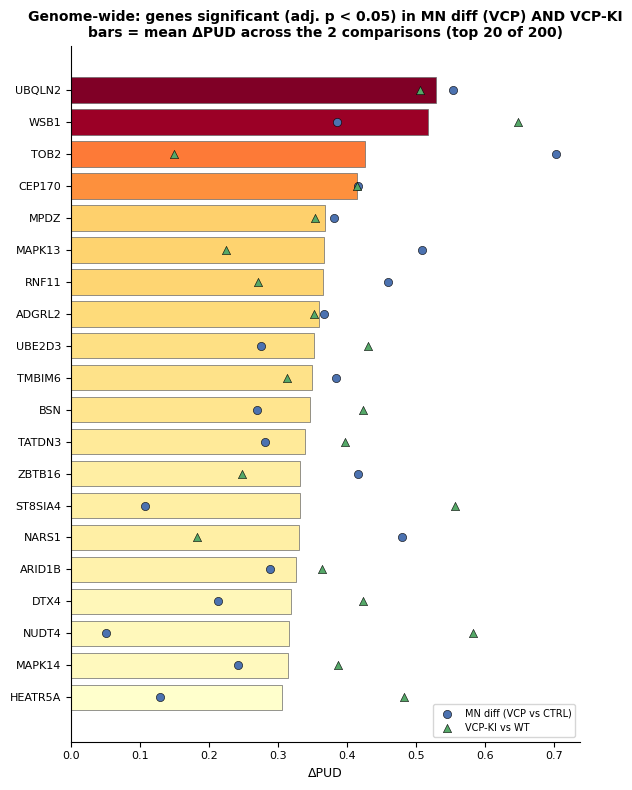

In [59]:
# ── Plot: mean ΔPUD (bar) with the 2 individual comparison values overlaid ──
top_n_plot_2way = 20
df_plot_shared_2way = top_shared_genes_2way.head(top_n_plot_2way).sort_values("mean_dPUD")

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_shared_2way))))
norm = mcolors.Normalize(vmin=df_plot_shared_2way["mean_dPUD"].min(), vmax=df_plot_shared_2way["mean_dPUD"].max())
cmap = plt.cm.YlOrRd
ax.barh(df_plot_shared_2way["gene"], df_plot_shared_2way["mean_dPUD"], color=cmap(norm(df_plot_shared_2way["mean_dPUD"])),
        edgecolor="dimgray", linewidth=0.5, zorder=2, label="_nolegend_")

marker_style_2way = {
    "dPUD_MNdiff_VCP": dict(marker="o", color="#4C72B0", label="MN diff (VCP vs CTRL)"),
    "dPUD_VCP_KI":     dict(marker="^", color="#55A868", label="VCP-KI vs WT"),
}
for col, style in marker_style_2way.items():
    ax.scatter(df_plot_shared_2way[col], df_plot_shared_2way["gene"], marker=style["marker"], color=style["color"],
               edgecolor="black", linewidth=0.4, s=35, zorder=3, label=style["label"])

ax.axvline(0, color="black", lw=0.7, zorder=1)
ax.set_xlabel("ΔPUD", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(
    f"Genome-wide: genes significant (adj. p < 0.05) in MN diff (VCP) AND VCP-KI\nbars = mean ΔPUD across the 2 comparisons (top {top_n_plot_2way} of {top_n_shared_2way})",
    fontsize=10, weight="bold",
)
ax.legend(fontsize=7, loc="lower right", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()

save_figure(os.path.join(figures_subfolder, "MN_VCP_and_VCP-KI_shared_shortening", "barplot_top_genes_mean_dPUD_MN_VCP_VCP-KI.pdf"),
            legend=f"Genes with a 3'UTR significantly shifted (adj. Fisher p < 0.05) in both nuclear comparisons, MN "
                   "VCP vs CTRL (D35) and untreated VCP-KI vs WT, with mean dPUD >= 0.15: the top "
                   f"{top_n_plot_2way} by mean dPUD. Bar = mean dPUD, markers = dPUD in each comparison.")
plt.show()


Querying STRING for the top 309 shared genes (2-way)...
0 GO Process terms


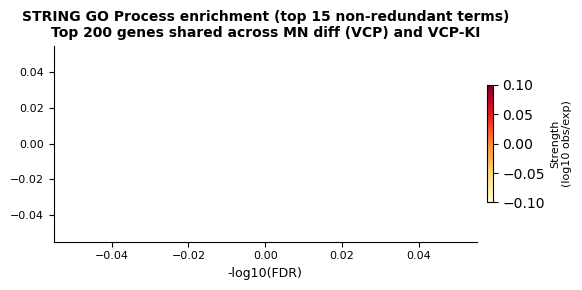

In [60]:
# ── GO Biological Process enrichment (STRING ORA, curated) on the top 200
# genes shared across MN diff (VCP) and VCP-KI only ──────────────────────────
top_shared_gene_list_2way = sorted(top_shared_genes_2way["gene"].unique())
print(f"Querying STRING for the top {len(top_shared_gene_list_2way)} shared genes (2-way)...")
raw_top_shared_2way = add_strength_and_signal(get_string_enrichment(top_shared_gene_list_2way))
df_top_shared_go_2way = to_pathways_format(raw_top_shared_2way[raw_top_shared_2way["category"] == "Process"])
df_top_shared_go_2way = df_top_shared_go_2way[df_top_shared_go_2way["background gene count"] < 10000]
print(f"{len(df_top_shared_go_2way)} GO Process terms")

top_n_shared_bar_2way = 15
df_plot_top_shared_2way = select_top_nonredundant(df_top_shared_go_2way, raw_top_shared_2way, top_n=top_n_shared_bar_2way, bg_threshold=10000)
df_plot_top_shared_2way = df_plot_top_shared_2way.sort_values("strength")

fig, ax = plt.subplots(figsize=(6, max(3, 0.4 * len(df_plot_top_shared_2way))))
norm = mcolors.Normalize(vmin=0, vmax=df_plot_top_shared_2way["strength"].max())
cmap = plt.cm.YlOrRd
ax.barh(
    df_plot_top_shared_2way["term description"],
    -np.log10(df_plot_top_shared_2way["false discovery rate"]),
    color=cmap(norm(df_plot_top_shared_2way["strength"])),
    edgecolor="dimgray", linewidth=0.5,
)
ax.set_xlabel("-log10(FDR)", fontsize=9)
ax.tick_params(labelsize=8)
ax.set_title(f"STRING GO Process enrichment (top {top_n_shared_bar_2way} non-redundant terms)\nTop {top_n_shared_2way} genes shared across MN diff (VCP) and VCP-KI", fontsize=10, weight="bold")
sns.despine(ax=ax)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("Strength\n(log10 obs/exp)", fontsize=8)
plt.tight_layout()

save_figure(os.path.join(figures_subfolder, "MN_VCP_and_VCP-KI_shared_shortening", "barplot_GO_BP_genes_shortened_in_MN_VCP_VCP-KI.pdf"),
            legend=f"STRING GO Biological Process enrichment of all the genes shortened in both MN VCP (D35) and "
                   "VCP-KI (nuclear; adj. p < 0.05 in each, mean dPUD >= 0.15)"
                   f": top {top_n_shared_bar_2way} non-redundant terms (ranked by strength, a term is skipped when its gene set overlaps a kept term with Jaccard >= 0.5; terms with >= 10,000 background genes removed). Bar = -log10(FDR), colour = strength. "
                   "")
plt.show()
